# Modelos TVAR y VLSTAR de **3 regímenes** con impp_usa, sin cappeo (1950–2023)

Complemento de la notebook de 2 regímenes (`1950_2023_SSTVARS_impp_usa_sin_capped.ipynb`), donde la especificación principal es el TVAR de 2 regímenes con p = 2.

- Mismos datos (`df_ERPT_Arg`, sin cappeo) y mismas variables: `impp_usa`, `E`, `ipc`, `pbird`.
- Rezagos: p = 2 (HQ) y p = 3 (AIC), según la selección hecha en la notebook de 2 regímenes.
- Con 3 regímenes, el número del shock cambiario puede cambiar: cada modelo lo identifica y lo guarda en `shock_...`.
- Archivos de salida con `tvar3` / `vlstar3` en el nombre y sufijo `_sincap`.

In [41]:
source("preparar_dataframes.r")
source("src/sstvars_wrapper_v5.r")
source("src/erpt_historia_v36.R")


[1] "Se creó df_trimestral_crudo"
[1] "Se creó df_Arg"
[1] "Se creó df_ERPT_Arg1"
[1] "Se creó df_ERPT_Arg"
>>> sstvars_wrapper v5 cargado (ind_Student con identificación por no normalidad)
>>> erpt_historia v36 cargada (graficos_con_mediana: referencias por régimen con la mediana)


In [2]:
str(df_ERPT_Arg)
head(rownames(df_ERPT_Arg))

'data.frame':	295 obs. of  11 variables:
 $ año       : num  1950 1950 1950 1951 1951 ...
 $ trimestre : chr  "2ºTr" "3ºTr" "4ºTr" "1ºTr" ...
 $ ipc       : num  0.071 0.0485 0.0686 0.0228 0.1579 ...
 $ E         : num  0 0.18226 0.25964 0.00141 0.00486 ...
 $ Ebc       : num  0 0.18226 0.25964 0.00141 0.00486 ...
 $ pbird     : num  -0.0164 0.0377 -0.013 0.0271 0.0121 ...
 $ impp_usa  : num  0.0248 0.082 0.084 0.0861 0.0595 ...
 $ Psoja_USA : num  0.2095 -0.0487 -0.0457 0.2223 0.0164 ...
 $ Pmaíz_USA : num  0.1235 0.087 -0.0306 0.1233 0.0291 ...
 $ Ptrigo_USA: num  0.0583 -0.0464 -0.0068 0.0913 -0.0141 ...
 $ TOTfmi    : num  NA NA NA NA NA NA NA NA NA NA ...


[1] "2" "3" "4" "5" "6" "7"

## TVAR, 3 regímenes, p = 2

Se cargó exitosamente modelos preguardados  threshold_tvar_2_3_500_fe95048e6fc56ee0513b515ee266b1cc.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , NULL , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


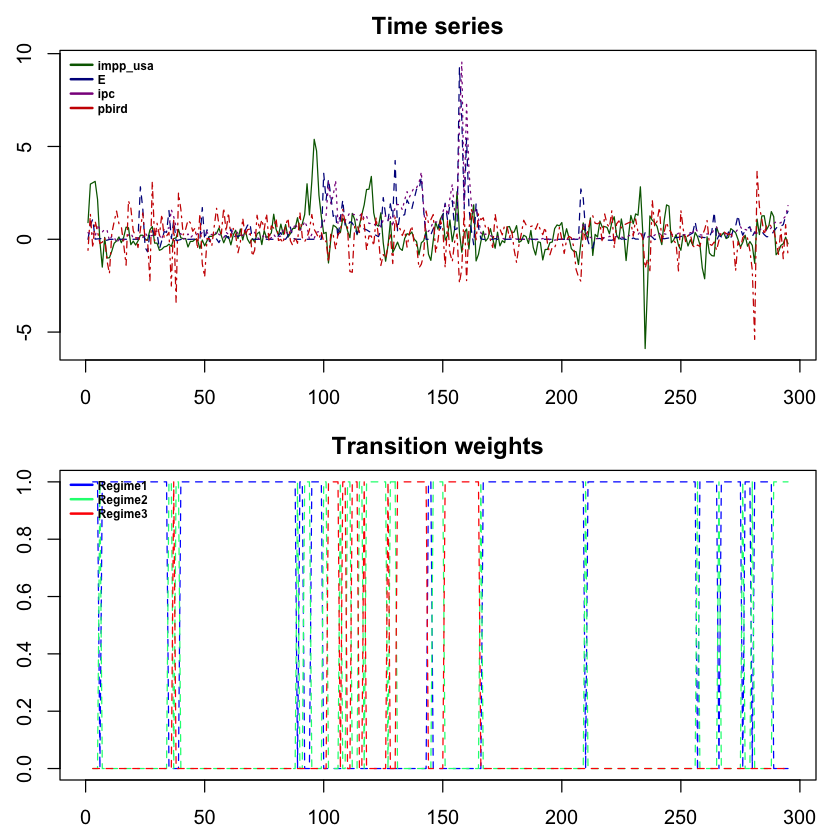

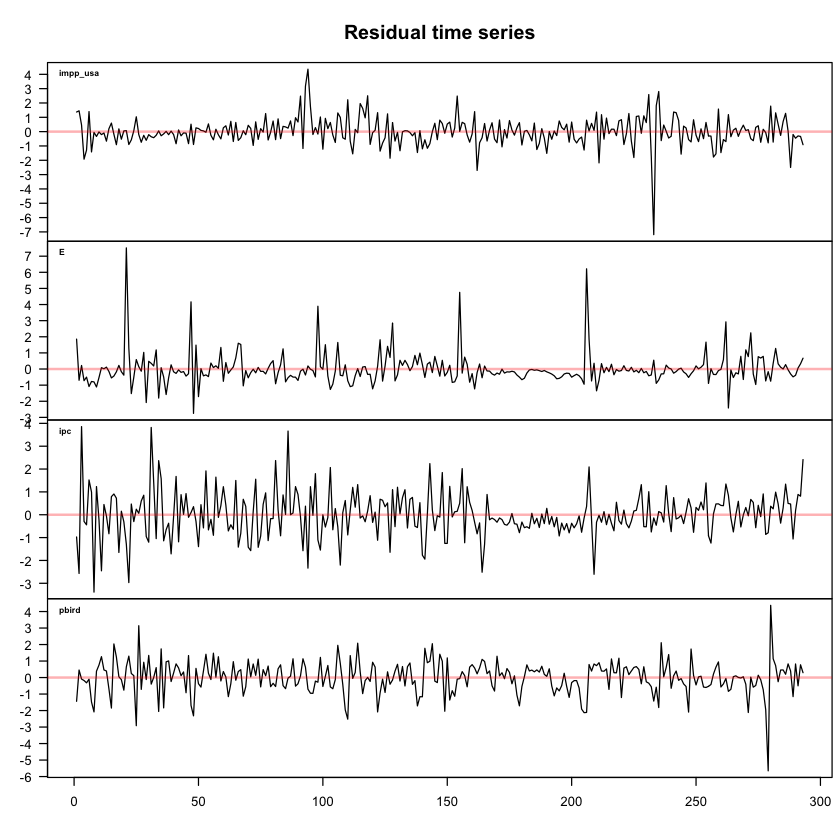

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



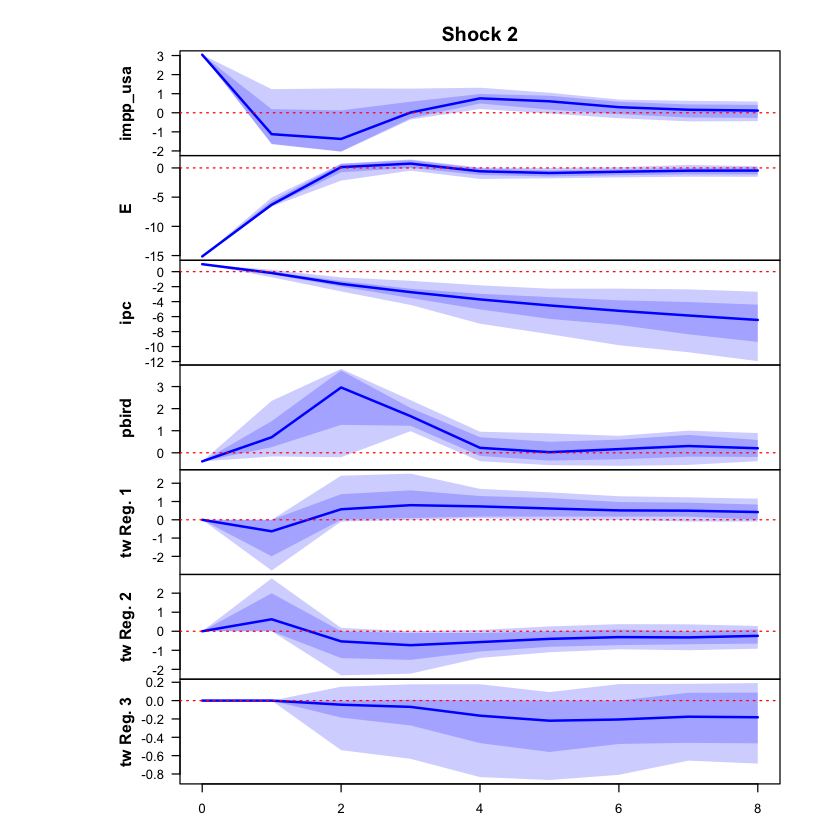

 >>> Linear IRF ( 1  shock units)


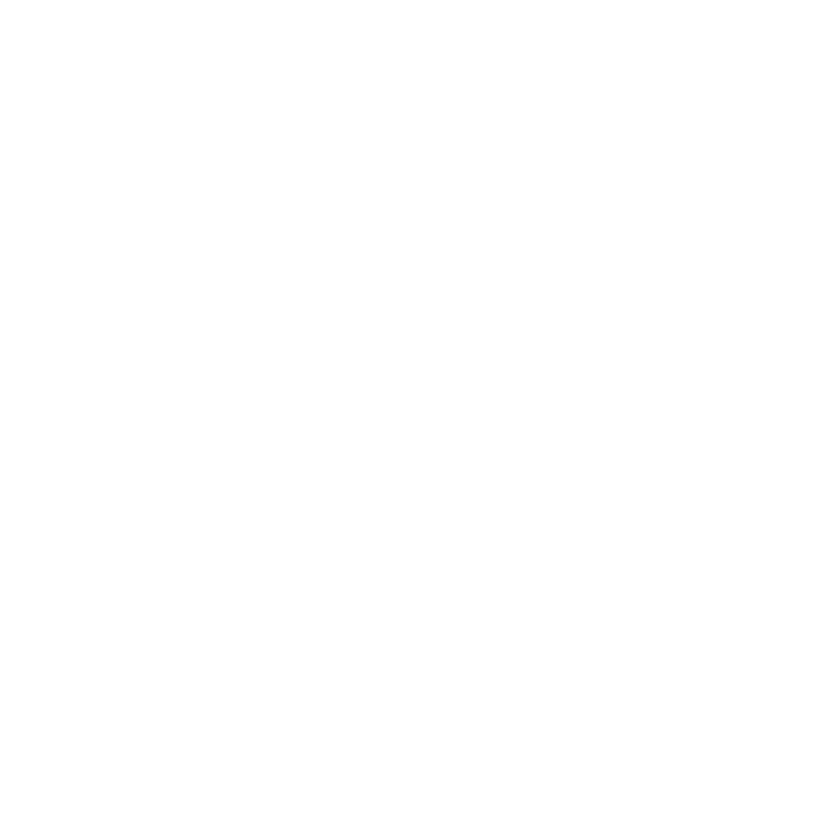

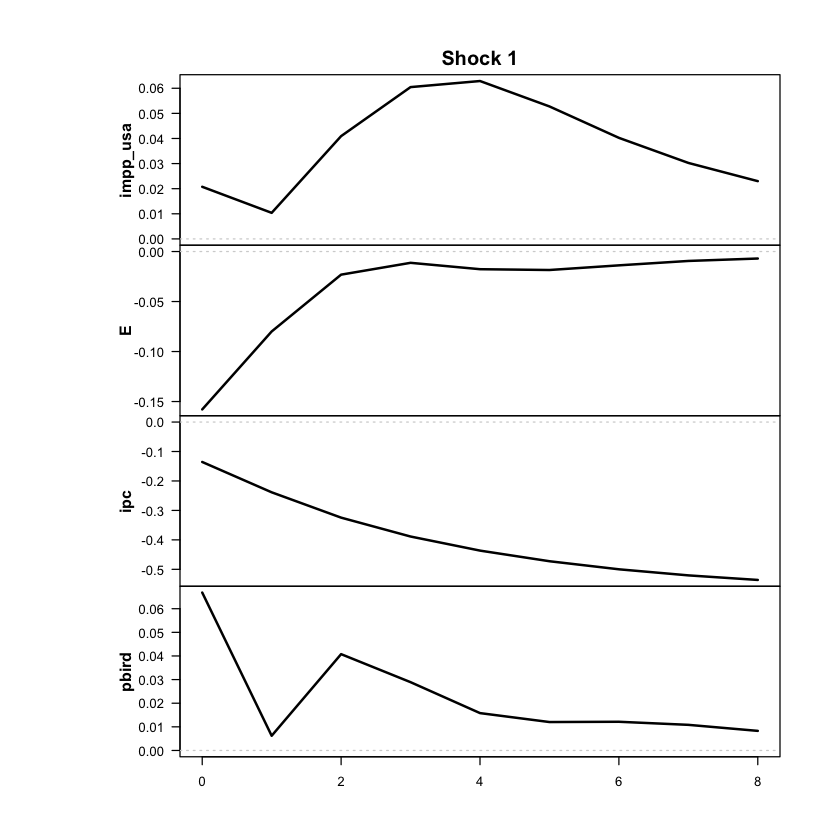

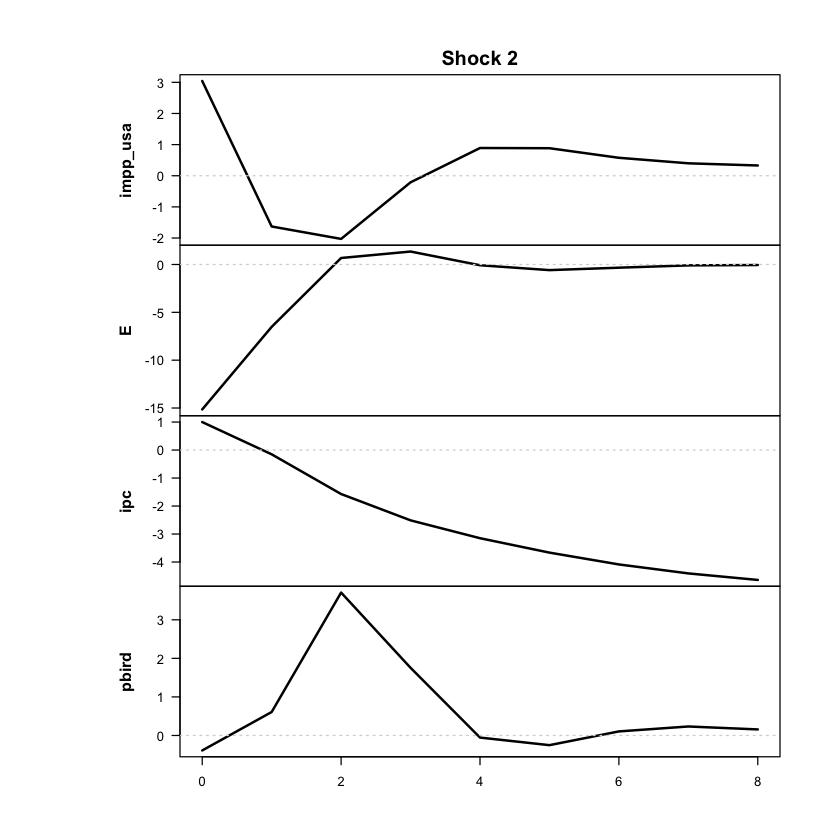

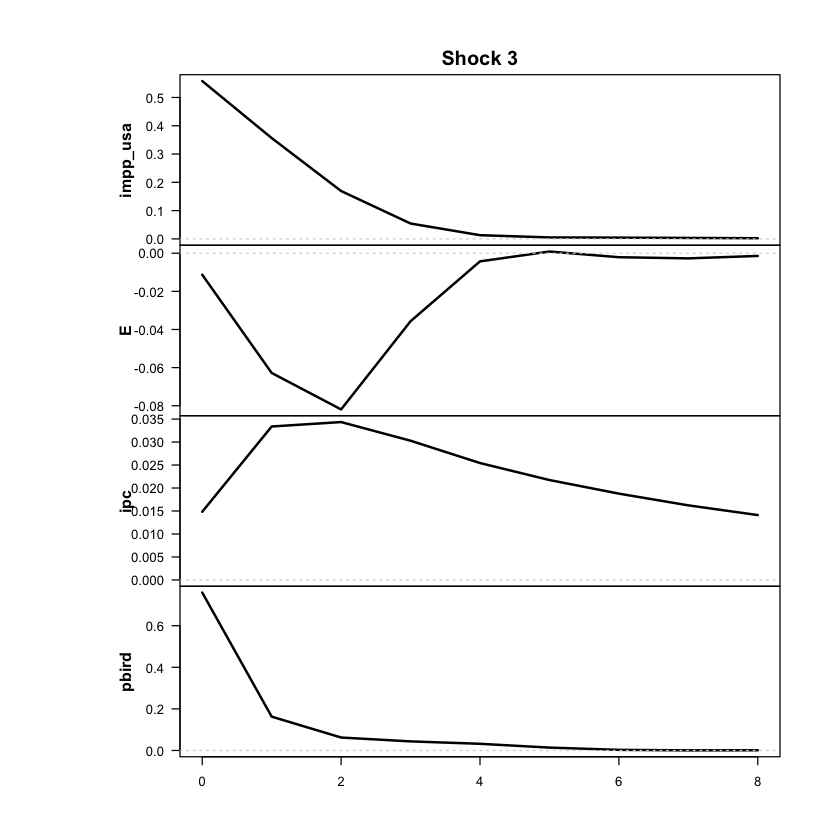

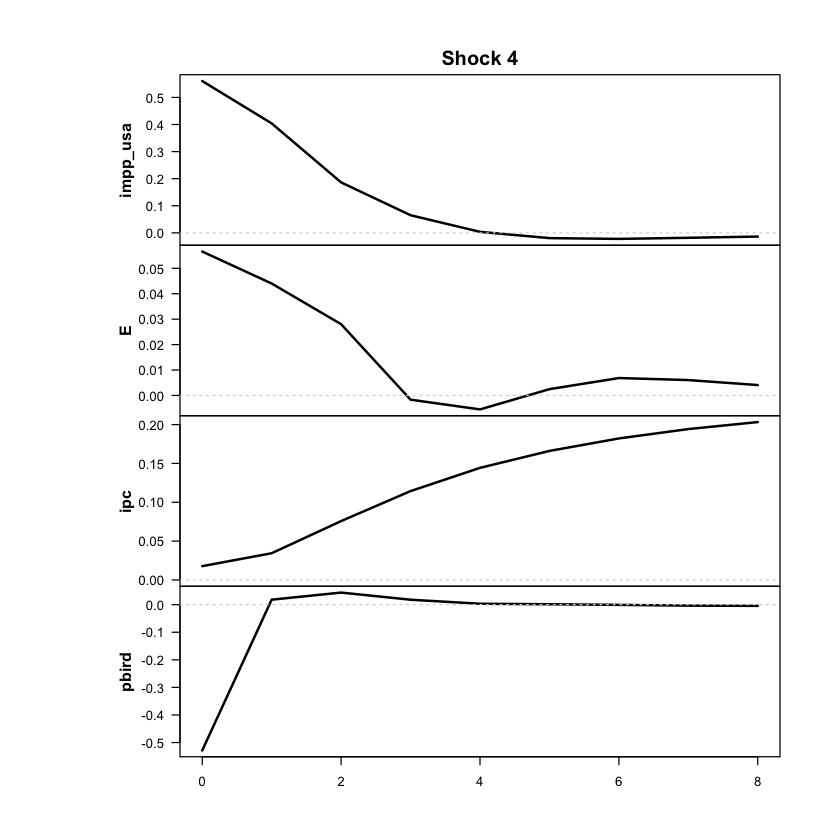

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



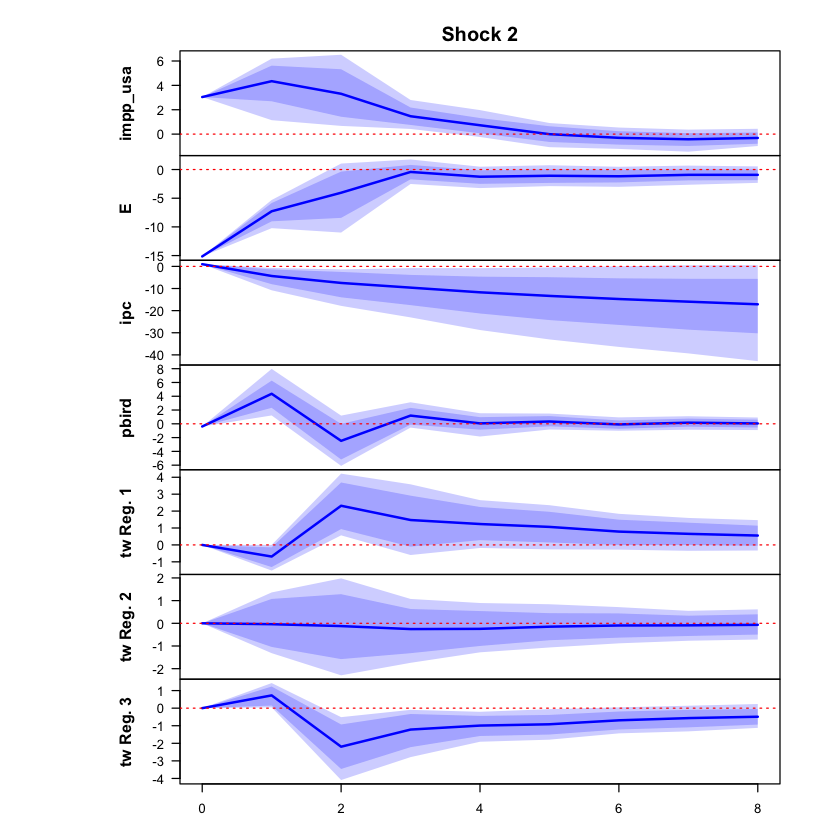

 >>> Linear IRF ( 1  shock units)


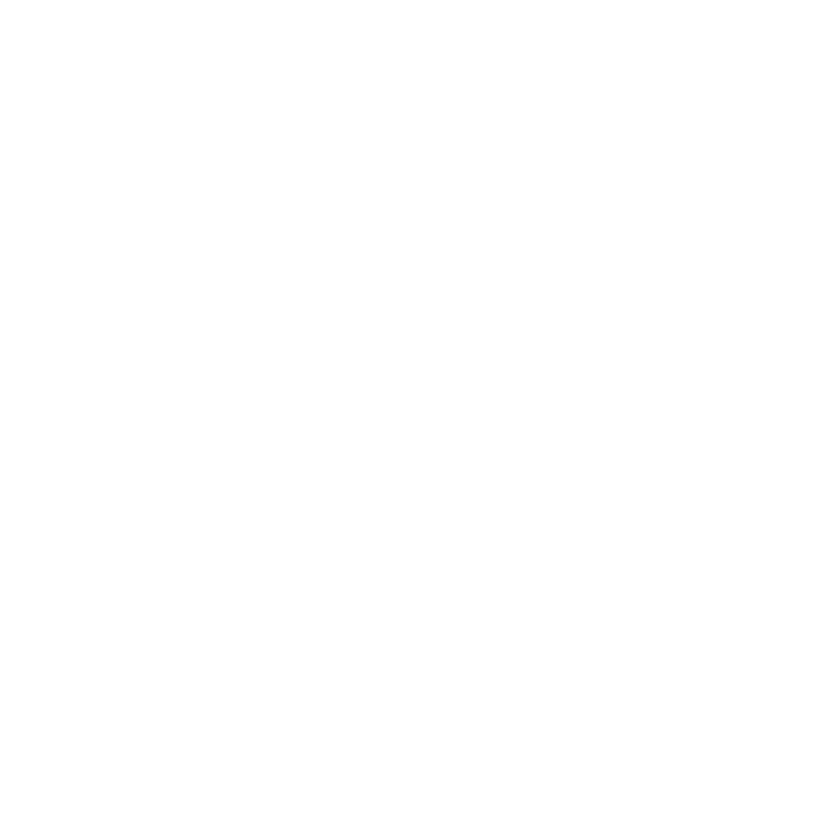

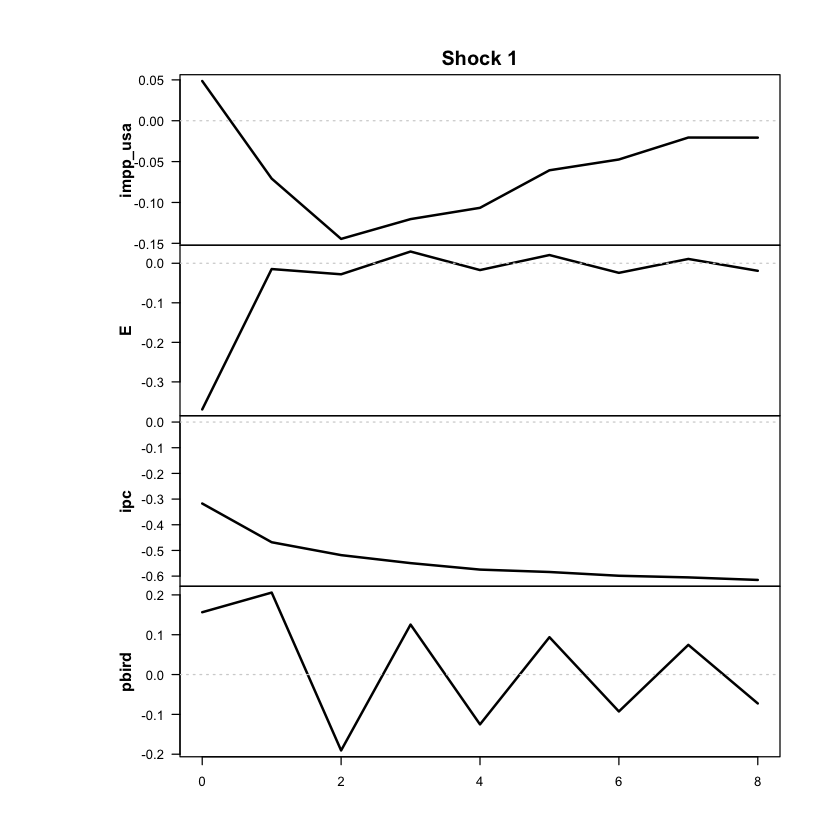

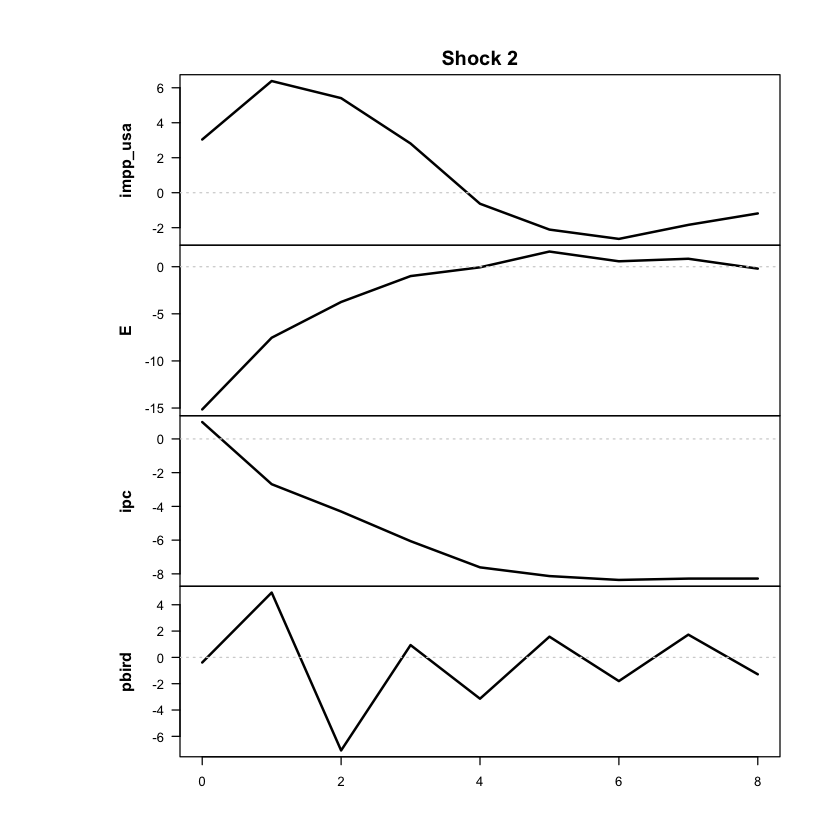

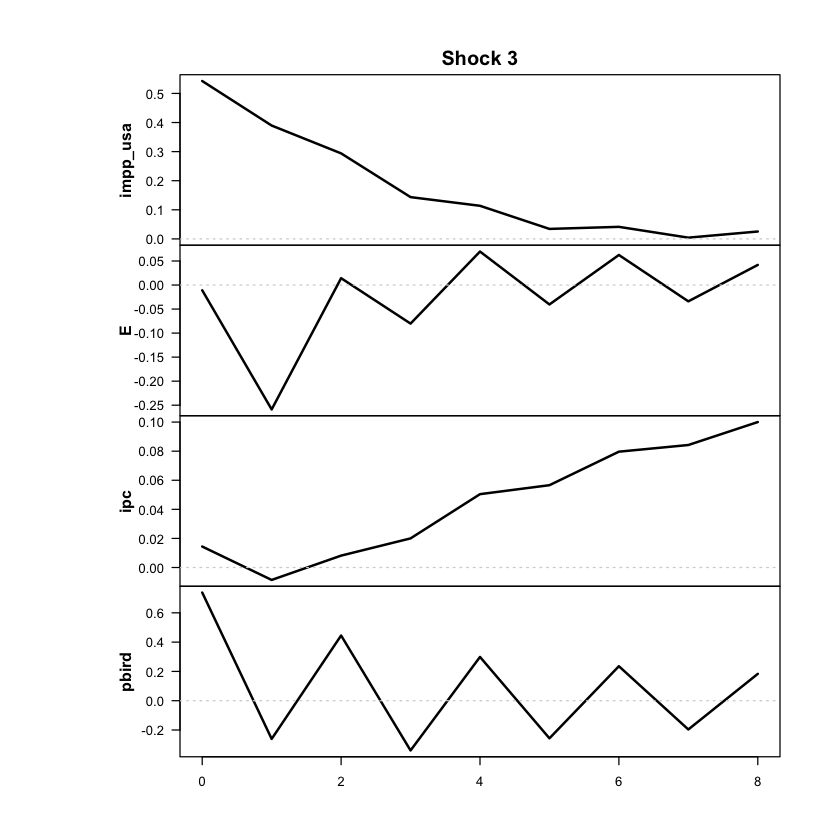

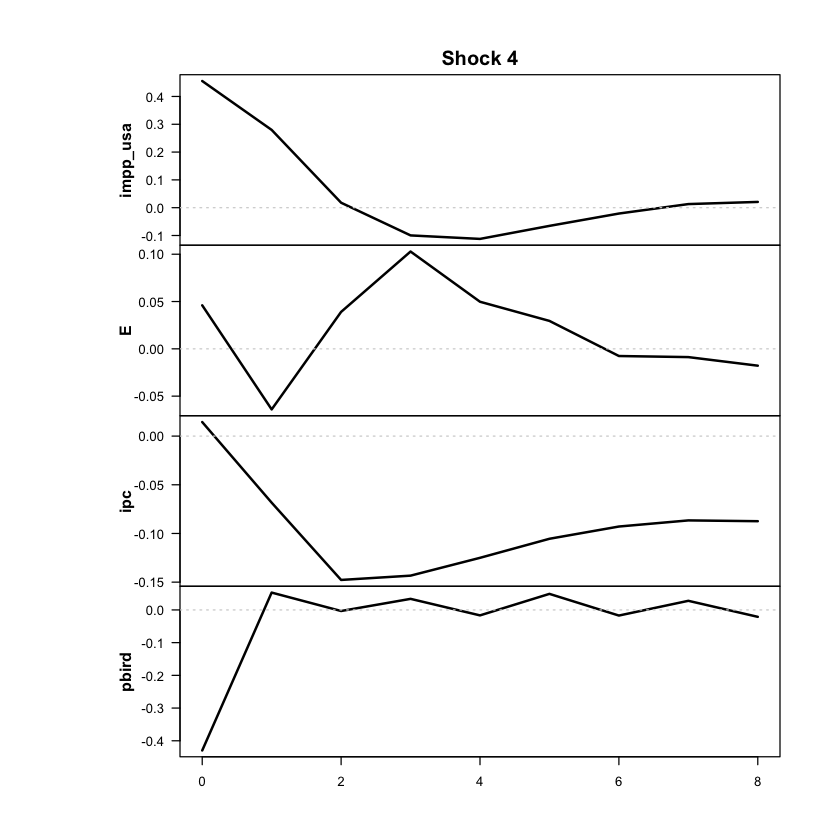

+++++++++ RÉGIMEN  3 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



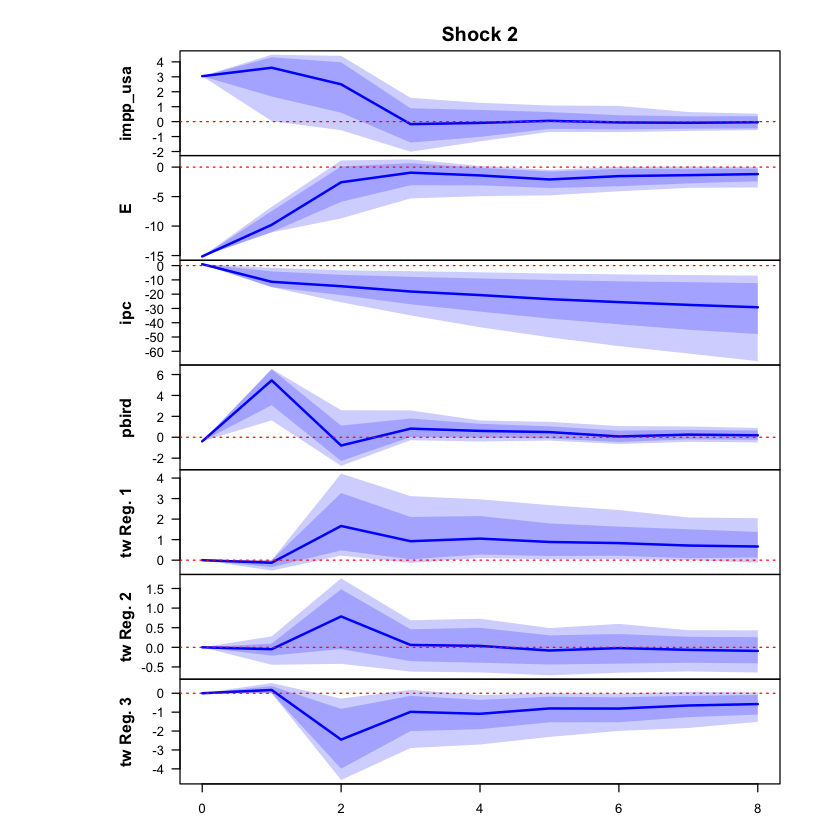

 >>> Linear IRF ( 1  shock units)


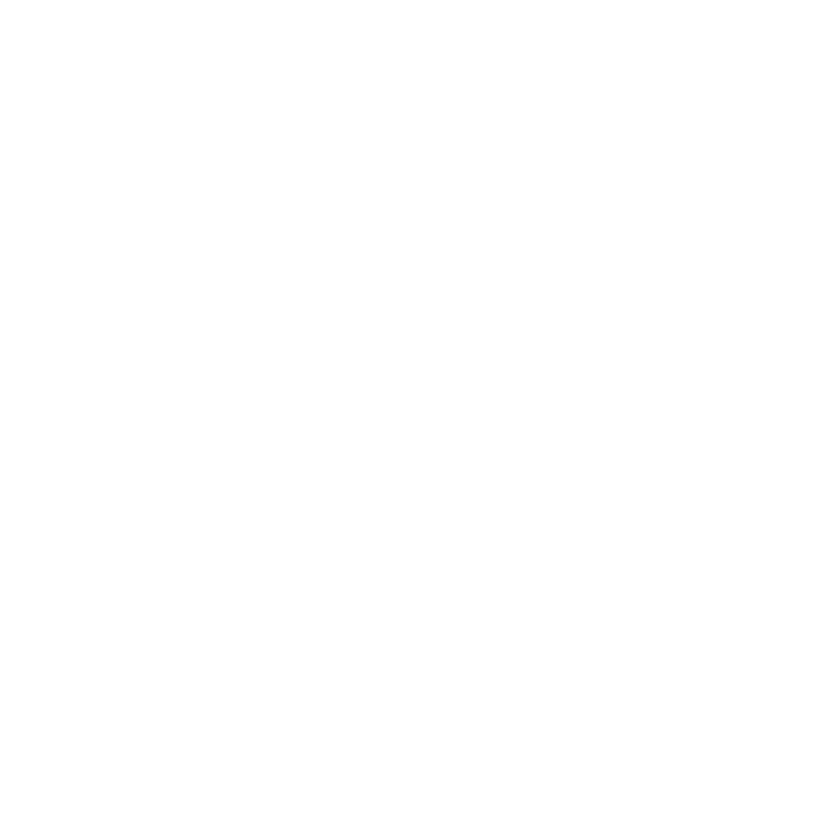

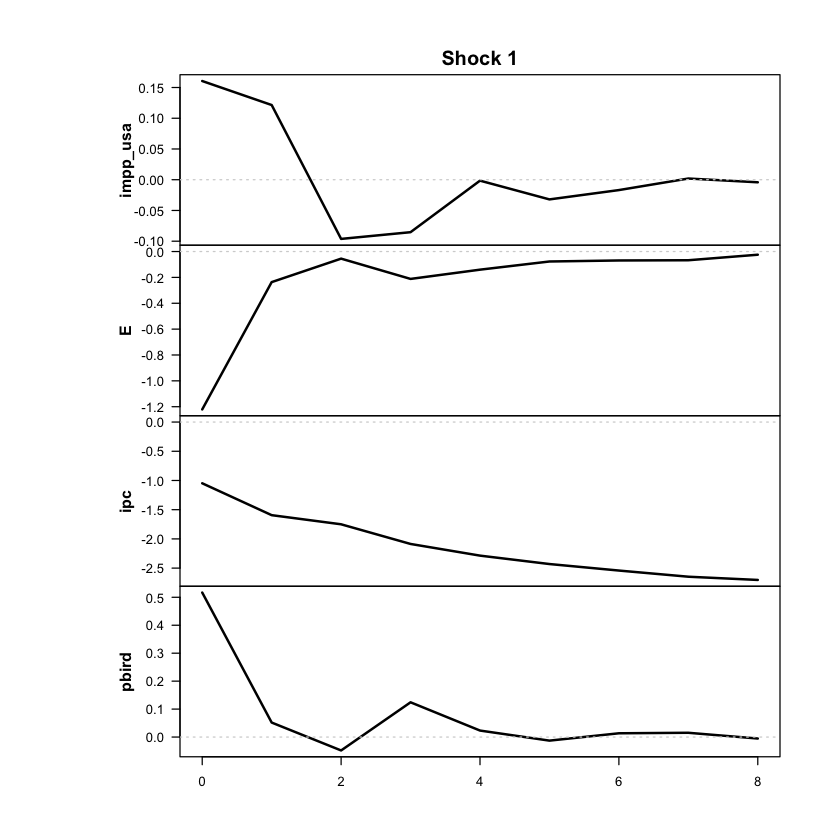

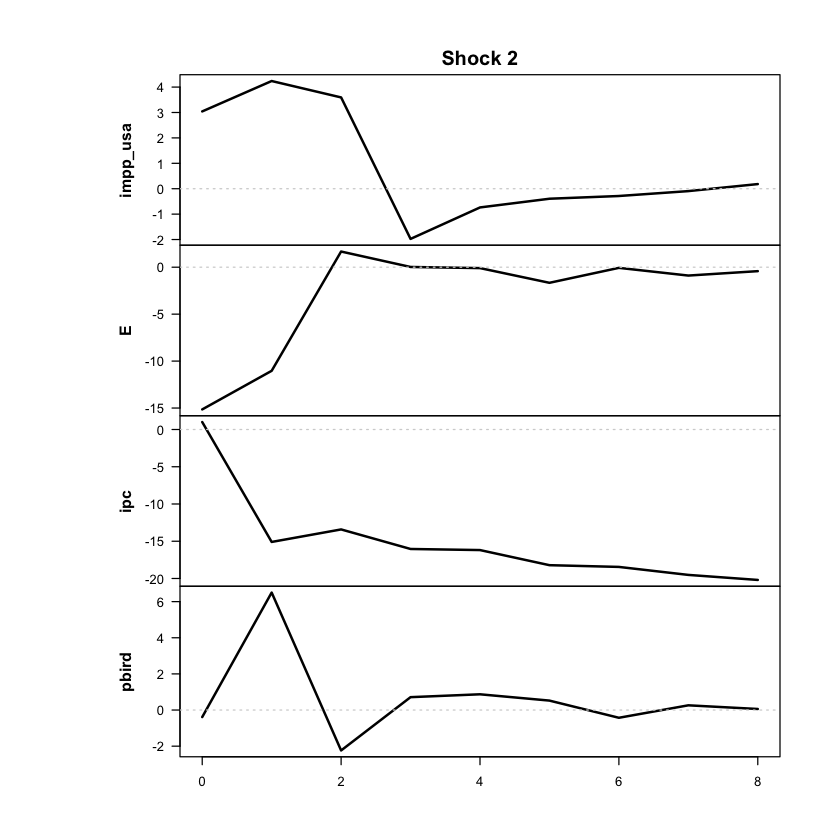

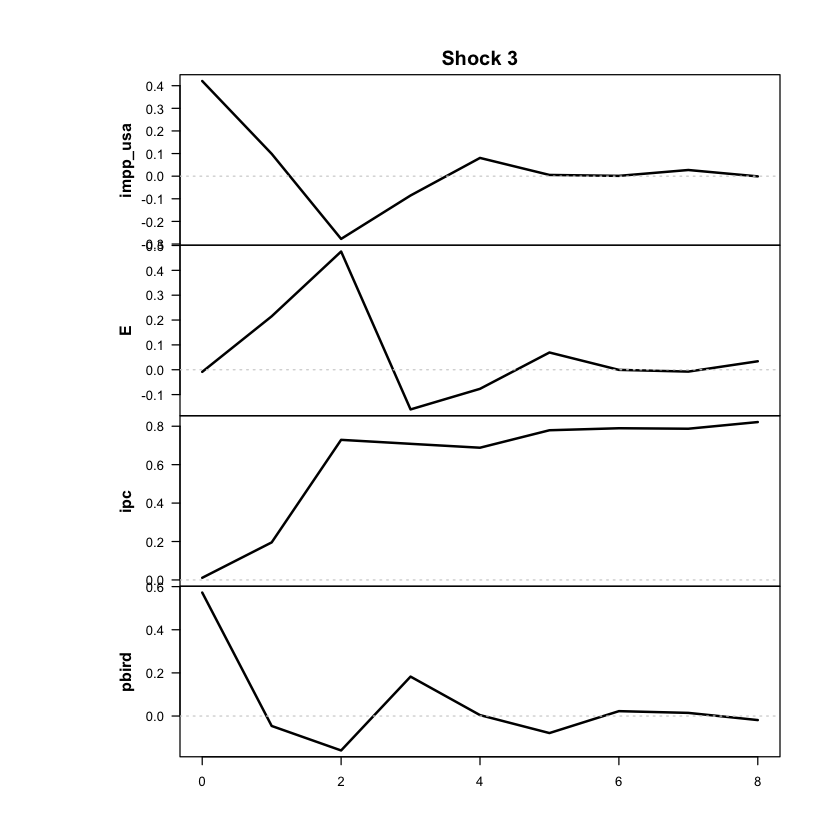

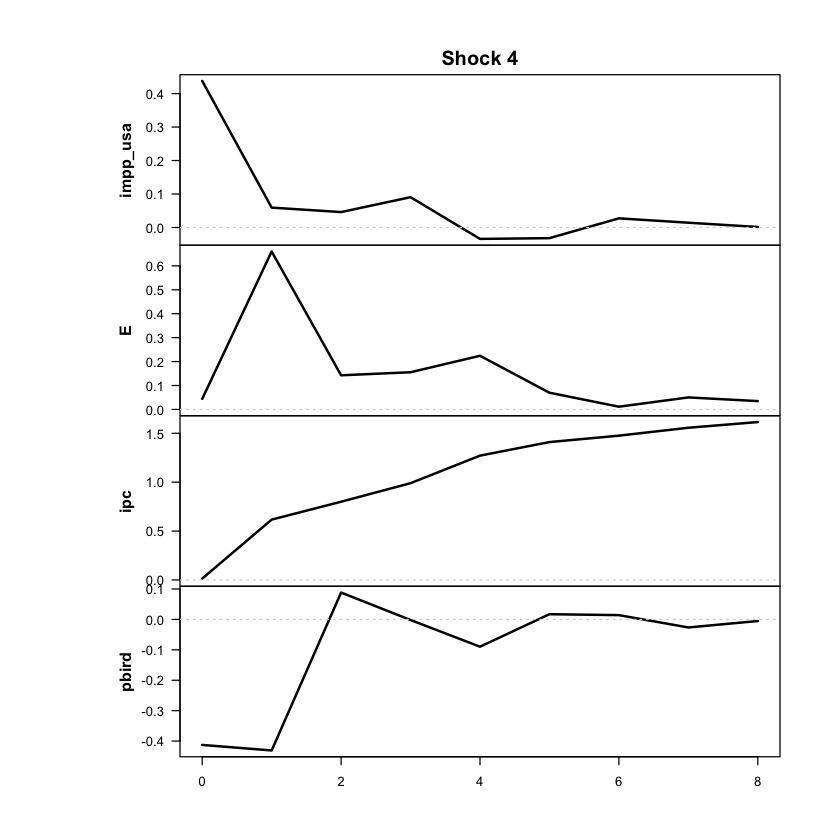

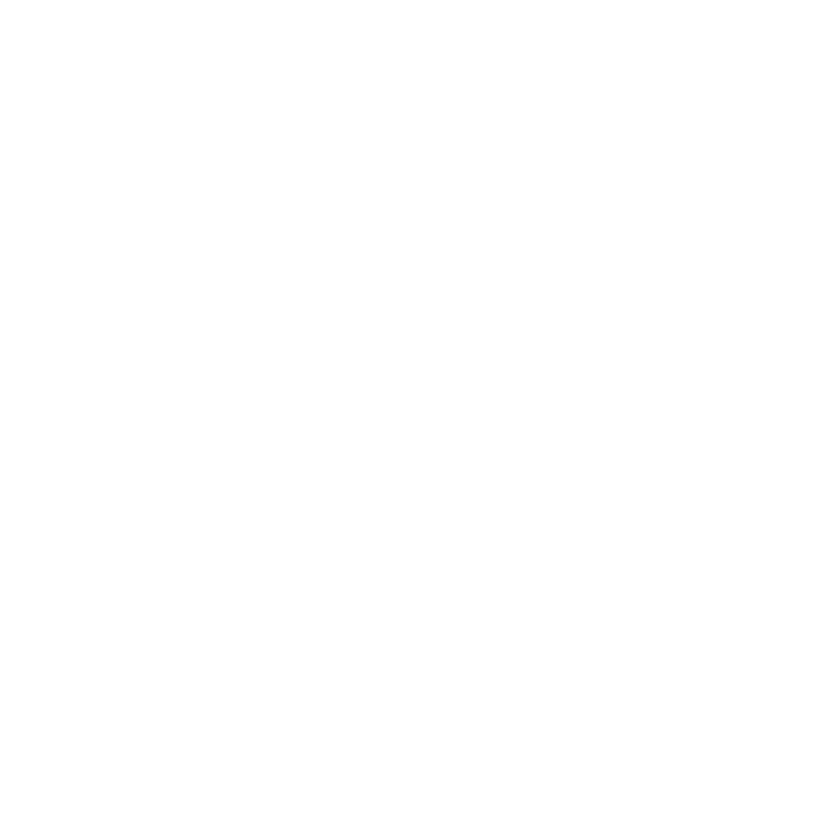

In [ ]:
res <- run_threshold_tvar(
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual' o mensual
  feature_lag = 2,
  n_regimes = 3,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [4]:
ic_tvar3_p2 <- criterios_info(res, "TVAR 3 reg p=2")
print(ic_tvar3_p2)

          modelo regimenes parametros  loglik    AIC     HQ    BIC
1 TVAR 3 reg p=2         3        140 -827.16 1934.3 2140.7 2449.5


In [5]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: threshold | regímenes: 3 | rezagos: 2 
Umbrales: 12.5% trimestral (60% anualizada) | 28.2% trimestral (170% anualizada) 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 206 | régimen 2 = 46 | régimen 3 = 41 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2 Régimen 3
impp_usa      0.59      1.49      0.75
E             3.80     20.25     53.24
ipc           4.70     19.82     58.86
pbird         0.83     -0.26      0.01


In [6]:
explorar_optimos(res, n = 10)
# En un TVAR, umbral_trim_pct y gamma no tienen sentido: mirar solo loglik y las columnas de avisos.

umbral_trim_pct: umbral en % de inflación trimestral (solo VLSTAR)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma trim_reg_alto trim_transicion
             1 -827.16            12.5  1.25            45               0
             2 -827.61            12.3  1.26            46               0
             3 -830.37            12.3  1.23            43               0
             4 -834.62             2.0  0.59           142               0
             5 -838.27            12.3  1.11            39               0
             6 -838.93             1.9  0.59           142               0
             7 -839.22             2.1  0.59           141               0
             8 -840.03             0.7  0.59           165               0
             9 -840.81             3.1  0.58           123               0
            10 -840.86             3.1  0.59           122               0
 raiz

In [7]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

threshold Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 3, d = 4, #parameters = 140, #observations = 293 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Upper threshold: 0.59 
Regime means: 0.18, 0.17, 0.27, 0.28

   Y     phi0          A1                                 A2                  
1 y1 = [ 0.16 ] + [  0.69  0.22 -0.28 -0.03 ] y1.1 + [ -0.14 -0.05 -0.12  0.03
2 y2   [ 0.13 ]   [ -0.02  0.42  0.03 -0.06 ] y2.1   [  0.00 -0.22  0.11 -0.05
3 y3   [ 0.06 ]   [  0.01  0.12  0.62  0.01 ] y3.1   [  0.02  0.00  0.08 -0.02
4 y4   [ 0.27 ]   [  0.14 -0.02 -0.01  0.11 ] y4.1   [  0.00 -0.26  0.01 -0.01
             Omega                     1/2     
1 ] y1.2 + [  0.63  0.00  0.02  0.13 ]     eps1
2 ] y2.2   [  0.00  0.13  0.01 -0.05 ]     eps2
3 ] y3.2   [  0.02  0.01  0.02 -0.01 ]     eps3
4 ] y4.2   [  0.13 -0.05 -0.01  0.86 ]     eps4

Regime 2 
Upper threshold: 1.25 
Regime means:  0.37,  0.88,  0.97, -0.07

   Y      phi0      

In [43]:
shock_tvar3_p2 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Con 3 regímenes el número del shock cambiario puede no ser 2.
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_tvar3_p2 <- 2
shock_tvar3_p2

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0006 -0.0018  0.0154  0.0155
  E        -0.0378  0.0788 -0.0027  0.0135
  ipc      -0.0269 -0.0043  0.0029  0.0035
  pbird     0.0019  0.0002  0.0211 -0.0147

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.72    0.98    0.01    0.07 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.712  -0.055  -1.093   0.260 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 2

### ERPT y gráficos — tvar3 p2

Correr solo si el modelo pasó el diagnóstico (sin avisos, shock cambiario confirmado).

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 8.2%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 3...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0548  0.0030
         1  0.0091 -0.0019
         2  0.0885 -0.0253
         3  0.1475 -0.0379
         4  0.1981 -0.0396
         5  0.2438 -0.0401
         6  0.2852 -0.0417
         7  0.3217 -0.0440
         8  0.3551 -0.0454

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0548  0.0030
         1  0.2501 -0.0328
         2  0.4664 -0.0149
         3  0.5997 -0.0226
         4  0.7320 -0.0240
         5  0.8309 -0.0267
         6  0.9193 -0.0268
         7  0.9944 -0.0280
         8  1.0671 -0.0291

+++ Régimen 3 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0548  0.0030
         1  0.5933 -0.0376
         2  0.7633 -0.0330
         3  0.9615 -0.0393
         4  1.0922 -0.0435
         5

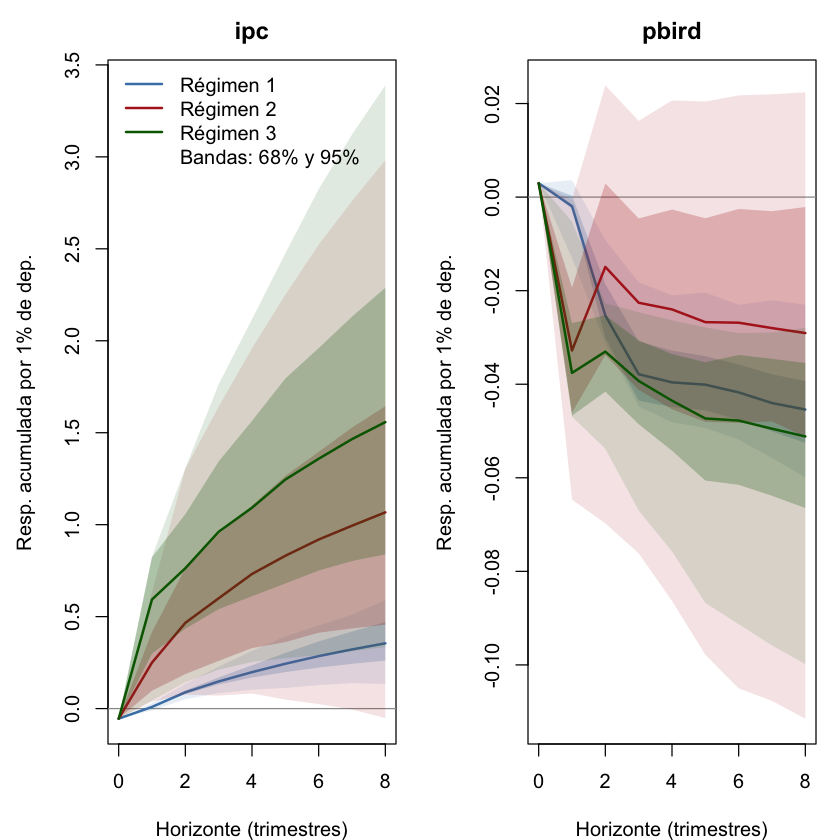

In [44]:
   graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                          shock_num = shock_tvar3_p2, regimenes = 1:3,
                          archivo = "girf_original_impp_usa_tvar3_p2_sincap")

In [45]:
out_impp_usa_tvar3_p2 <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar3_p2)

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 8.2%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 206 | régimen 2 = 46 | régimen 3 = 41 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_1_original reg_2_original reg_3_original
1         0        -0.0548        -0.0548        -0.0548
2         1         0.0096         0.2265         0.6302
3         2         0.0891         0.4021         0.8061
4         3         0.1470         0.5250         1.0235
5         4         0.1987         0.6429         1.1838
6         5         0.2396         0.7521         1.3487
7         6         0.2828         0.8397         1.4775
8         7         0.3201         0.9040         1.6024
9         8         0.3482         0.9715         1.7188

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_1_mediana reg_2_mediana reg_3_mediana
1         0       -0.0548       -0.0548       -0.0548
2         1        0.0083        0

In [46]:
out_impp_usa_tvar3_p2_acum <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar3_p2,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales; en el impacto (régimen 1) deprecia E en 8.2%.

Estimando 293 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 206 | régimen 2 = 46 | régimen 3 = 41 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_1_original reg_2_original reg_3_original
1         0        -0.0548        -0.0548        -0.0548
2         1         0.0068         0.1502         0.3781
3         2         0.0633         0.2249         0.4318
4         3         0.1086         0.2865         0.5210
5         4         0.1426         0.3350         0.5649
6         5         0.1648         0.3759         0.6016
7         6         0.1874         0.4019         0.6247
8         7         0.2076         0.4216         0.6469
9         8         0.2219         0.4388         0.6644

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_1_mediana reg_2_mediana reg_3_mediana
1         0       -0.0548       -0.0548       -0.0548
2         1        0.0058        0

Promedio de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         4          0.143          0.335          0.565
Promedio de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         4          0.199          0.643          1.184


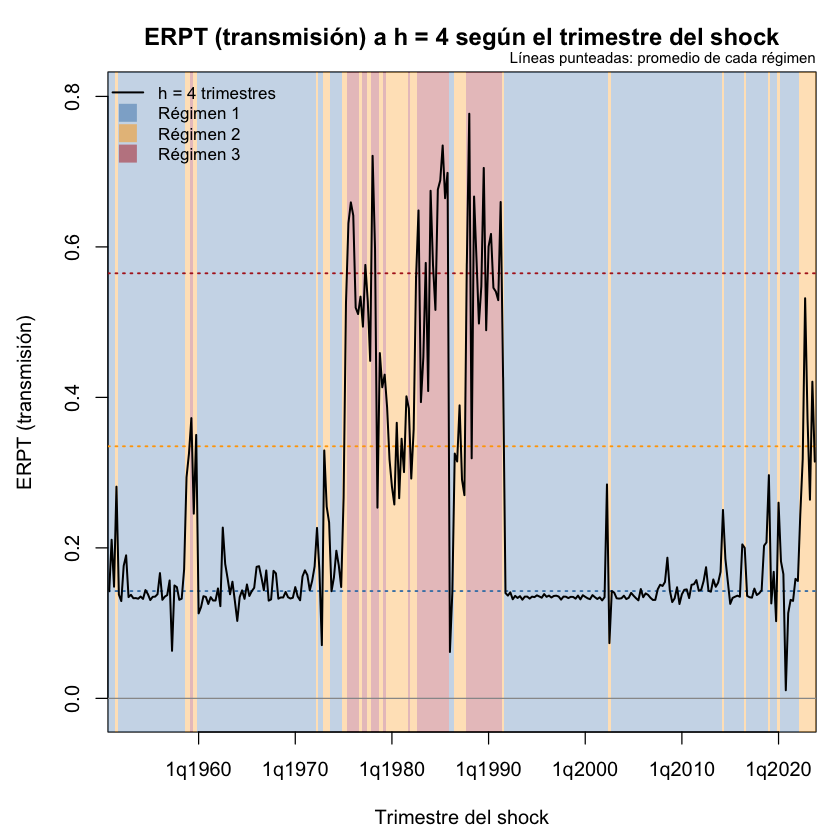

Promedio de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         8          0.222          0.439          0.664


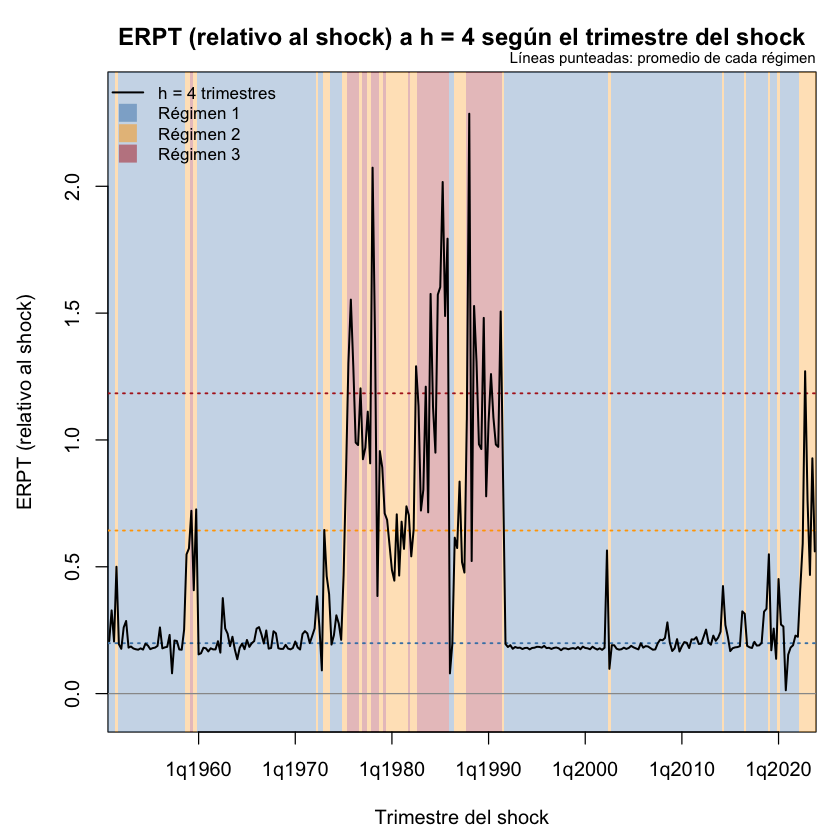

Promedio de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_original reg_2_original reg_3_original
         8          0.348          0.972          1.719


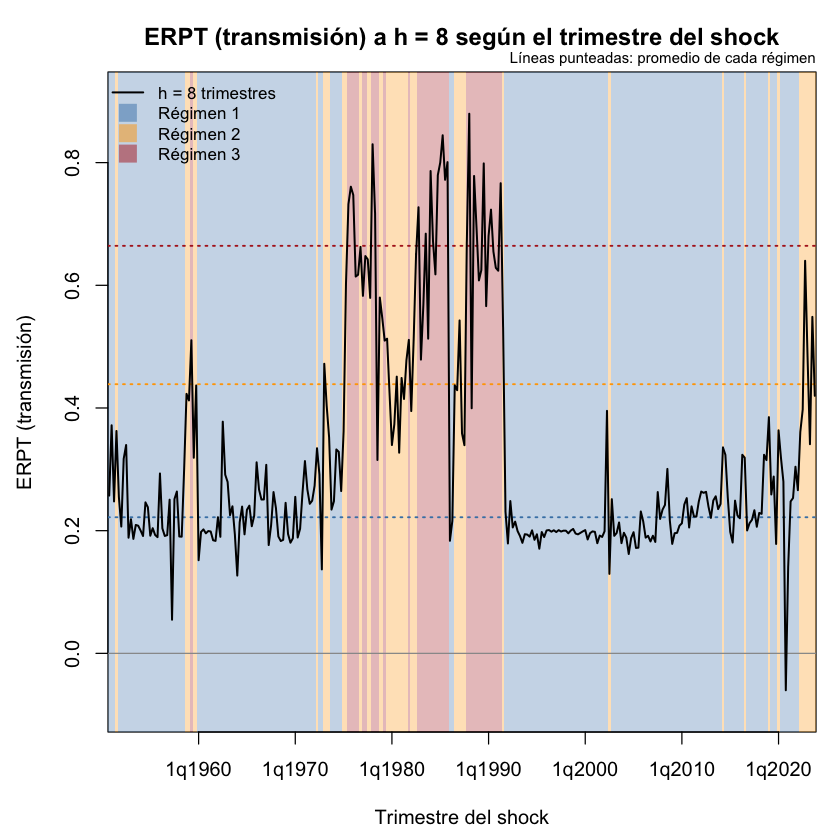

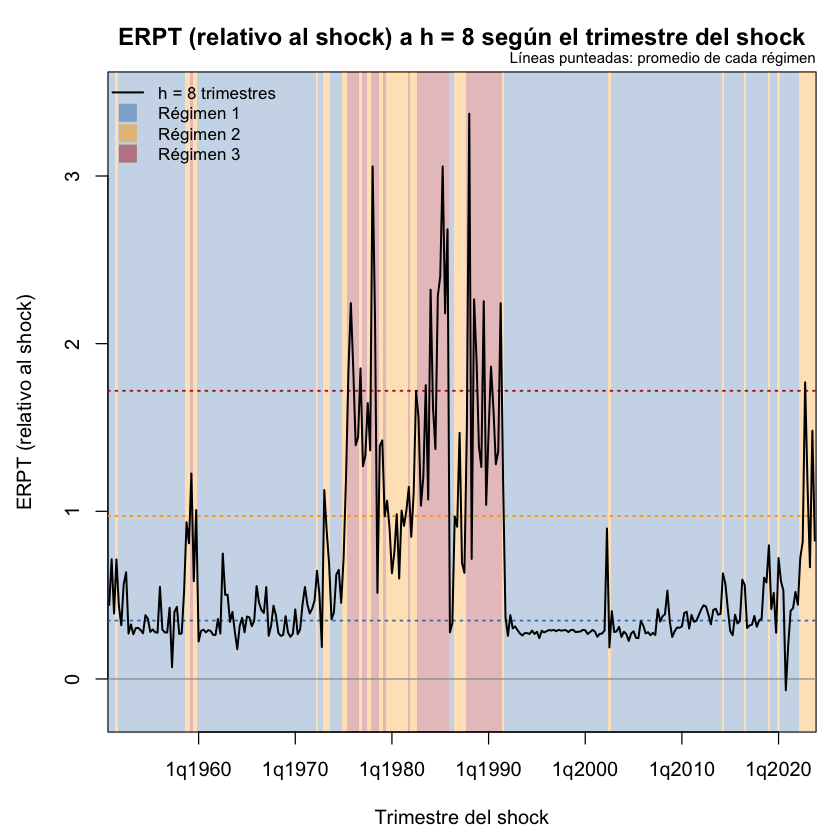

In [47]:
for (h in c(4, 8)) {
  graficar_erpt_2d_bandas(out_impp_usa_tvar3_p2_acum, horizontes = h, eje_y = "ERPT (transmisión)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar3_p2_acum_h", h, "_sincap"))
  graficar_erpt_2d_bandas(out_impp_usa_tvar3_p2, horizontes = h, eje_y = "ERPT (relativo al shock)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar3_p2_h", h, "_sincap"))
}

Umbrales (inflación trimestral de t-1): 12.5% trimestral (60% anualizada) | 28.2% trimestral (170% anualizada) 
Trimestres por régimen: régimen 1 = 206 | régimen 2 = 46 | régimen 3 = 41 


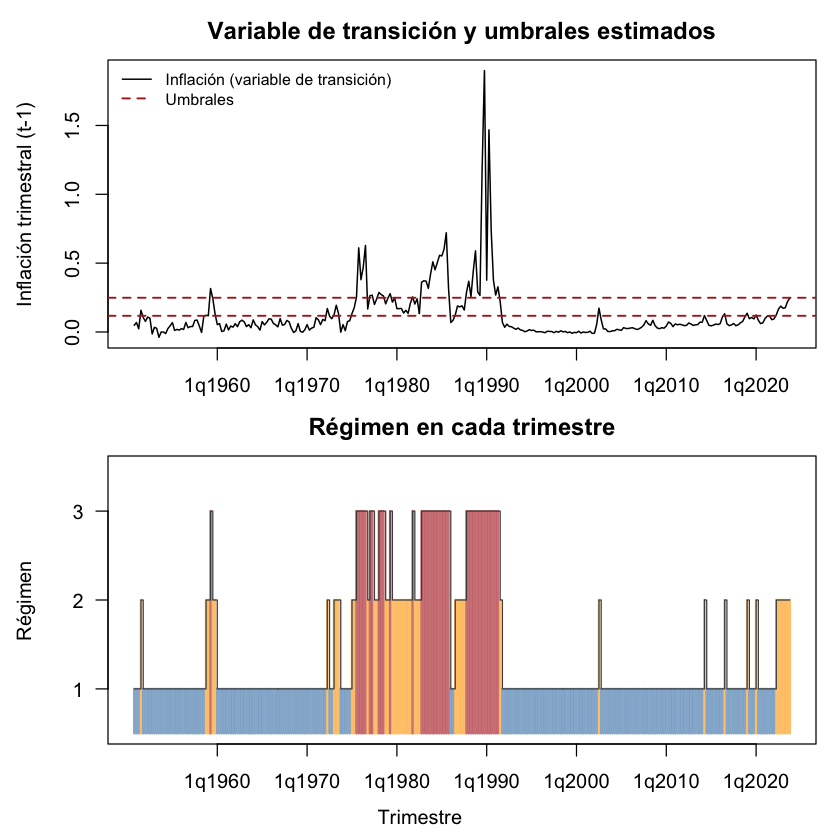

In [48]:
graficar_transicion(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_tvar3_p2_sincap")

In [16]:
#Lo comento porque es el de los puntos, que no es claro y prefiero bajar el tamaño de la notebook
#graficar_erpt_regimen_3d(out_impp_usa_tvar3_p2_acum, archivo = "erpt_regimen_3d_impp_usa_tvar3_p2_acum_sincap")

In [18]:
#Lo comento porque es el de las rayas que no es claro y bajo el tamaño de la notebook
#graficar_erpt_regimen_red(out_impp_usa_tvar3_p2_acum, h = 8, archivo = "erpt_red_impp_usa_tvar3_p2_acum_h8_sincap")

HTML widgets cannot be represented in plain text (need html)

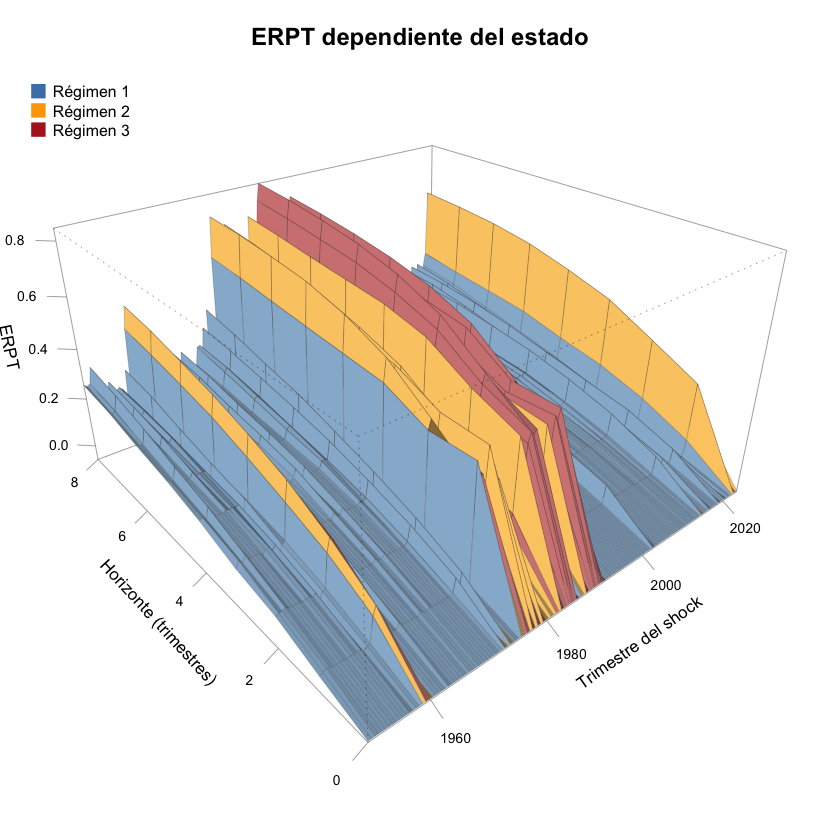

In [19]:
graficar_erpt_manta(out_impp_usa_tvar3_p2_acum, cada = 2, archivo = "erpt_manta_impp_usa_tvar3_p2_acum_c2_sincap")

In [20]:
guardar_gif_erpt_h(out_impp_usa_tvar3_p2_acum, h = 8,
                   marcas = c("3q1975", "3q1989", "1q2002", "2q2018"),
                   archivo = "gif_erpt_h8_marcas_impp_usa_tvar3_p2_acum_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_erpt_h8_marcas_impp_usa_tvar3_p2_acum_sincap.gif



In [21]:
guardar_gif_manta(out_impp_usa_tvar3_p2_acum, modo = "construir",
                  marcas = c("3q1975", "3q1989", "1q2002", "2q2018"),
                  archivo = "gif_manta_construir_marcas_impp_usa_tvar3_p2_acum_sincap")

GIF guardado en: /Users/mariana/Library/CloudStorage/GoogleDrive-marianabarrenadrive@gmail.com/Mi unidad/TESIS UCA/UCA Proyecto de TESIS/Estadísticas/Github/r_experiments/gif_manta_construir_marcas_impp_usa_tvar3_p2_acum_sincap.gif



In [22]:
graficar_slider(out_impp_usa_tvar3_p2_acum, archivo = "slider_impp_usa_tvar3_p2_acum_sincap")

HTML widgets cannot be represented in plain text (need html)

HTML widgets cannot be represented in plain text (need html)

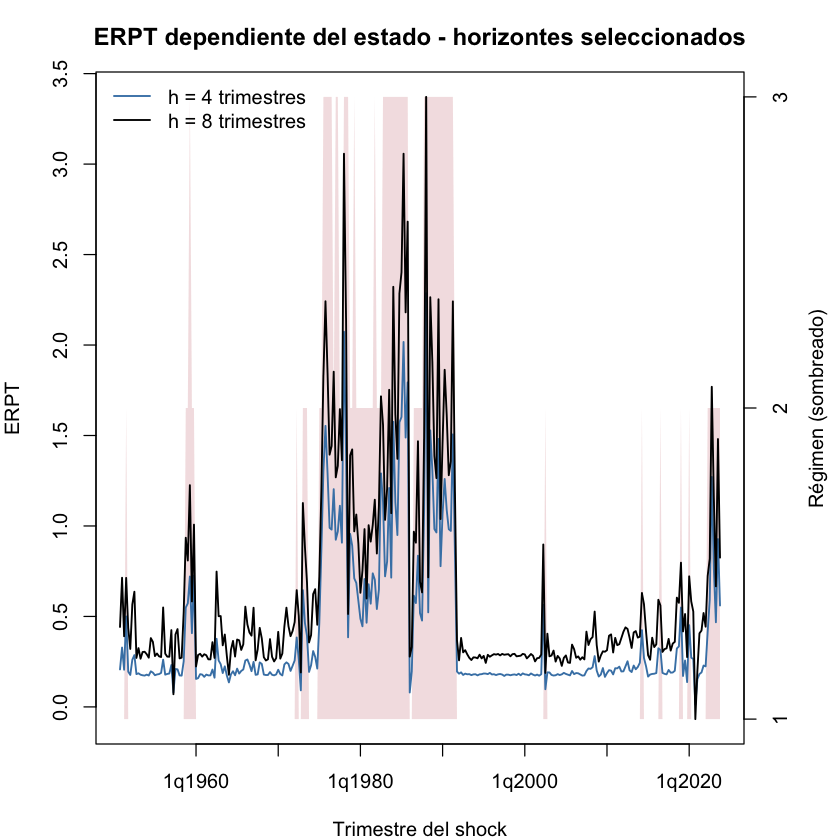

In [23]:
graficar_erpt(out_impp_usa_tvar3_p2, archivo = "erpt_impp_usa_tvar3_p2_sincap")

## TVAR, 3 regímenes, p = 3

Se cargó exitosamente modelos preguardados  threshold_tvar_3_3_500_119ebd6353d8f9c04a247d14a9448a28.rds  de la carpeta models

 >>> TESTS
PARA CORRER LOS TESTS CORRER LA SIGUIENTE FUNCION:
run_tests_sstvar(res, c(' ipc '), TRUE , NULL , 1 , 500 )

 >>> DIAGNOSTIC PLOTS


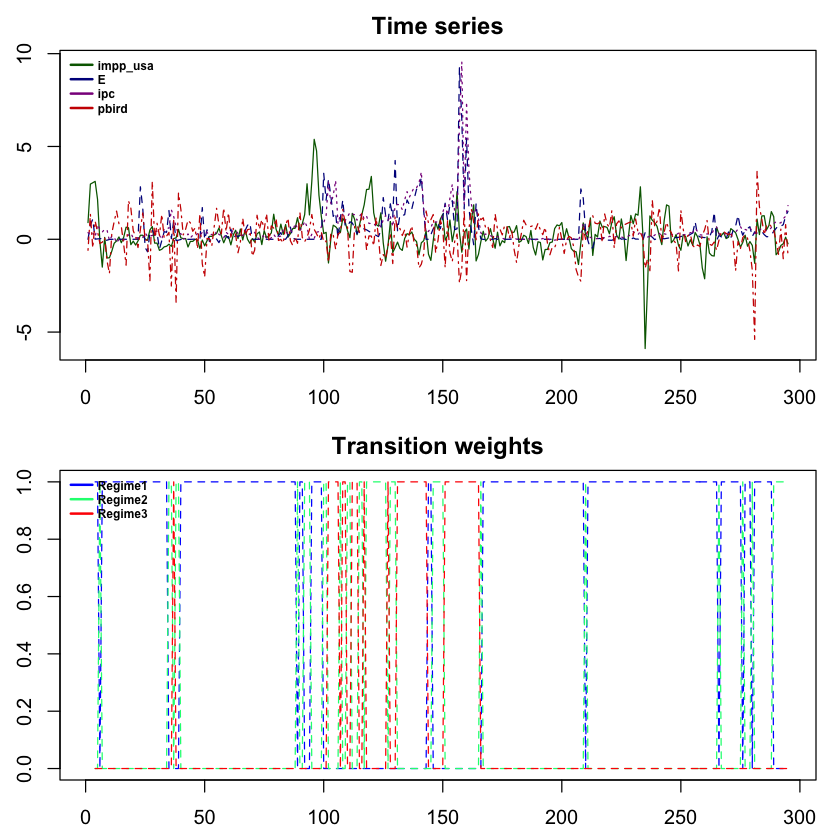

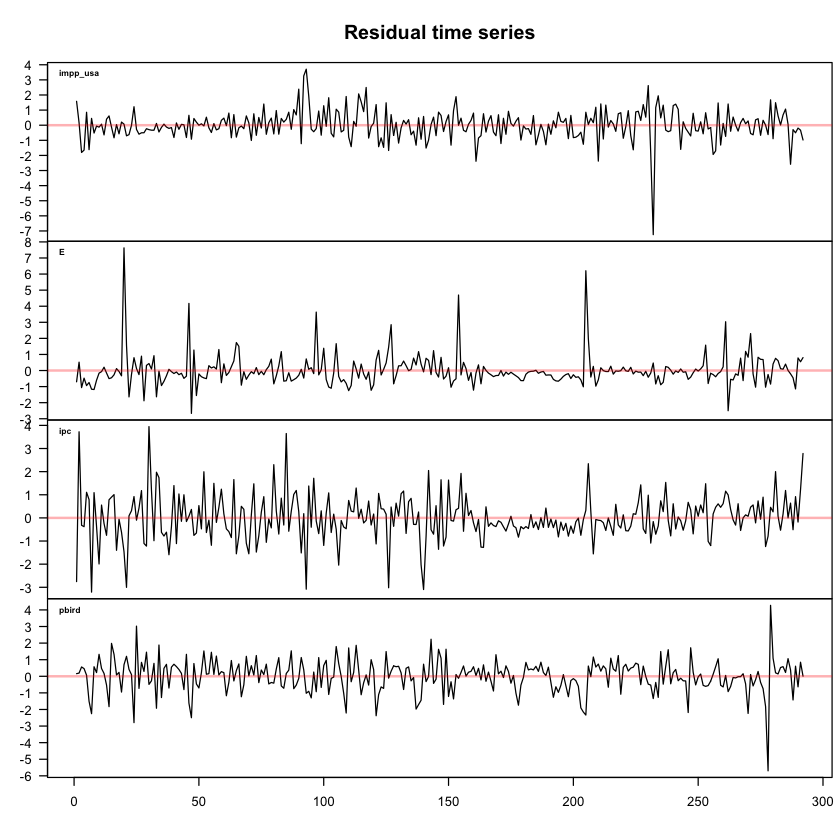

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



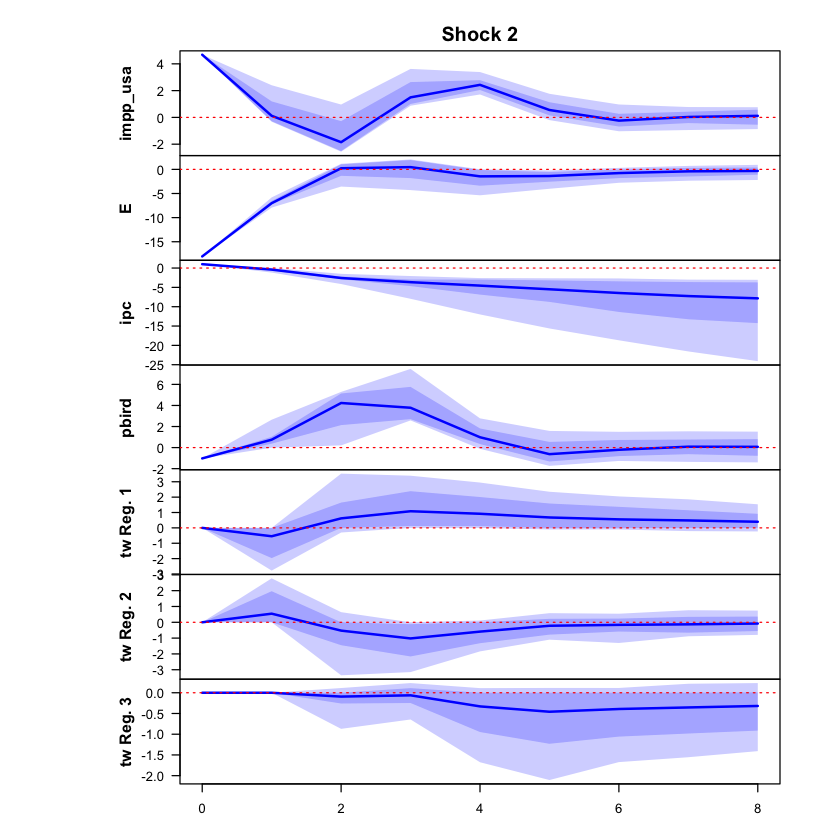

 >>> Linear IRF ( 1  shock units)


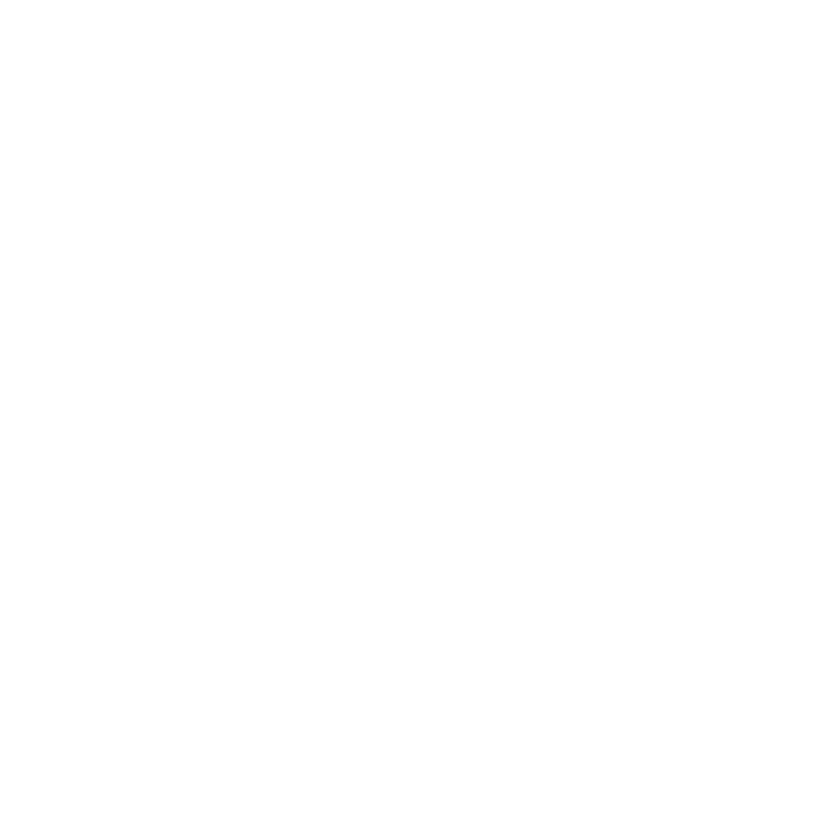

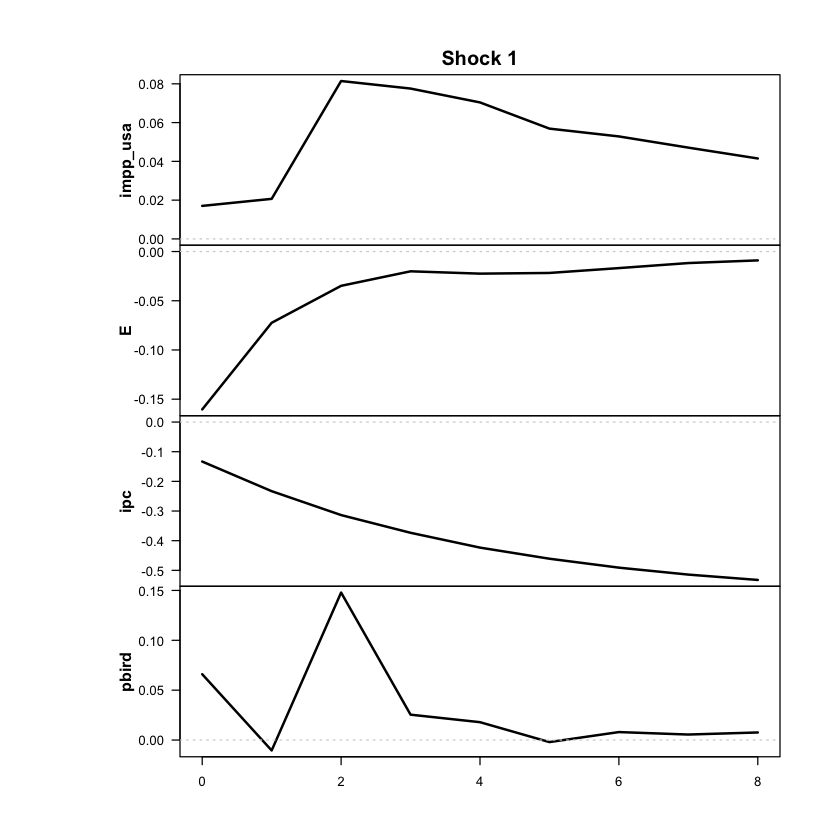

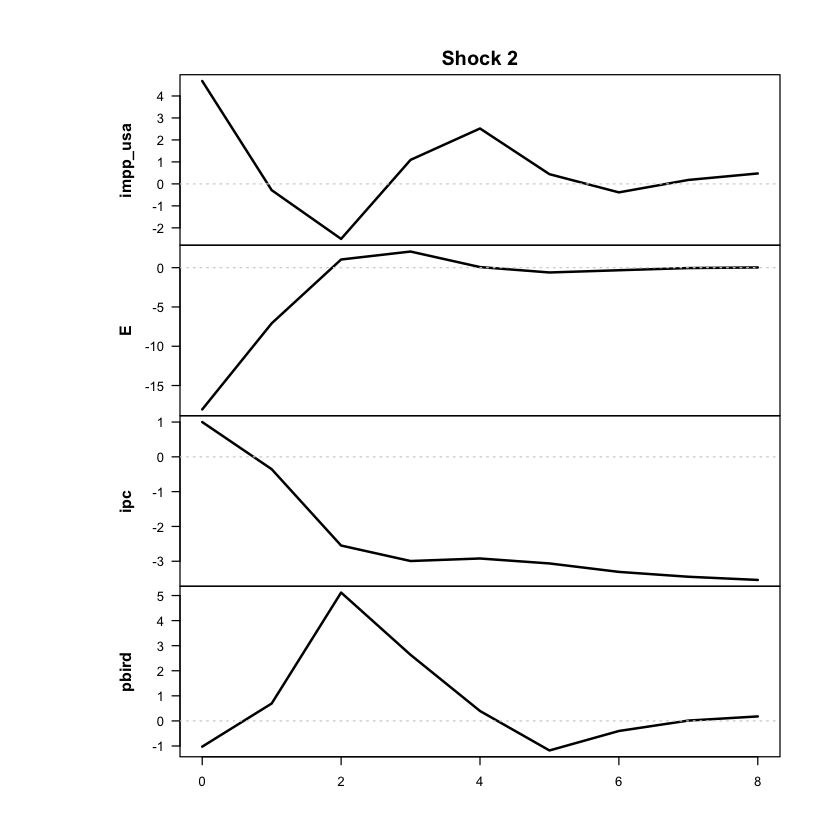

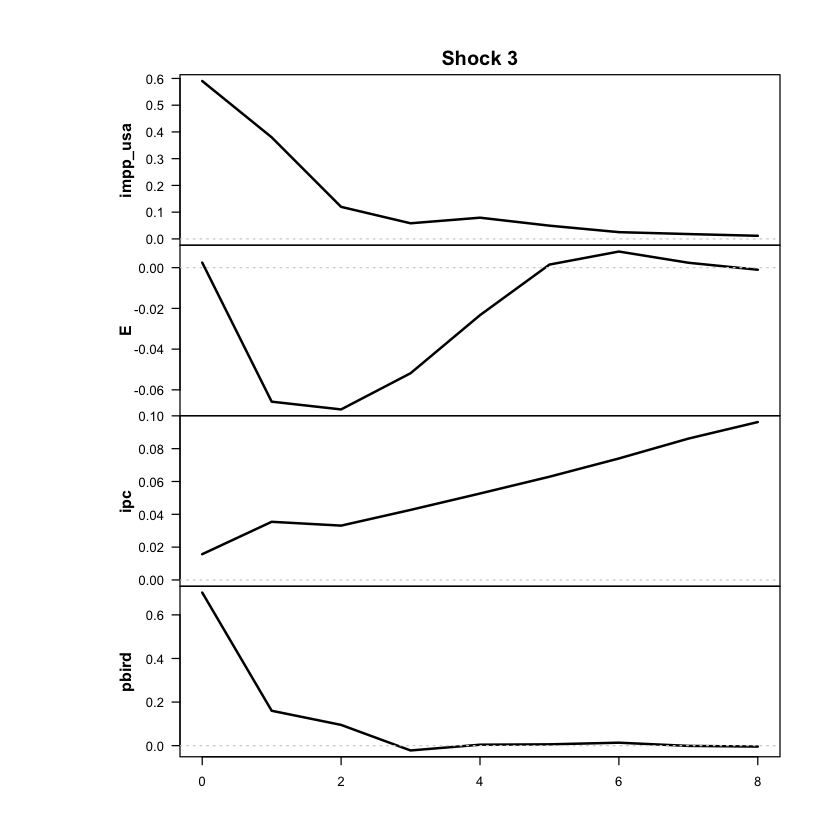

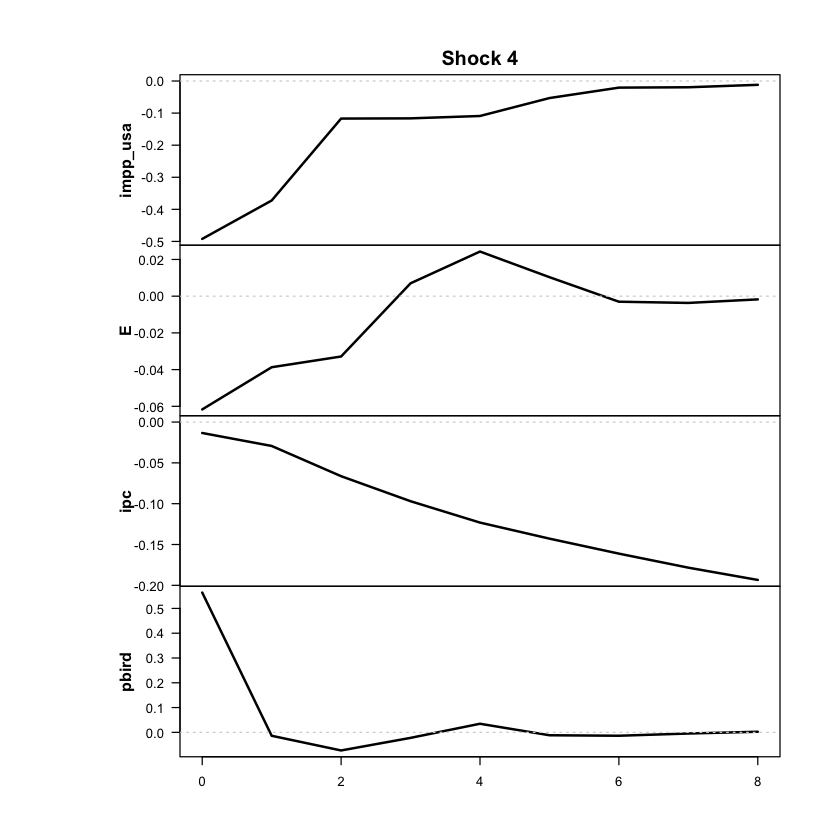

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



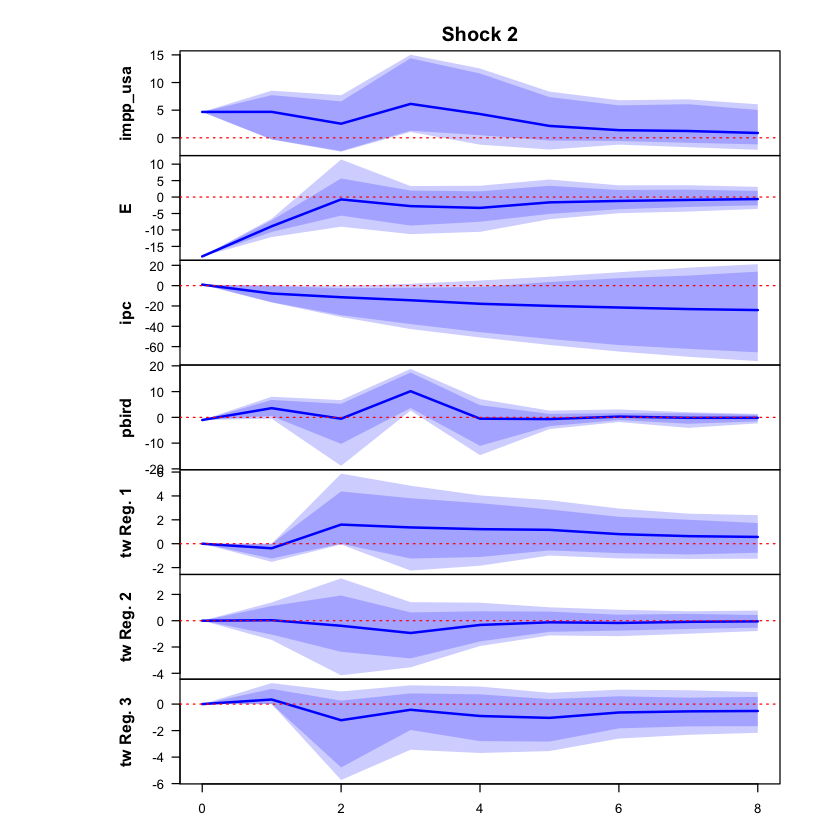

 >>> Linear IRF ( 1  shock units)


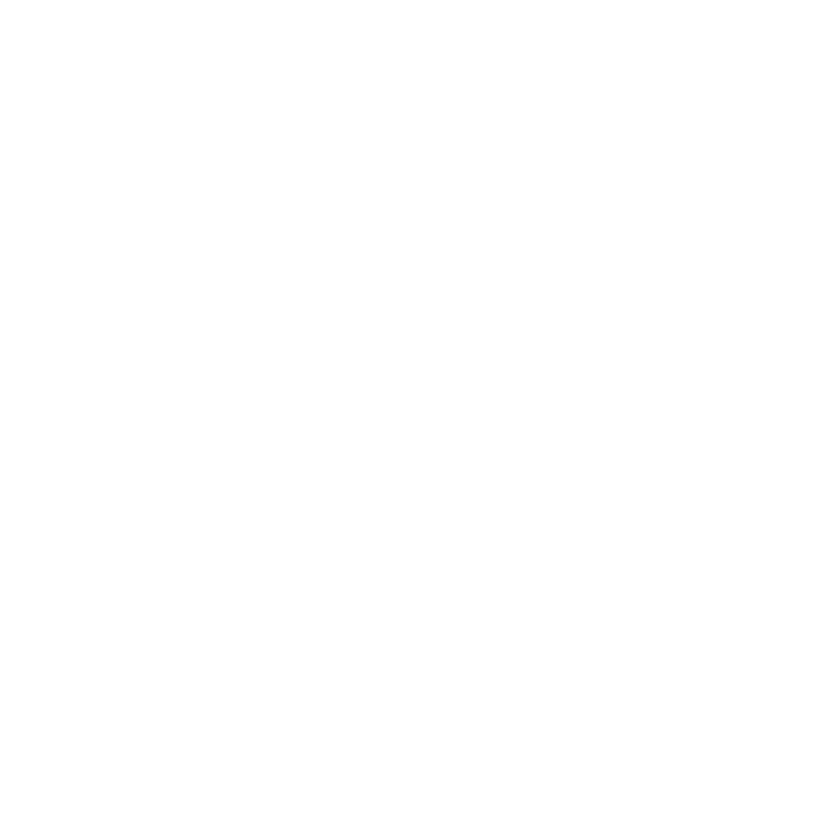

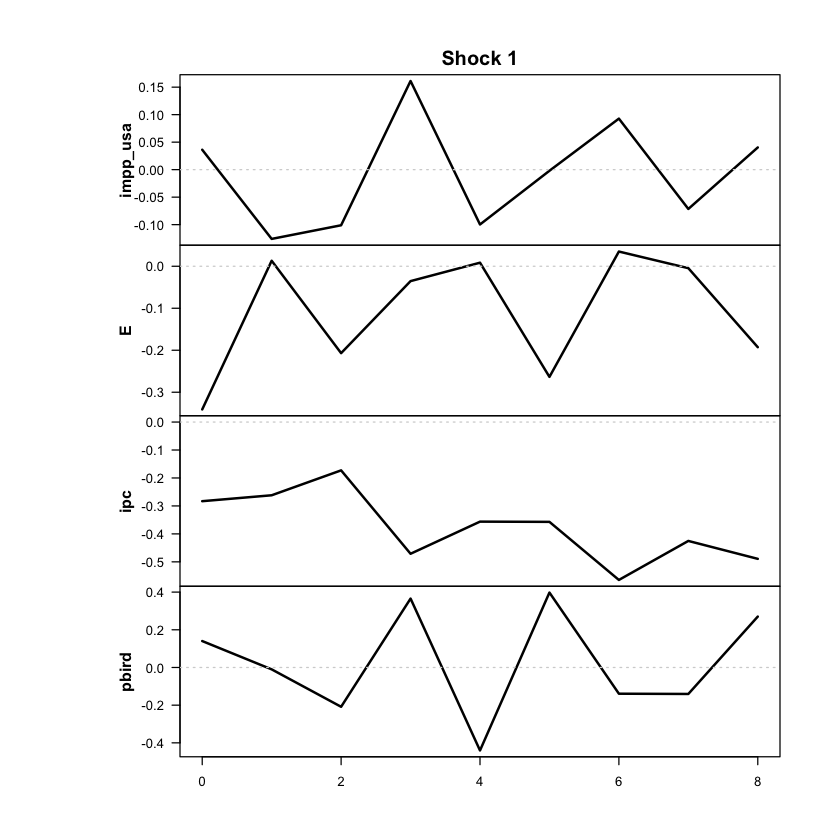

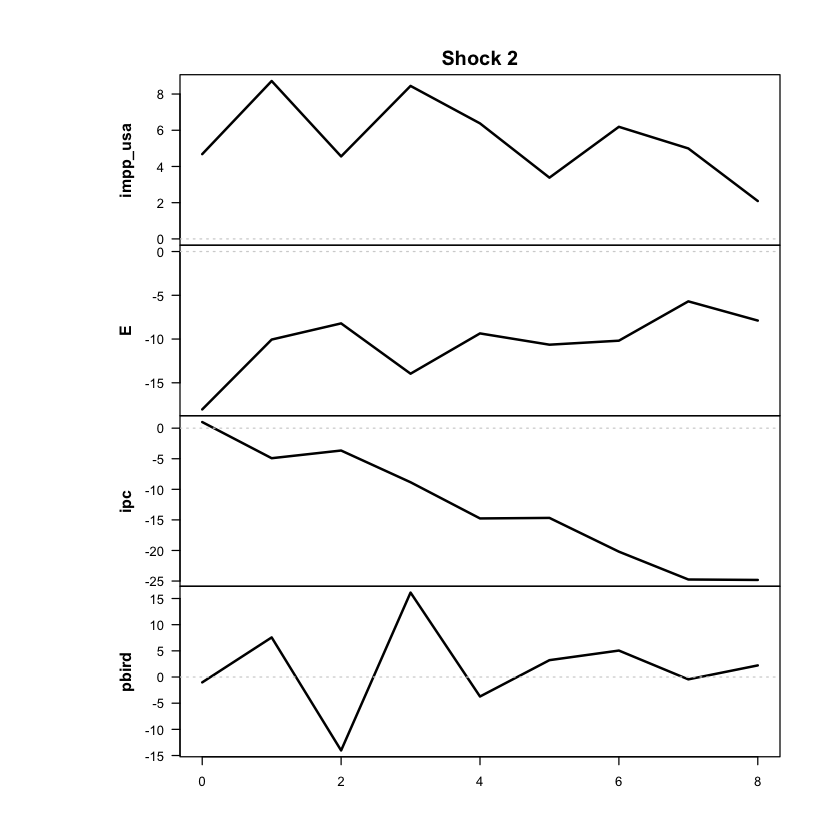

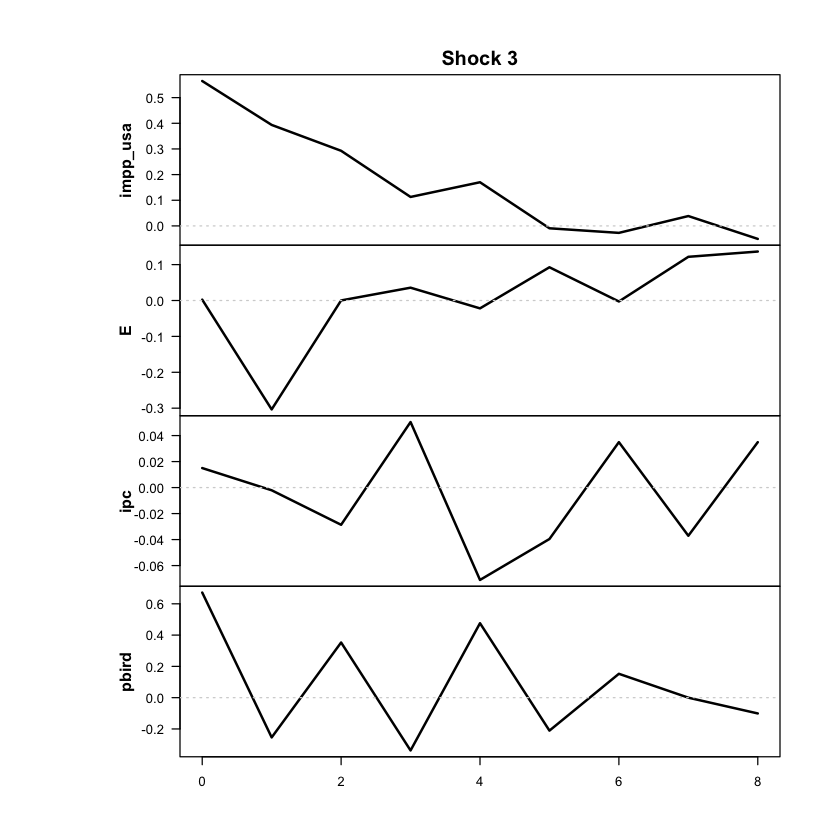

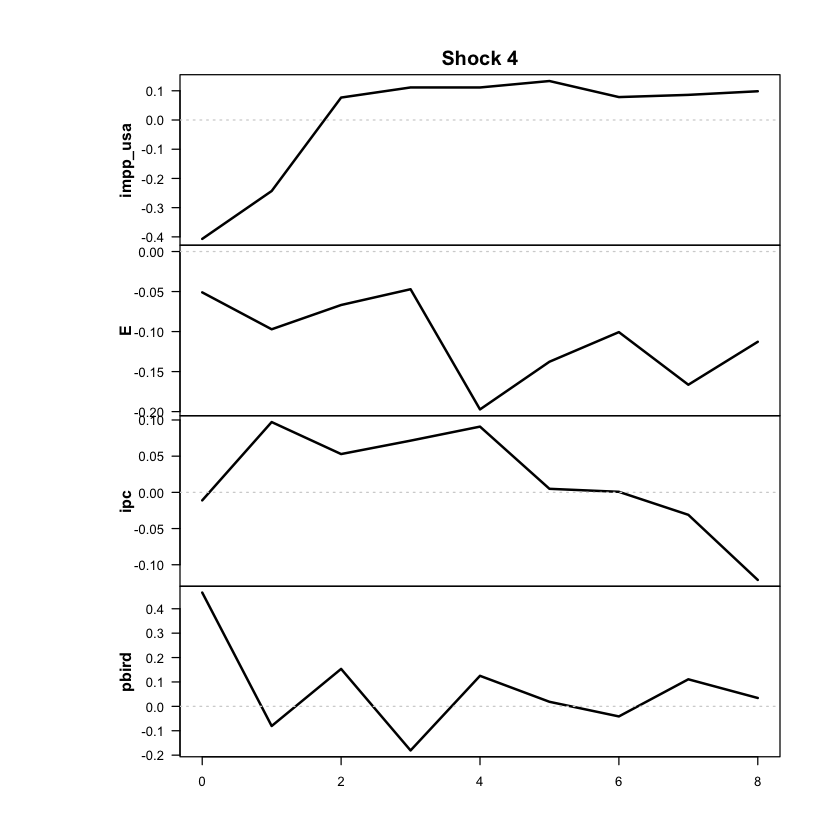

+++++++++ RÉGIMEN  3 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



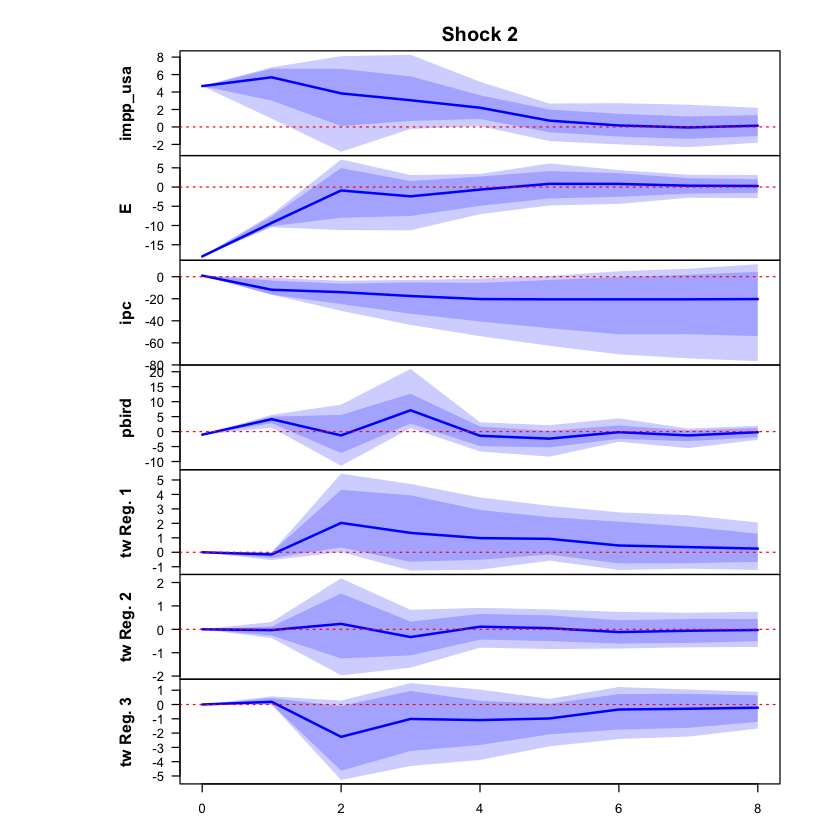

 >>> Linear IRF ( 1  shock units)


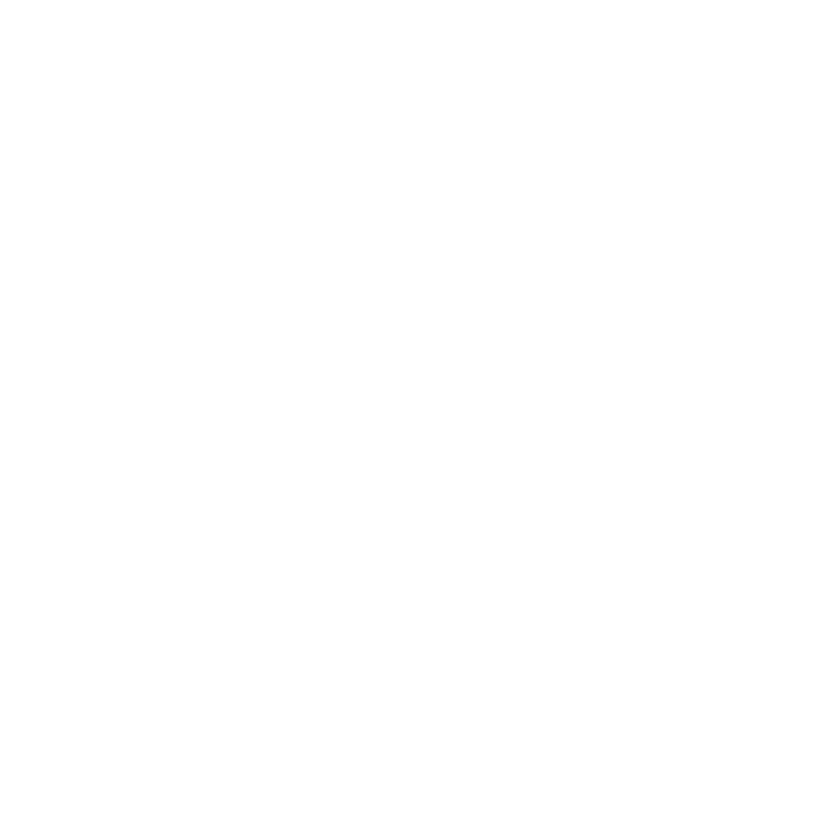

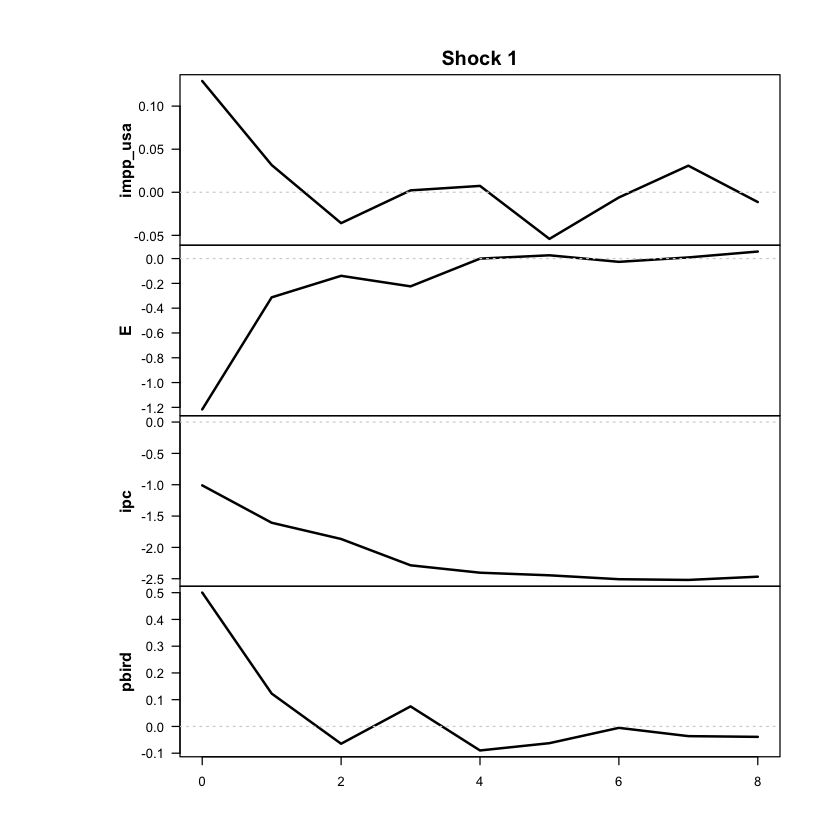

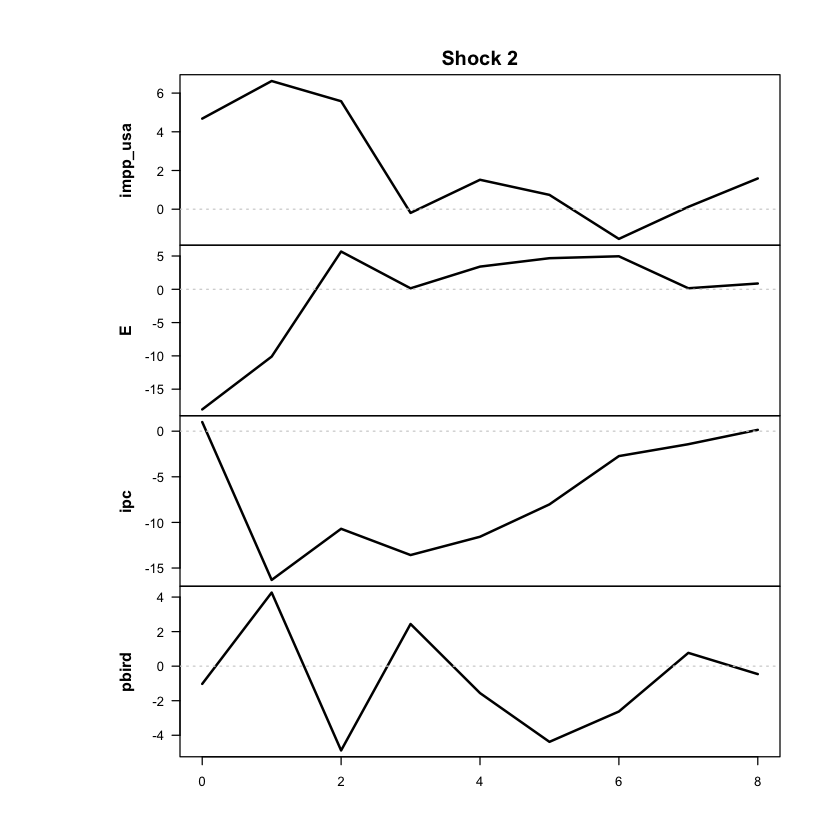

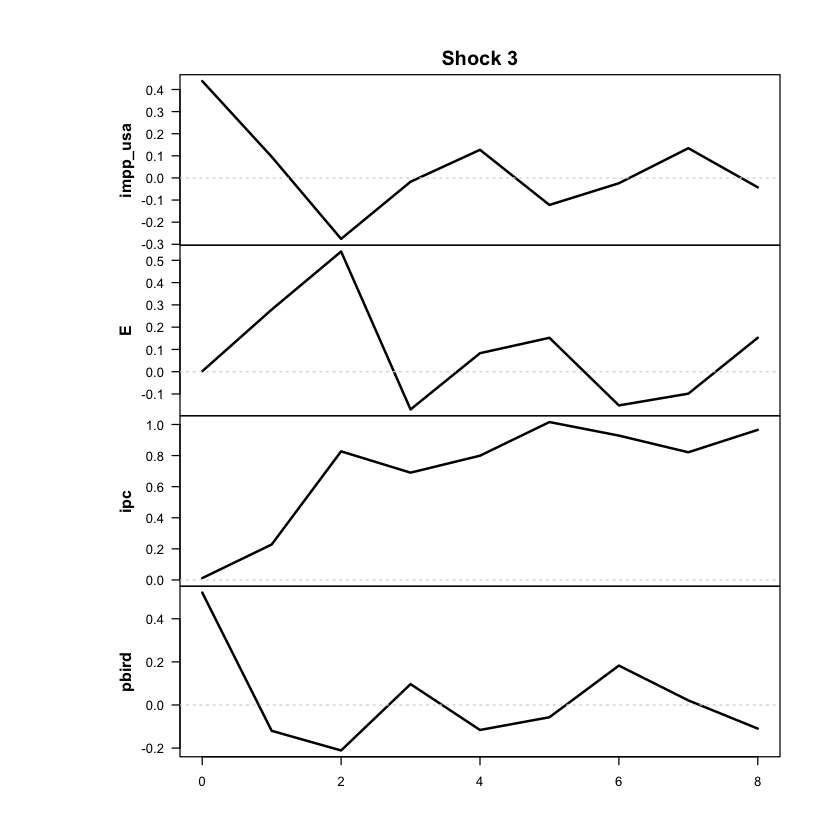

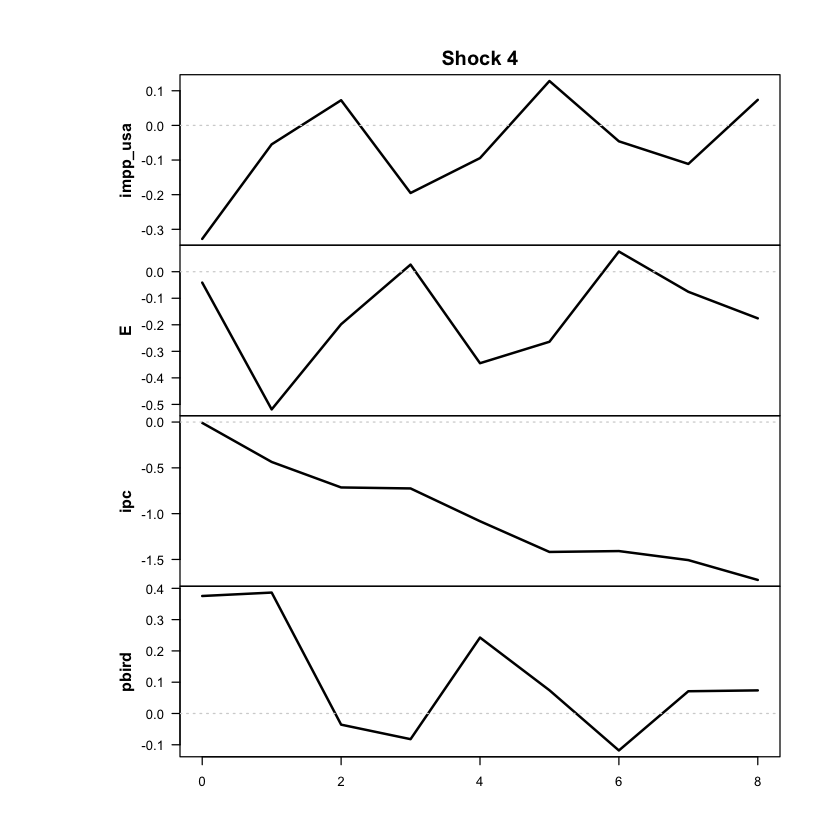

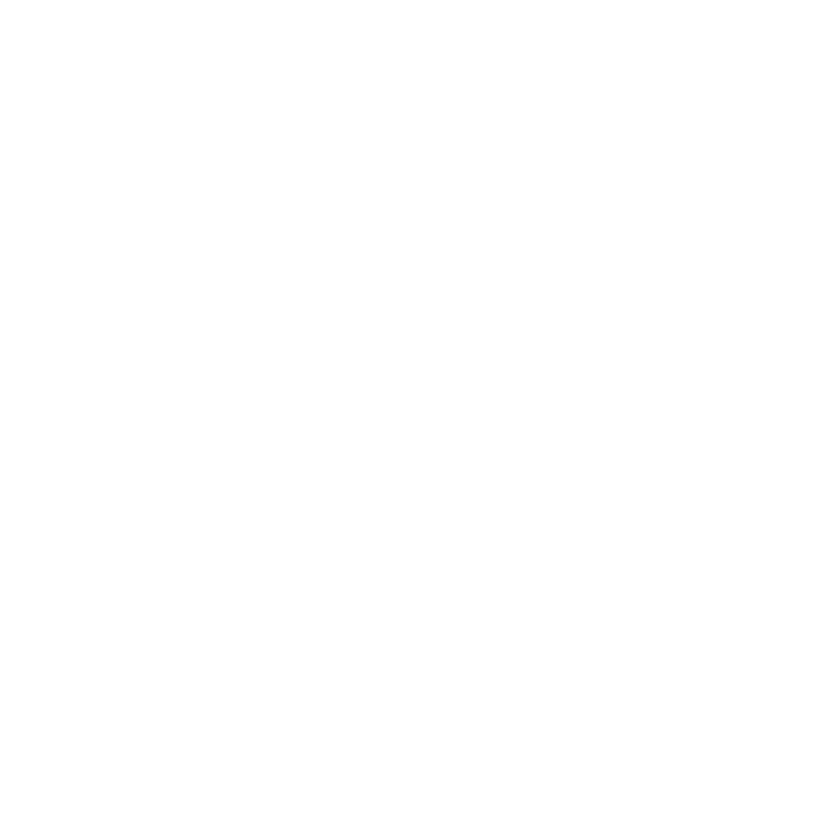

In [ ]:
res <- run_threshold_tvar(
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual' o mensual
  feature_lag = 3,
  n_regimes = 3,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = TRUE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [5]:
ic_tvar3_p3 <- criterios_info(res, "TVAR 3 reg p=3")
print(ic_tvar3_p3)

          modelo regimenes parametros  loglik    AIC     HQ    BIC
1 TVAR 3 reg p=3         3        188 -777.18 1930.4 2207.2 2621.6


In [6]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: threshold | regímenes: 3 | rezagos: 3 | errores: Gaussian 
Umbrales: 12.5% trimestral (60% anualizada) | 28.2% trimestral (170% anualizada) 
Trimestres por régimen (régimen de mayor peso): régimen 1 = 206 | régimen 2 = 45 | régimen 3 = 41 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2 Régimen 3
impp_usa      0.55      1.52      0.75
E             3.69     20.59     53.24
ipc           4.71     20.08     58.86
pbird         0.83     -0.25      0.01


In [7]:
explorar_optimos(res, n = 10)
# En un TVAR, umbral_trim_pct y gamma no tienen sentido: mirar solo loglik y las columnas de avisos.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -777.18     12.5 / 28.2    NA         NA        206/45/41
             2 -781.22      2.5 / 12.5    NA         NA        71/135/86
             3 -786.03        4 / 12.5    NA         NA        98/108/86
             4 -787.24      3.4 / 12.5    NA         NA        90/116/86
             5 -796.52     12.4 / 27.9    NA         NA        205/44/43
             6 -797.52      0.9 / 14.2    NA         NA        46/168/78
             7 -799.09      2.5 / 14.3    NA         NA        71/143/78
             8 -802.77     12.6 / 27.5    NA         NA        207/41/44
             9 -802

In [8]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

threshold Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 3, M = 3, d = 4, #parameters = 188, #observations = 292 x 4
  Switching variable: ipc with lag 1.

Regime 1 
Upper threshold: 0.59 
Regime means: 0.14, 0.18, 0.28, 0.25

   Y     phi0          A1                                 A2                  
1 y1 = [ 0.17 ] + [  0.70  0.18 -0.30 -0.04 ] y1.1 + [ -0.24 -0.01 -0.37  0.04
2 y2   [ 0.14 ]   [ -0.04  0.39  0.04 -0.06 ] y2.1   [  0.03 -0.19  0.23 -0.05
3 y3   [ 0.05 ]   [  0.01  0.11  0.62  0.01 ] y3.1   [  0.01  0.04  0.03 -0.02
4 y4   [ 0.28 ]   [  0.14  0.00  0.15  0.10 ] y4.1   [  0.08 -0.32 -0.82 -0.02
                A3                              Omega                     1/2
1 ] y1.2 + [  0.21 -0.02  0.20 -0.06 ] y1.3 + [  0.60  0.00  0.01  0.14 ]    
2 ] y2.2   [ -0.04 -0.06 -0.06 -0.01 ] y2.3   [  0.00  0.13  0.01 -0.04 ]    
3 ] y3.2   [  0.02 -0.05  0.09  0.01 ] y3.3   [  0.01  0.01  0.02 -0.01 ]    
4 ] y4.2   [ -0.10  0.04

In [31]:
shock_tvar3_p3 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Con 3 regímenes el número del shock cambiario puede no ser 2.
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_tvar3_p3 <- 2
shock_tvar3_p3

Efecto de impacto de cada shock  (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0005  0.0023  0.0163 -0.0136
  E        -0.0384 -0.0773  0.0006 -0.0148
  ipc      -0.0264  0.0036  0.0031 -0.0027
  pbird     0.0018 -0.0005  0.0195  0.0156

Participación de E en el efecto de cada shock  :
shock_1 shock_2 shock_3 shock_4 
   0.73    0.97    0.00    0.08 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.689  -0.046   5.244   0.180 

>>> Shock sugerido como cambiario: 2 (confirmalo: debe mover mucho a E y poco a ipc )


[1] 2

### ERPT y gráficos — tvar3 p3

Correr solo si el modelo pasó el diagnóstico (sin avisos, shock cambiario confirmado).

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 8.0%.

GIRF del régimen 1...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 2...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!

GIRF del régimen 3...

Using 9 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




+++ Régimen 1 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0460  0.0066
         1  0.0189  0.0014
         2  0.1226 -0.0257
         3  0.1796 -0.0507
         4  0.2264 -0.0572
         5  0.2745 -0.0540
         6  0.3216 -0.0525
         7  0.3609 -0.0530
         8  0.3950 -0.0542

+++ Régimen 2 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0460  0.0066
         1  0.3768 -0.0164
         2  0.5942 -0.0184
         3  0.7575 -0.0852
         4  0.9265 -0.0850
         5  1.0408 -0.0809
         6  1.1302 -0.0826
         7  1.2094 -0.0818
         8  1.2672 -0.0819

+++ Régimen 3 - respuestas acumuladas por 1% de depreciación inicial (unidades originales) +++
 horizonte     ipc   pbird
         0 -0.0460  0.0066
         1  0.5528 -0.0203
         2  0.6572 -0.0091
         3  0.8312 -0.0553
         4  0.9578 -0.0448
         5

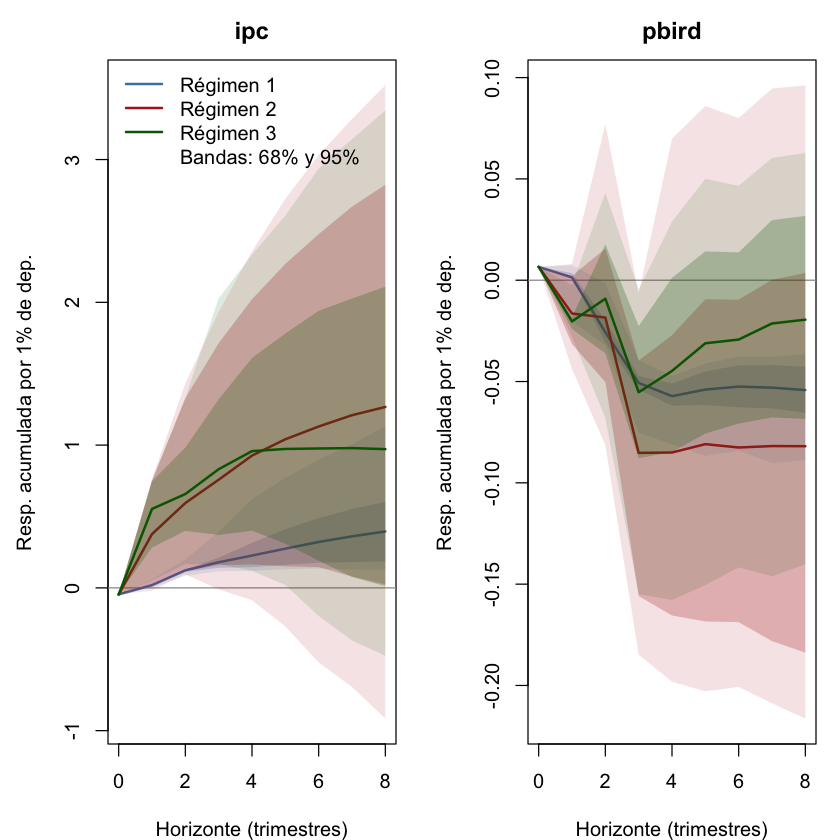

In [32]:
girf_impp_usa_tvar3_p3 <- graficar_girf_original(res, endog = c("impp_usa", "E", "ipc", "pbird"),
                                                 shock_num = shock_tvar3_p3, regimenes = 1:3,
                                                 archivo = "girf_original_impp_usa_tvar3_p3_sincap")

In [33]:
ls(pattern = "^out_impp_usa_tvar3_p3")

[1] "out_impp_usa_tvar3_p3"      "out_impp_usa_tvar3_p3_acum"

In [34]:
  out_impp_usa_tvar3_p3_acum$chequeo_mediana

horizonte,reg_1_mediana,reg_2_mediana,reg_3_mediana
<int>,<dbl>,<dbl>,<dbl>
0,-0.04599750,-0.0459975,-0.0459975
1,0.01168382,0.1271405,0.4086046
2,0.08776405,0.1912707,0.3714414
3,0.11444395,0.2624927,0.4007857
4,0.11535946,0.3299396,0.5229277
5,0.12898097,0.3704736,0.4992412
6,0.14053212,0.4052312,0.4802582
7,0.15695213,0.4494325,0.4748213
8,0.16547940,0.4669584,0.4398539


In [11]:
out_impp_usa_tvar3_p3 <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar3_p3)

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 8.0%.

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 206 | régimen 2 = 45 | régimen 3 = 41 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_1_original reg_2_original reg_3_original
1         0        -0.0460        -0.0460        -0.0460
2         1         0.0170         0.2402         0.5704
3         2         0.1193         0.3855         0.5950
4         3         0.1631         0.5677         0.7215
5         4         0.1927         0.7930         0.8792
6         5         0.2292         0.9039         0.8601
7         6         0.2676         1.0157         0.8400
8         7         0.3027         1.0988         0.8315
9         8         0.3309         1.1649         0.8140

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_1_mediana reg_2_mediana reg_3_mediana
1         0       -0.0460       -0.0460       -0.0460
2         1        0.0163        0

In [12]:
out_impp_usa_tvar3_p3_acum <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_tvar3_p3,
                      definicion = "acumulado")

Shock: 1.000 desvíos estructurales con el signo invertido; en el impacto (régimen 1) deprecia E en 8.0%.

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 206 | régimen 2 = 45 | régimen 3 = 41 
Shock usado:2| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

Promedio entre trimestres:
  horizonte reg_1_original reg_2_original reg_3_original
1         0        -0.0460        -0.0460        -0.0460
2         1         0.0123         0.1604         0.3718
3         2         0.0869         0.2139         0.3781
4         3         0.1199         0.2708         0.4151
5         4         0.1316         0.3383         0.4960
6         5         0.1479         0.3684         0.4863
7         6         0.1649         0.3952         0.4447
8         7         0.1811         0.4137         0.3645
9         8         0.1937         0.4257        37.9720

Mediana entre trimestres (robusta a trimestres con respuestas extremas):
  horizonte reg_1_mediana reg_2_mediana reg_3_mediana
1         0       -0.0460       -0.0460       -0.0460
2         1        0.0117        0

Valores acotados SOLO para los gráficos (2 de 2628; por régimen y horizonte: fuera de Q1 - 5·IQR / Q3 + 5·IQR y a más de 1 de la mediana):
 trimestre regimen horizonte valor_original valor_graficado
    2q1989       3         7         -3.280          -1.916
    2q1989       3         8       1540.482           2.852


HTML widgets cannot be represented in plain text (need html)

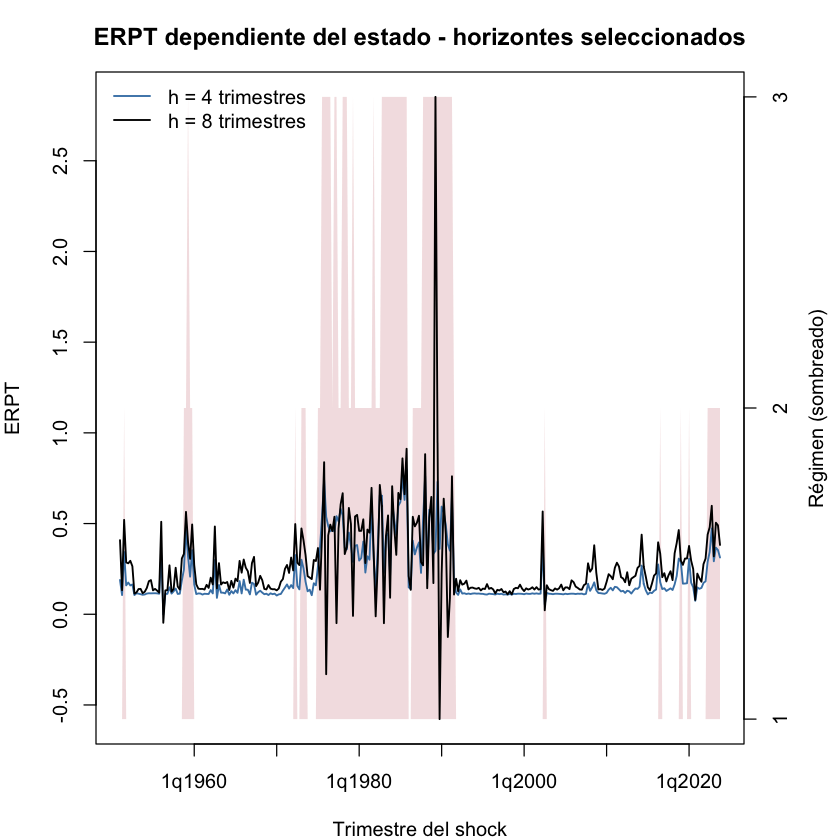

In [37]:
graficar_erpt(acotar_para_graficar(out_impp_usa_tvar3_p3_acum),
              archivo = "erpt_impp_usa_tvar3_p3_acum_sincap")

Gráficos con la MEDIANA por régimen como referencia.
Gráficos con la MEDIANA por régimen como referencia.
Valores acotados SOLO para los gráficos (2 de 2628; por régimen y horizonte: fuera de Q1 - 5·IQR / Q3 + 5·IQR y a más de 1 de la mediana):
 trimestre regimen horizonte valor_original valor_graficado
    2q1989       3         7         -3.280          -1.916
    2q1989       3         8       1540.482           2.852
Gráficos con la MEDIANA por régimen como referencia.
Valores acotados SOLO para los gráficos (2 de 2628; por régimen y horizonte: fuera de Q1 - 5·IQR / Q3 + 5·IQR y a más de 1 de la mediana):
 trimestre regimen horizonte valor_original valor_graficado
    2q1989       3         7         -3.280          -1.916
    2q1989       3         8       1540.482           2.852
Mediana de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_mediana reg_2_mediana reg_3_mediana
         4         0.115          0.33         0.523
Mediana de ERPT (relativo 

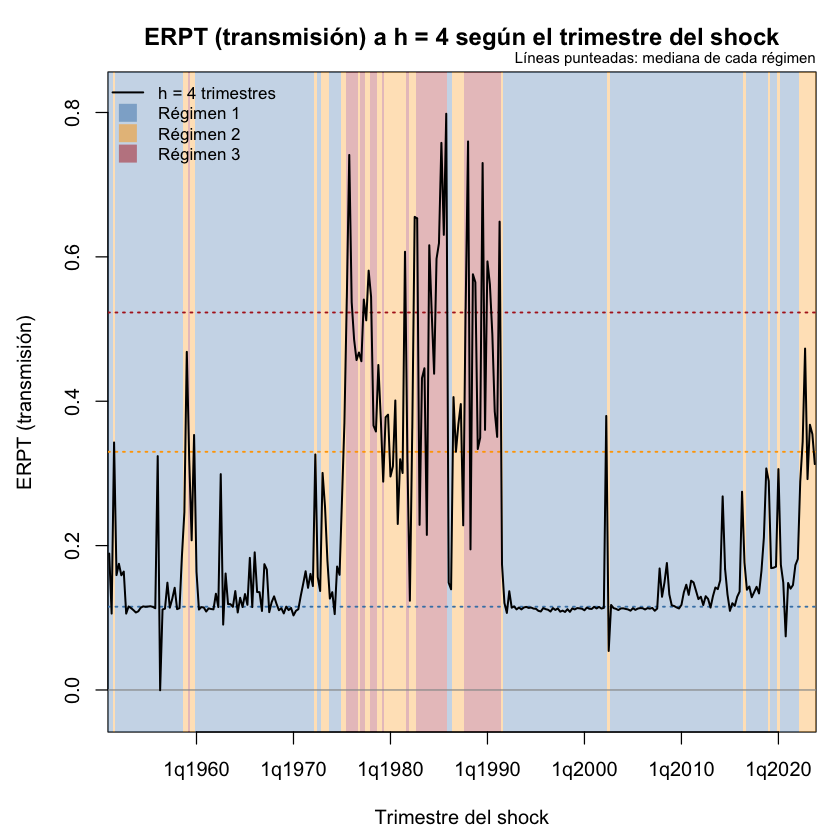

Mediana de ERPT (transmisión) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_mediana reg_2_mediana reg_3_mediana
         8         0.165         0.467          0.44


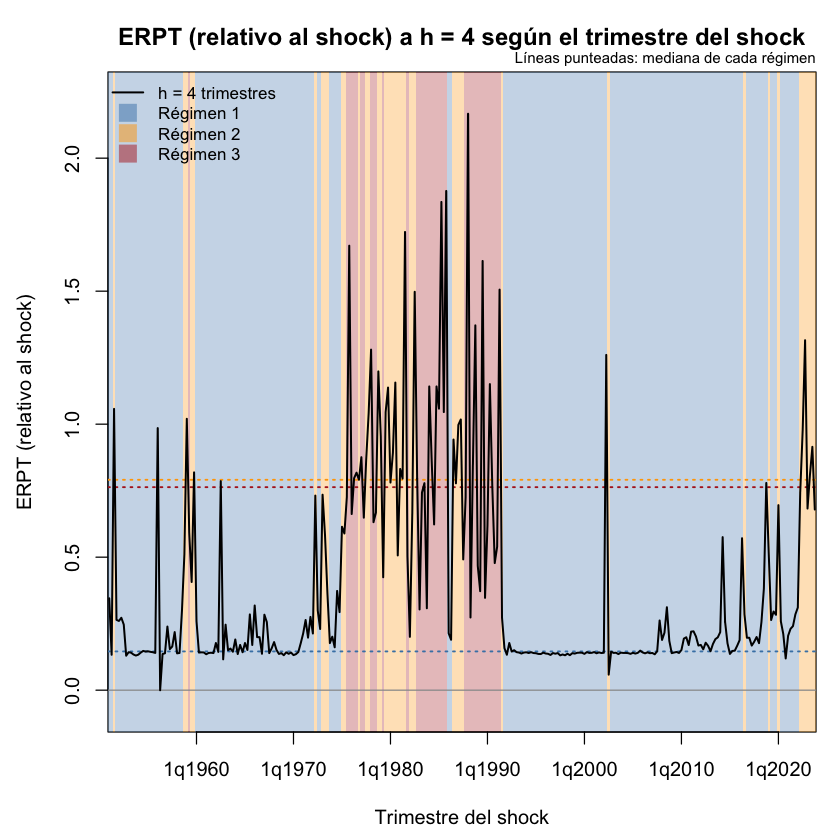

Mediana de ERPT (relativo al shock) por régimen (trimestres con peso > 0.9):
 horizonte reg_1_mediana reg_2_mediana reg_3_mediana
         8         0.229         1.327         0.591


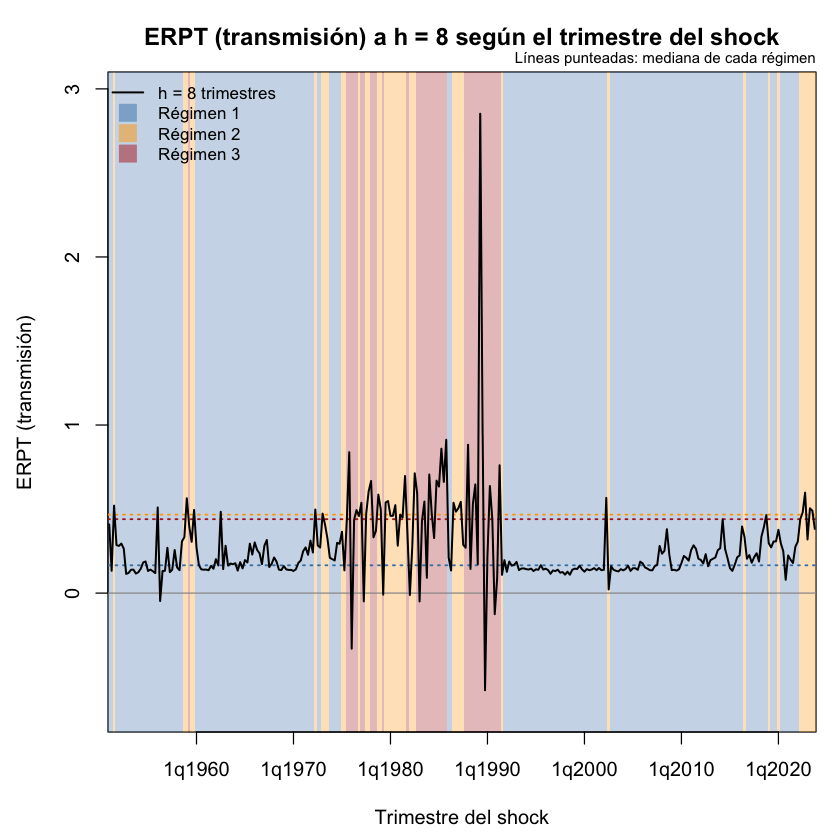

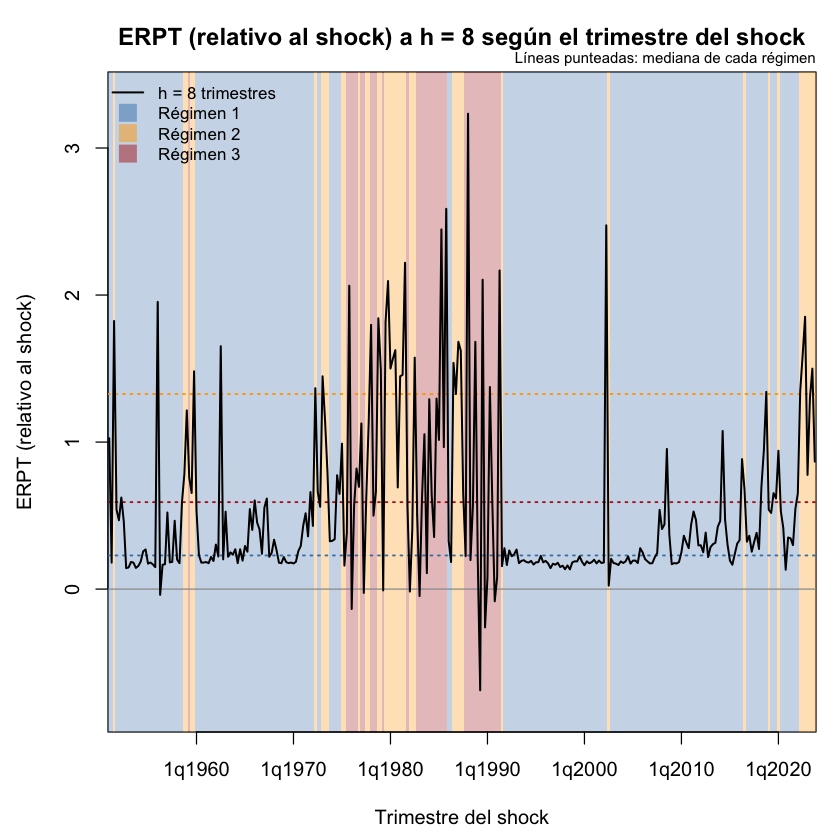

In [ ]:
g_t3p3      <- graficos_con_mediana(out_impp_usa_tvar3_p3)                         # relativo al shock: sin acotar
g_t3p3_acum <- acotar_para_graficar(graficos_con_mediana(out_impp_usa_tvar3_p3_acum))  # transmisión: acota 2q1989

for (h in c(4, 8)) {
  graficar_erpt_2d_bandas(g_t3p3_acum, horizontes = h, eje_y = "ERPT (transmisión)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar3_p3_acum_h", h, "_sincap"))
  graficar_erpt_2d_bandas(g_t3p3, horizontes = h, eje_y = "ERPT (relativo al shock)",
      archivo = paste0("erpt_2d_bandas_impp_usa_tvar3_p3_h", h, "_sincap"))
}

Umbrales (inflación trimestral de t-1): 12.5% trimestral (60% anualizada) | 28.2% trimestral (170% anualizada) 
Trimestres por régimen: régimen 1 = 206 | régimen 2 = 45 | régimen 3 = 41 


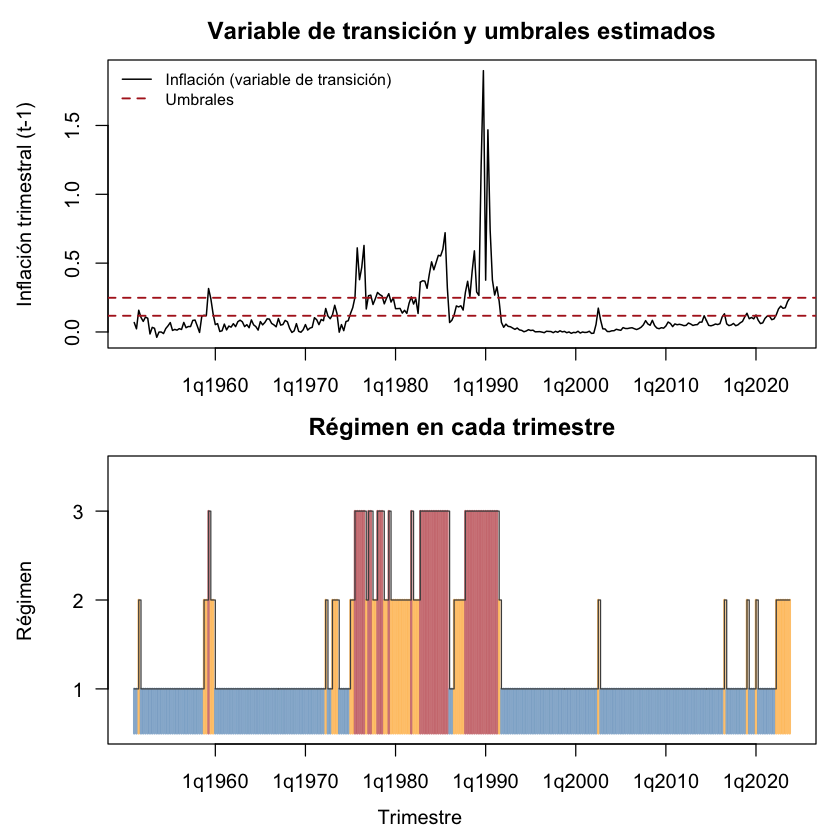

In [40]:
graficar_transicion(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_tvar3_p3_sincap")

## STVAR con transición logit multinomial (mlogit), 3 regímenes, p = 2

`sstvars` no admite la transición logística con más de 2 regímenes; `mlogit` es la alternativa de transición suave. El peso de cada régimen depende de la inflación de t-1 a través de un logit multinomial (constante y pendiente propias de cada régimen). No tiene umbral c ni γ: `resumen_modelo` muestra la inflación en la que cambia el régimen dominante y avisa si los regímenes no quedan ordenados. Riesgo conocido: que el régimen de inflación más alta quede con pocos trimestres y covarianza casi singular.

Muy malos resultados, no conviene correr p=3. Explicación en la página 224 de la conversación con Claude (Claude sept 2026Diferencia entre IRF y GIRF)

Desvíos usados para escalar:
  impp_usa          E        ipc      pbird 
0.02758807 0.23928824 0.19858620 0.02774553 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -1526.491

The largest loglik: -956.286

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -1439.717

The largest loglik: -883.02

Filtering inappropriate estimates...

No 'appropriate'estimates found! Check that all the variables are scaled to vary in similar magninutes, also not very small or large magnitudes.

Consider running more estimation rounds or study the obtained estimates one-by-one with the function alt_stvar.

Consider also using smaller M. Too large M leads to identification problems.

Calculating approximate standard errors...

Warning message in warn_eigens(ret, allow_unstab = allow_unstab):
“Regime 1 has near-singular error term covariance matrix! Consider building a model from the next-largest local maximum wit

========= Unstructured fitted model ==========


The log-likelihood of the supplied model:    -883.02
Constrained log-likelihood prior estimation: -886.502

The log-likelihood after robust estimation:  -886.018

The log-likelihood after final estimation:   -871.977

Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


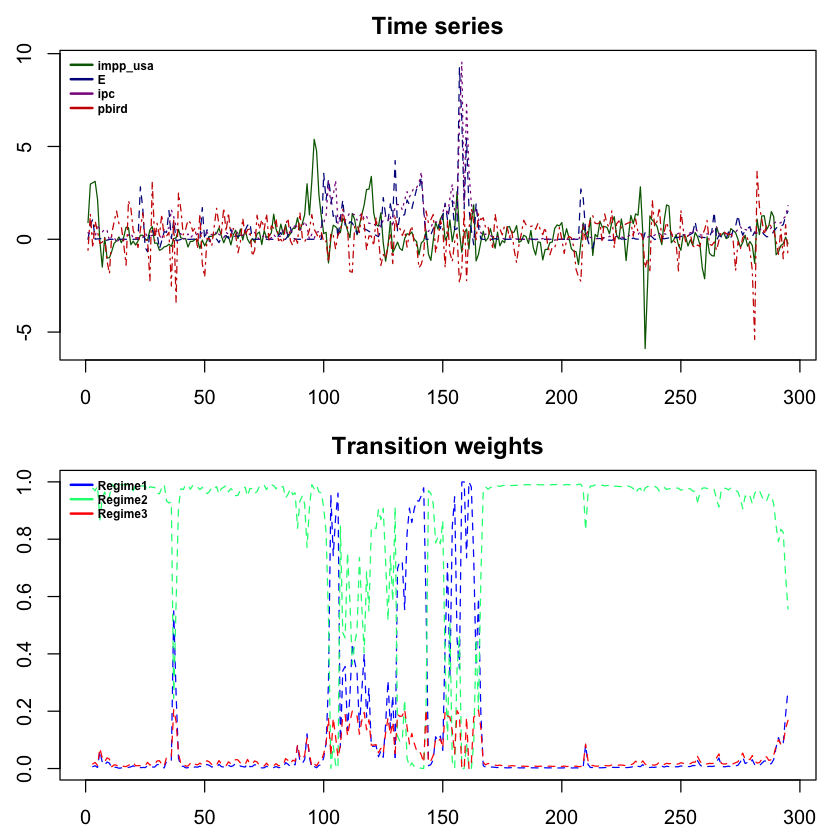

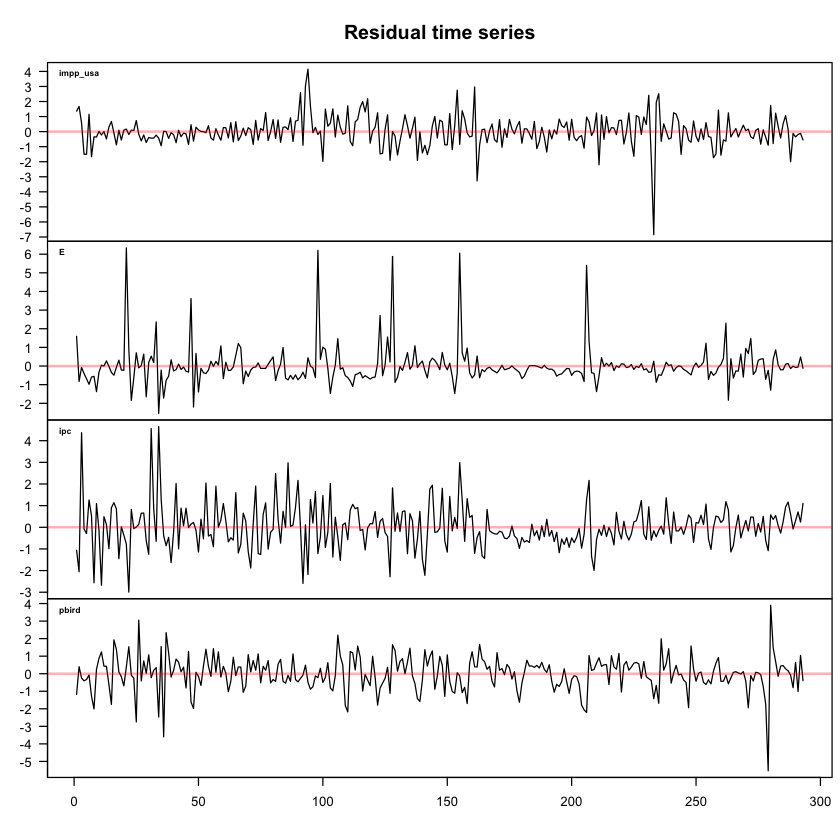

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



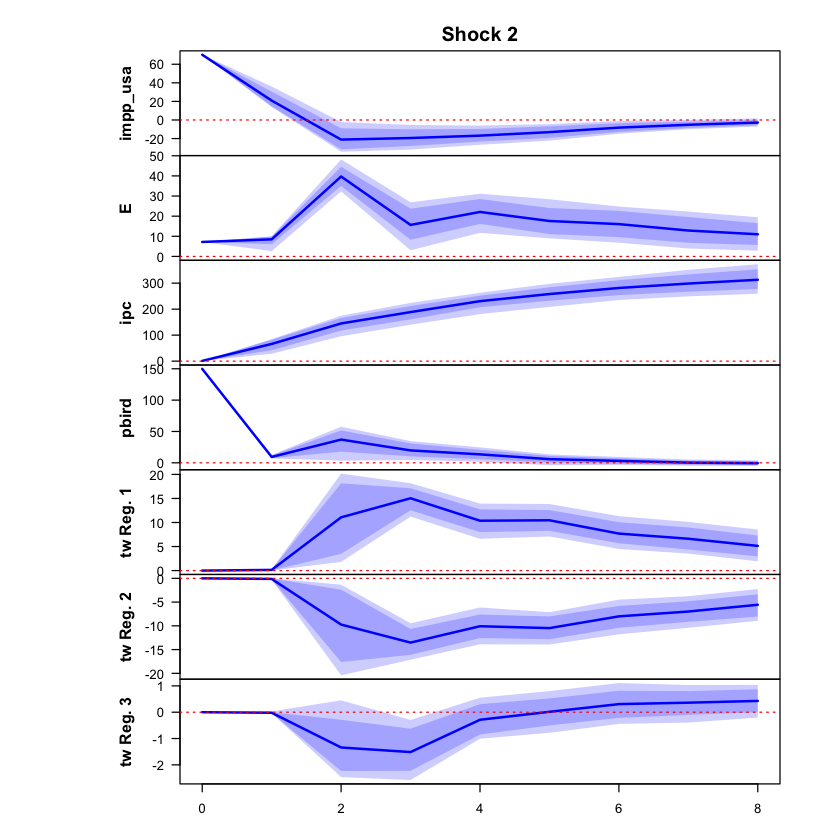

 >>> Linear IRF ( 1  shock units)


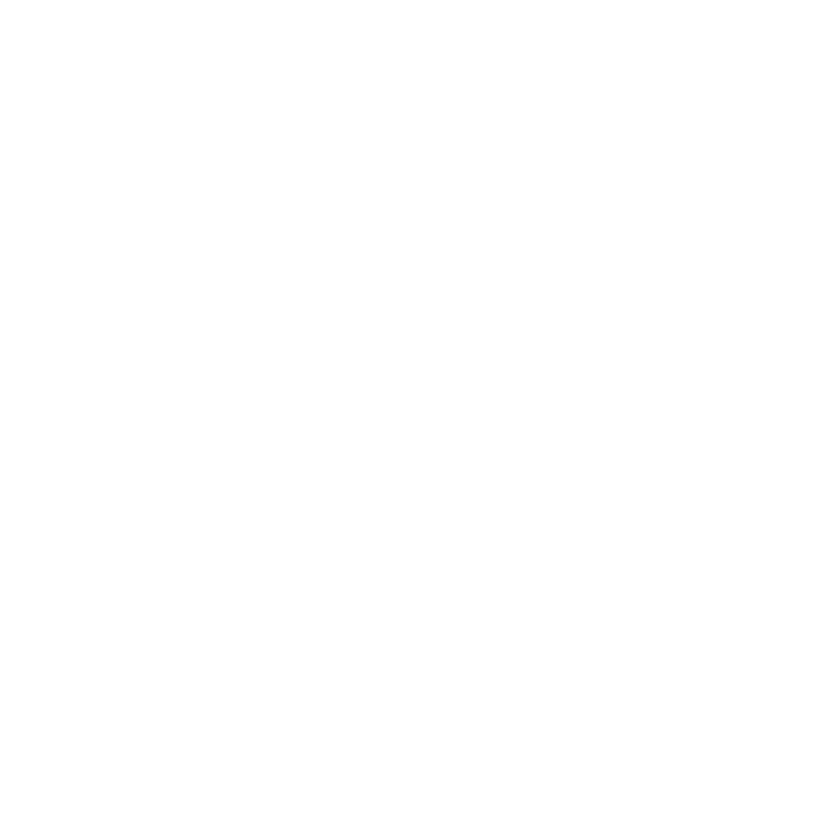

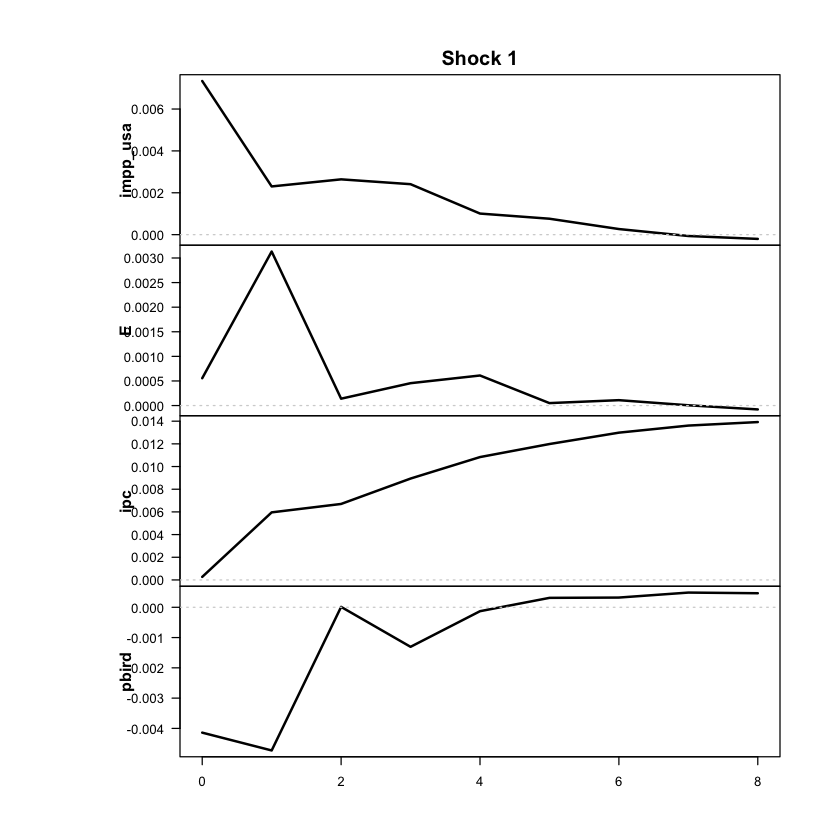

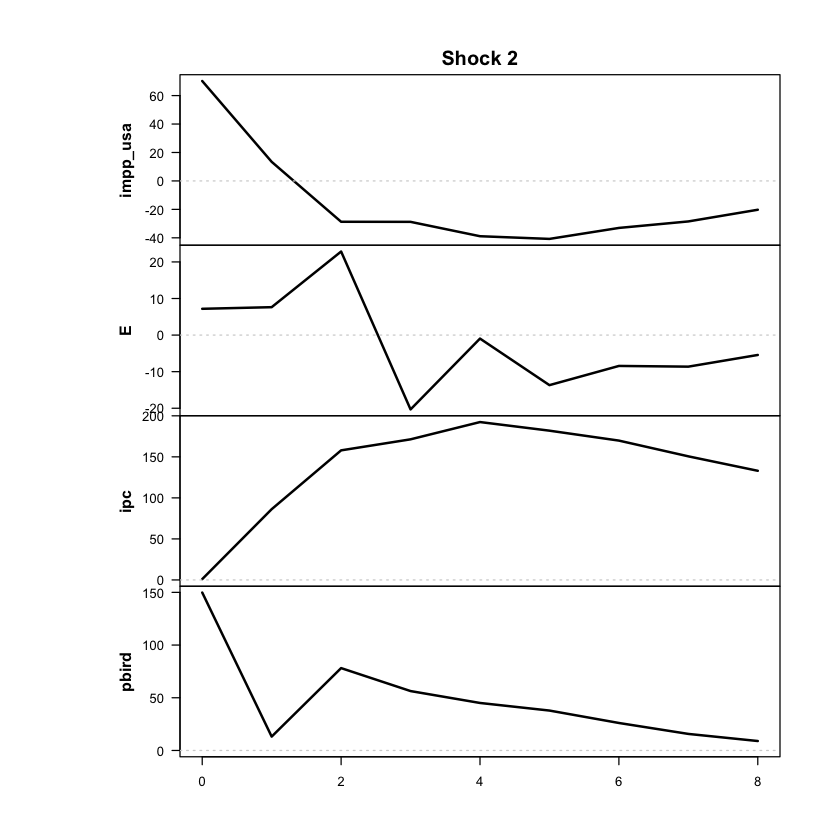

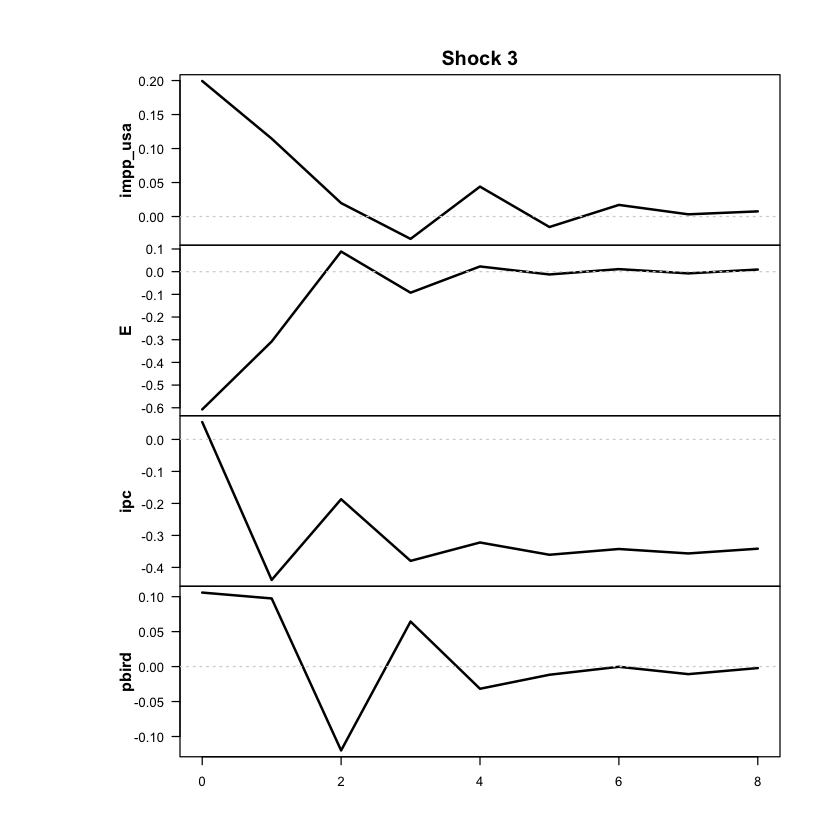

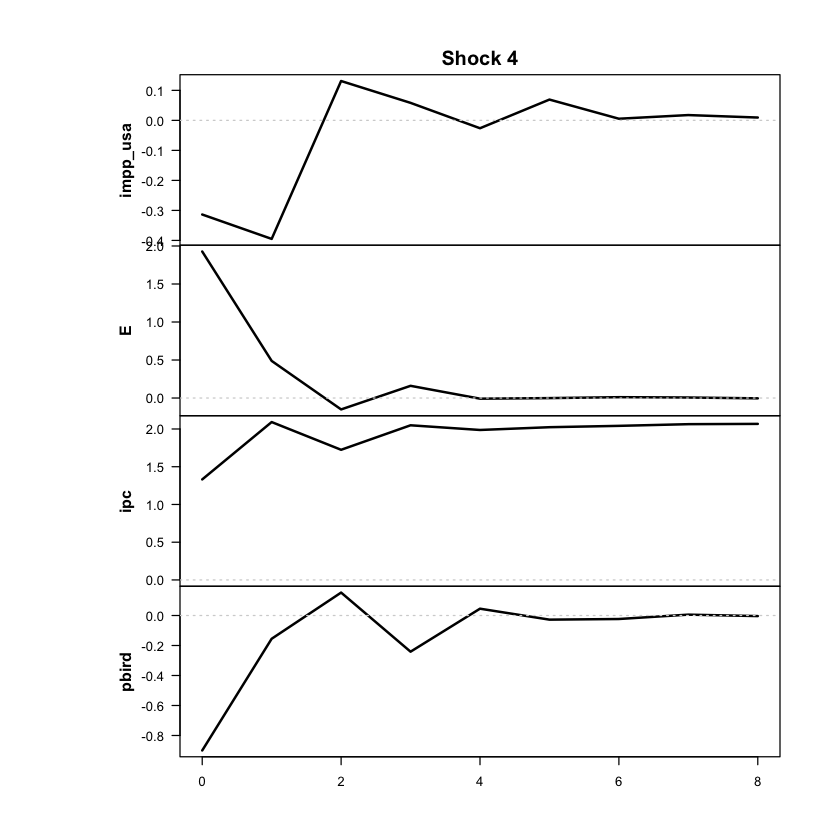

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



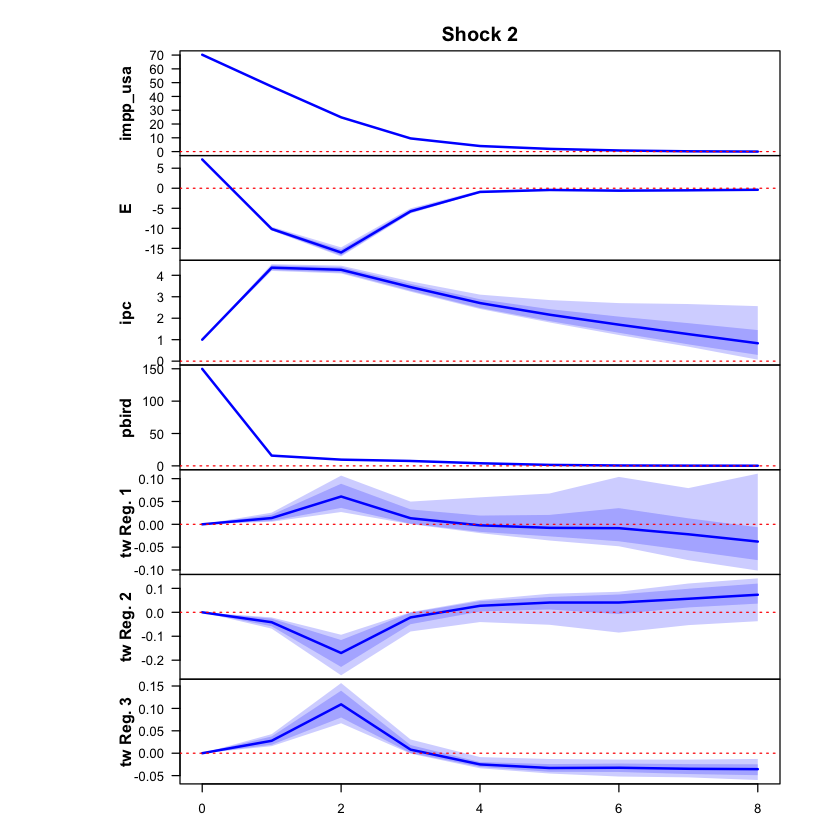

 >>> Linear IRF ( 1  shock units)


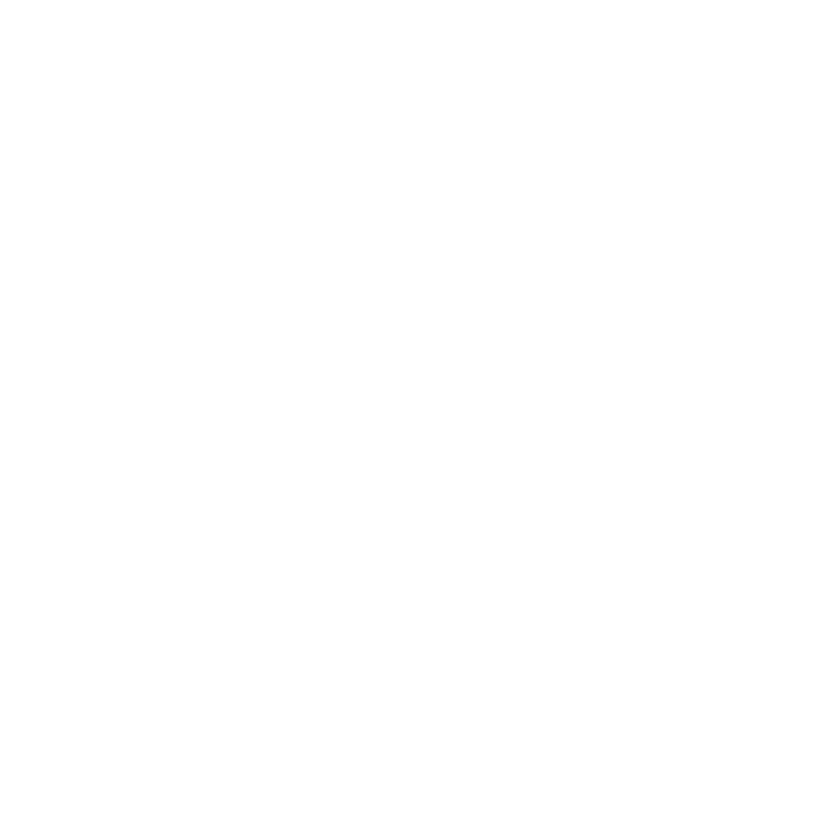

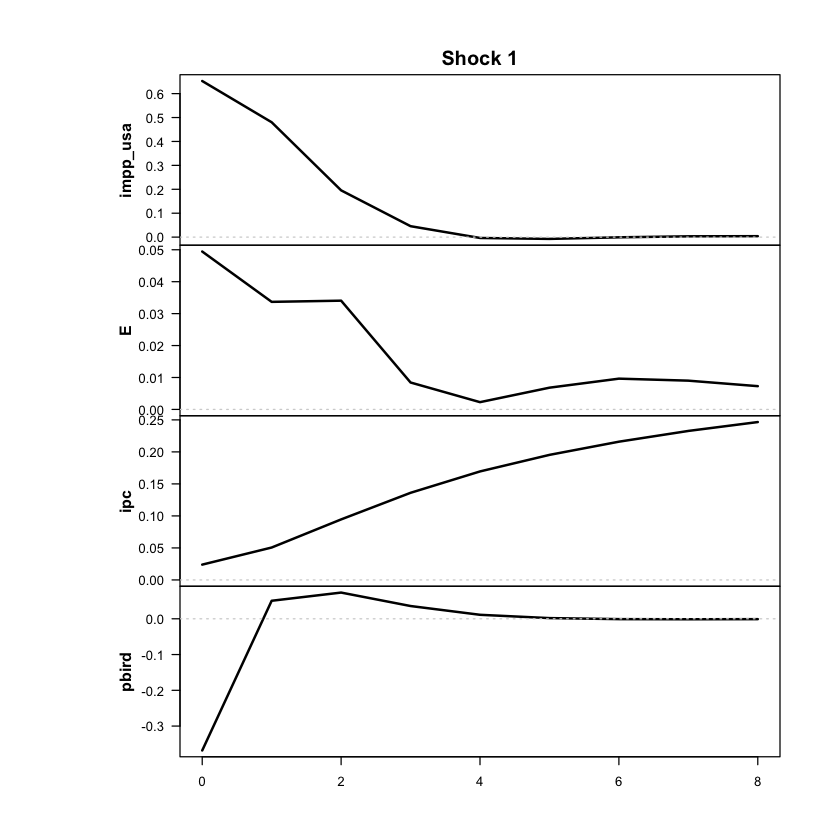

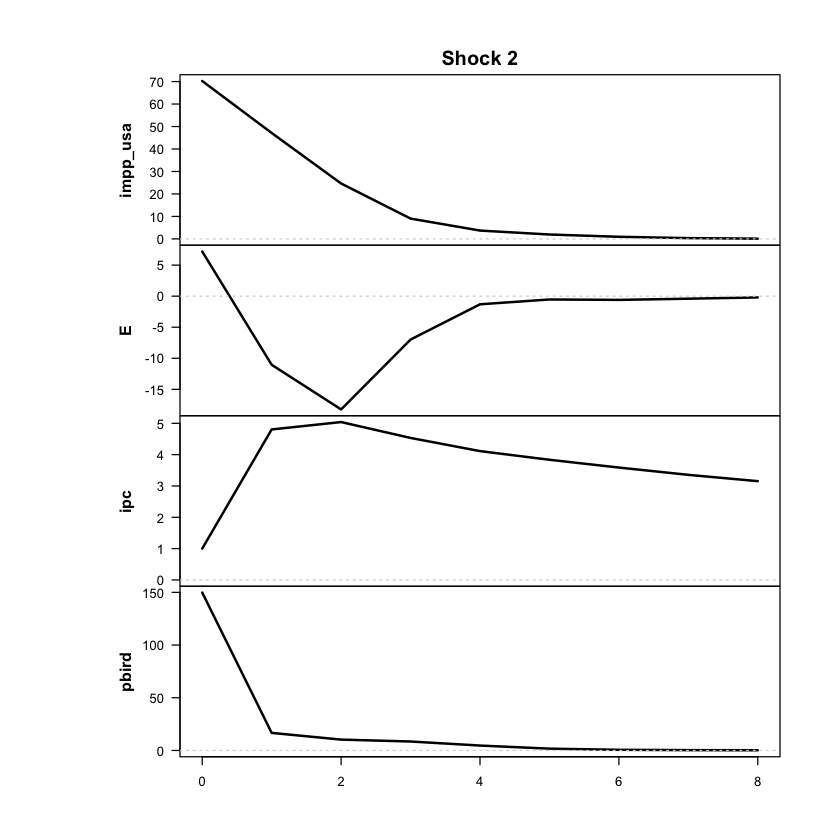

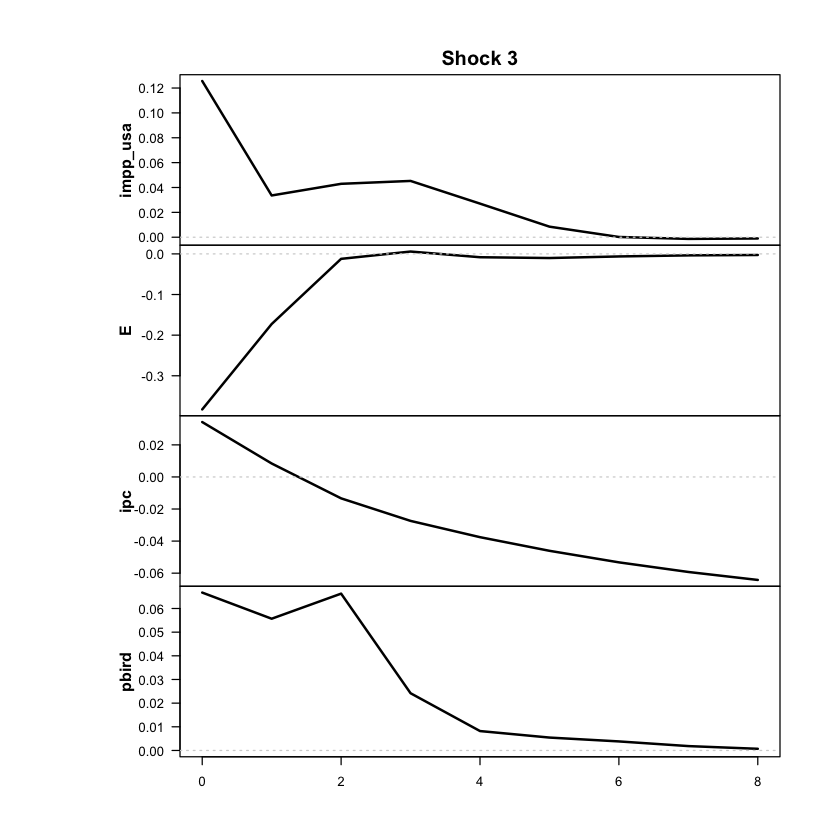

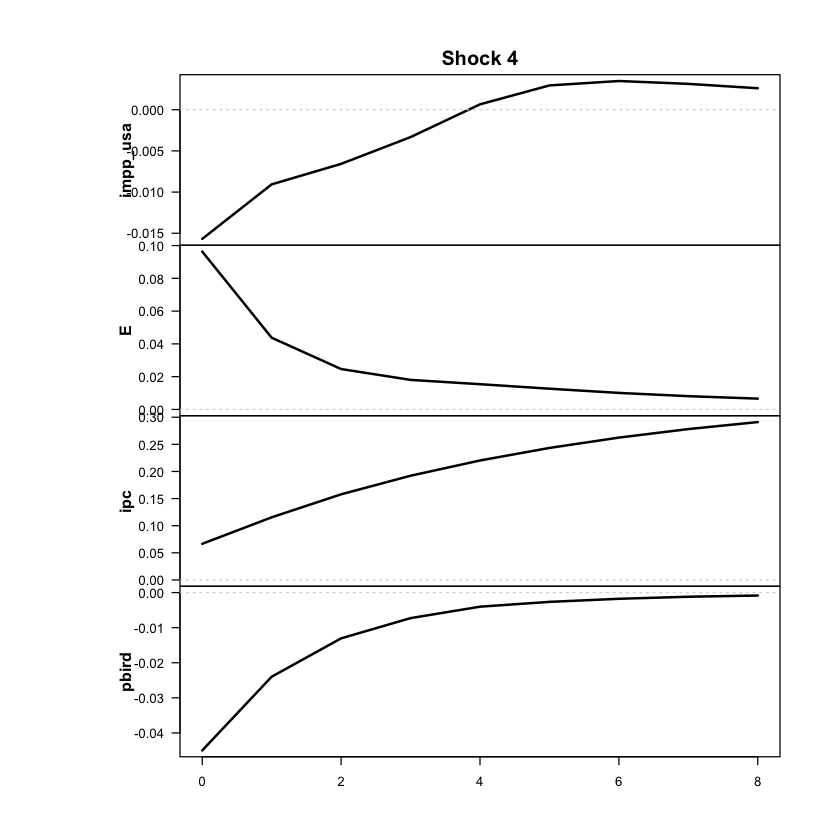

+++++++++ RÉGIMEN  3 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



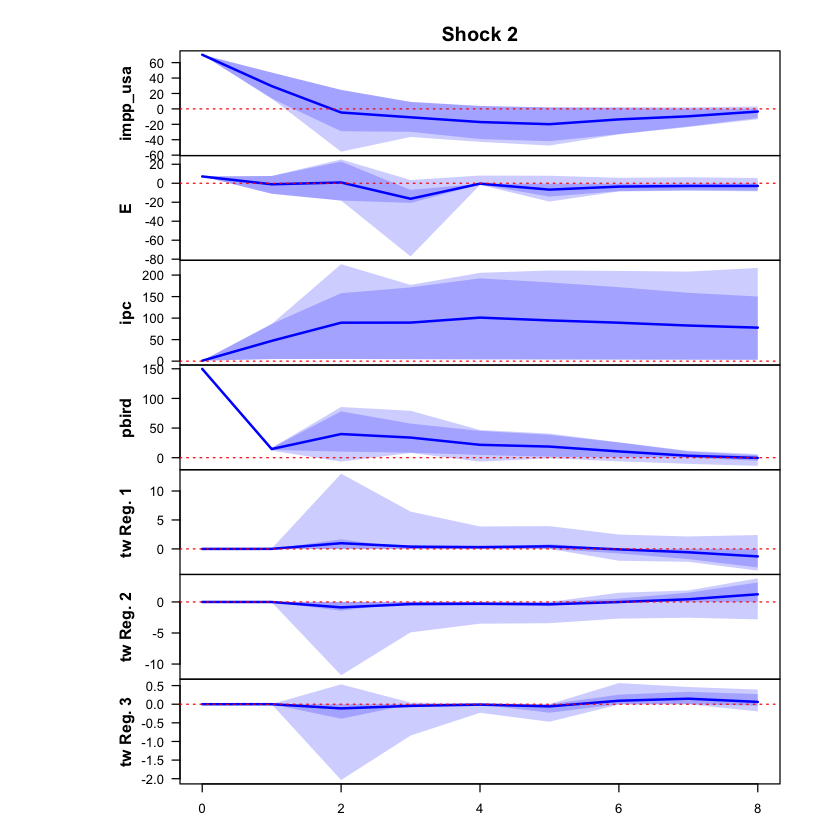

 >>> Linear IRF ( 1  shock units)


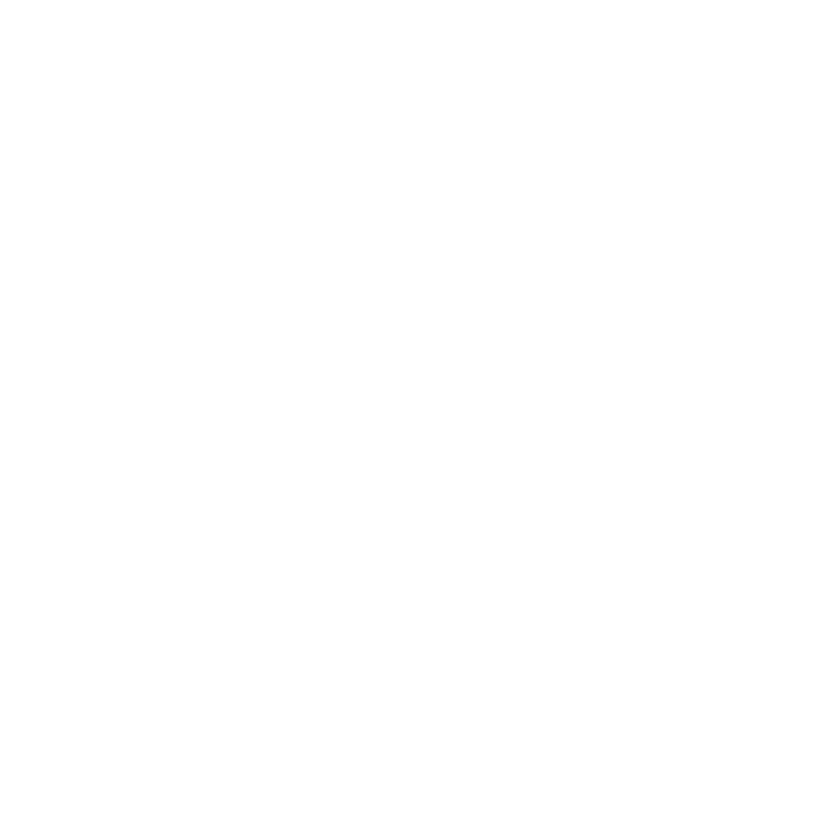

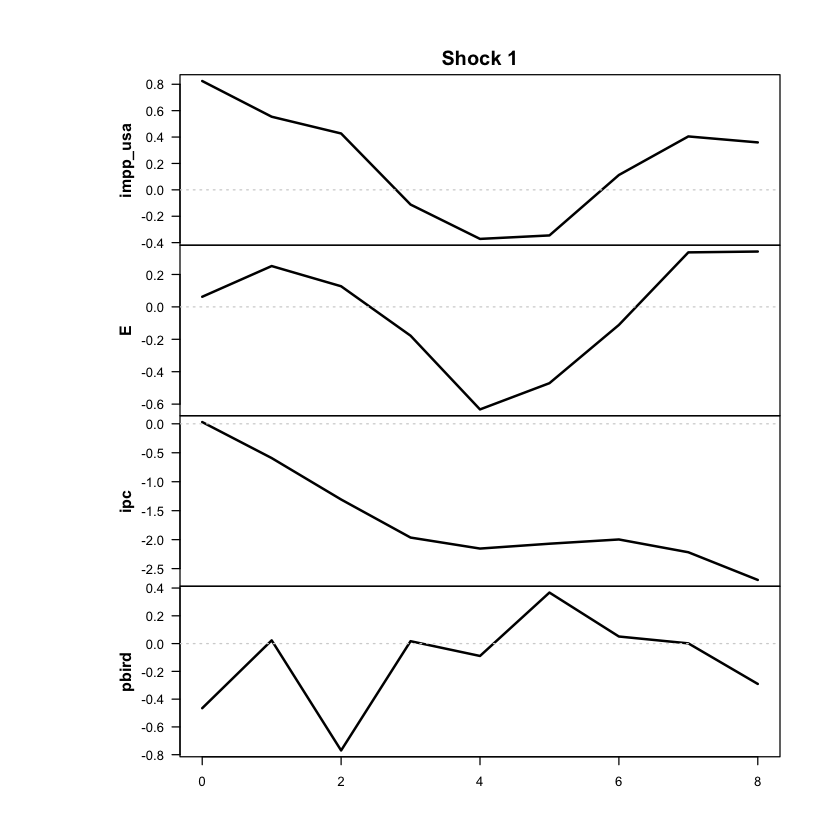

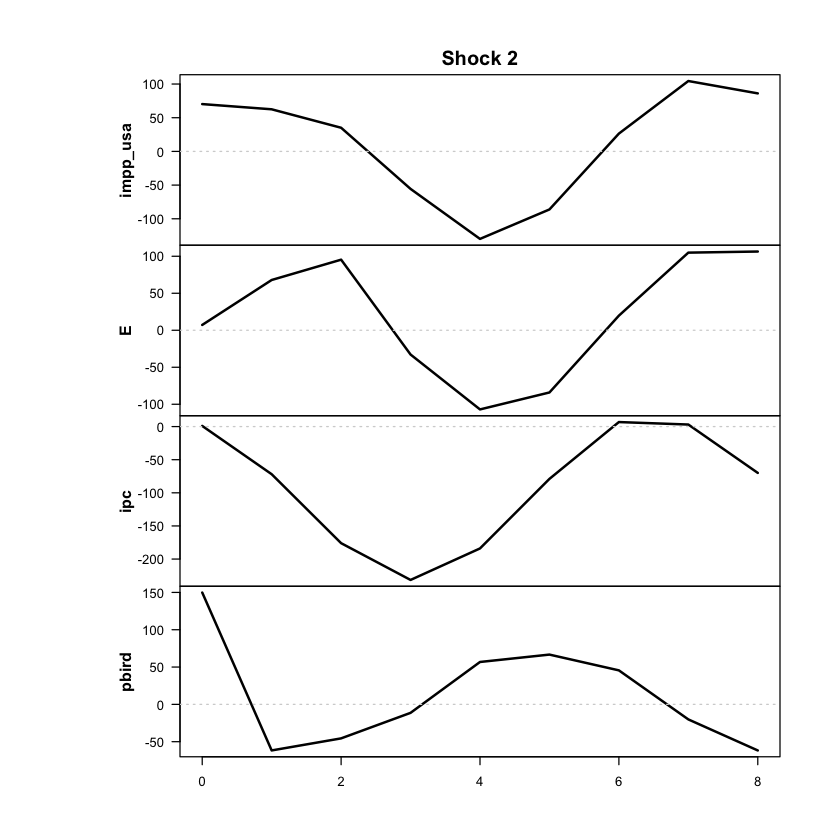

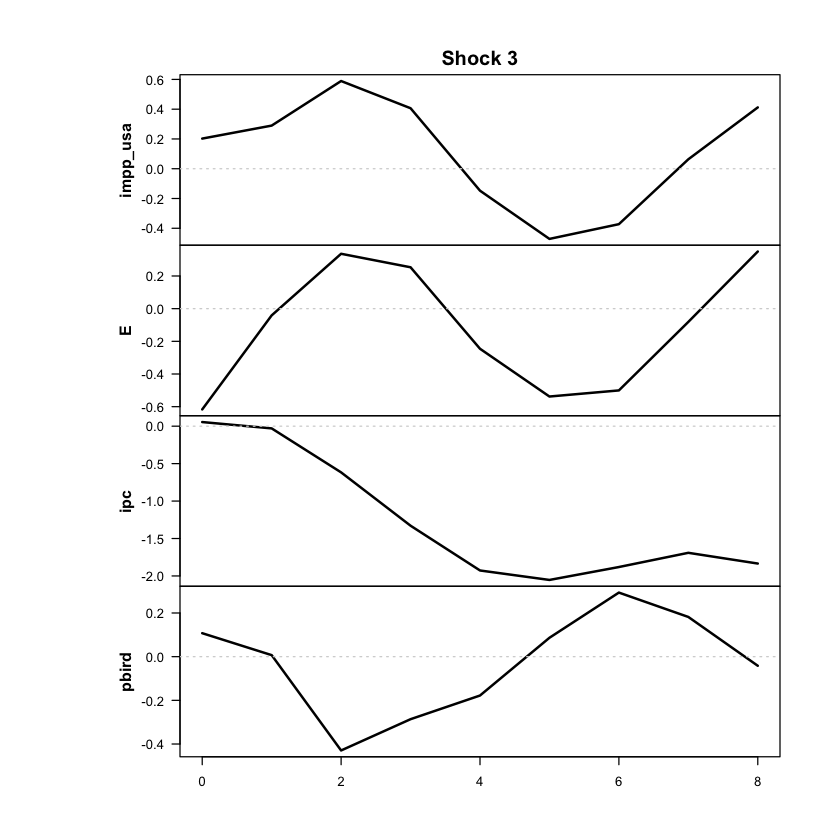

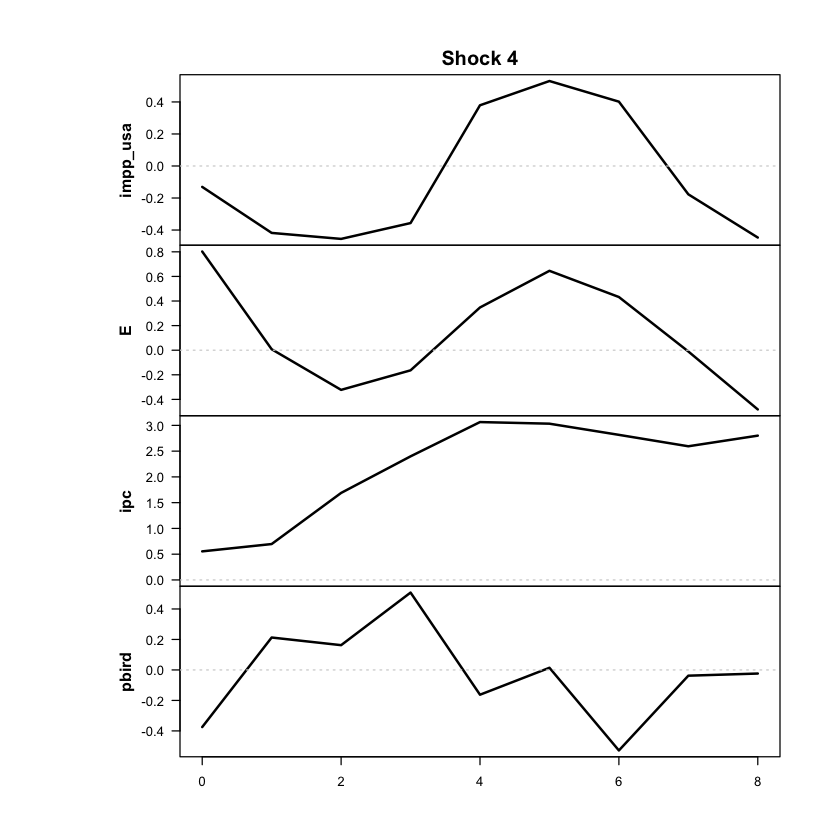

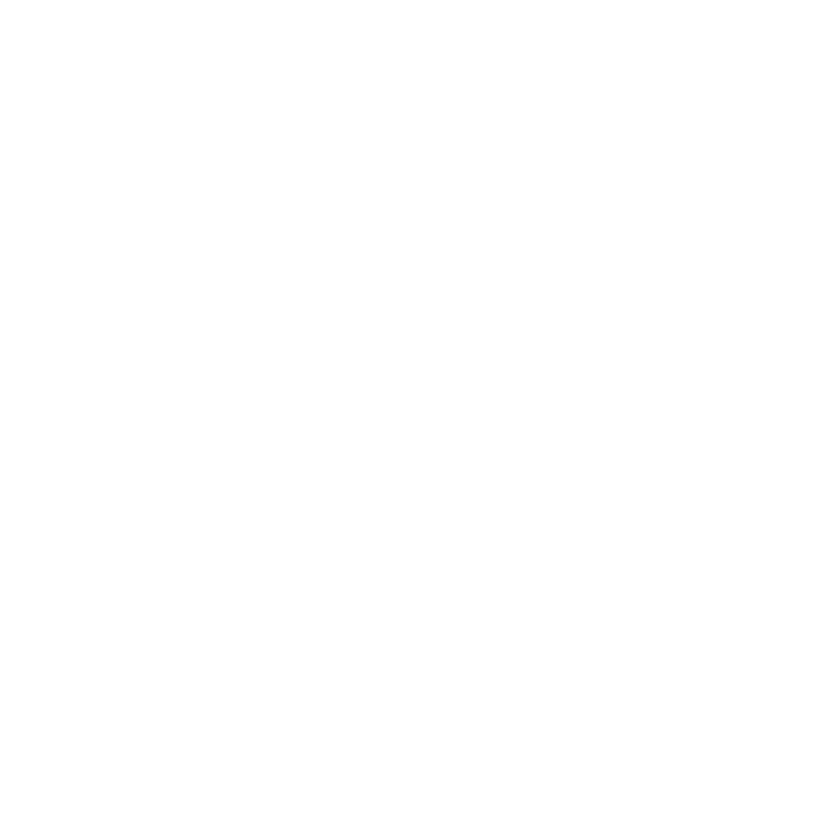

In [39]:
res <- run_mlogit(
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual'
  feature_lag = 2,
  n_regimes = 3,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [40]:
ic_mlogit3_p2 <- criterios_info(res, "MLOGIT 3 reg p=2")
print(ic_mlogit3_p2)

            modelo regimenes parametros  loglik  AIC     HQ    BIC
1 MLOGIT 3 reg p=2         3        142 -883.02 2050 2259.3 2572.6


In [41]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: mlogit | regímenes: 3 | rezagos: 2 | errores: Gaussian 
Transición mlogit (parámetros gamma, escalados): -1.264, 1.413, 4.833, -2.933 
Cambios de régimen dominante según la inflación de t-1:
 de_regimen a_regimen inflacion_trim_pct inflacion_anual_pct
          2         1               32.7                 210
Trimestres por régimen (régimen de mayor peso): régimen 1 = 31 | régimen 2 = 262 | régimen 3 = 0 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2 Régimen 3
impp_usa      0.65      0.77       NaN
E            48.87      8.48       NaN
ipc          62.43      8.65       NaN
pbird         0.00      0.61       NaN


In [42]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -883.02              NA    NA         NA         32/261/0
             2 -884.65              NA    NA         NA        221/50/22
             3 -886.80              NA    NA         NA        221/28/44
             4 -889.25              NA    NA         NA         0/269/24
             5 -890.60              NA    NA         NA         261/32/0
             6 -900.45              NA    NA         NA         28/265/0
             7 -900.50              NA    NA         NA         265/28/0
             8 -907.83              NA    NA         NA         213/80/0
             9 -913

In [43]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

mlogit Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 2, M = 3, d = 4, #parameters = 142, #observations = 293 x 4
  Switching variables: ipc with 1 lag.

Regime 1 
Weight params: -0.85,  1.45 
Regime means:  0.17,  1.91,  2.62, -0.12

   Y      phi0          A1                                 A2                  
1 y1 = [  0.32 ] + [  0.39 -0.03 -0.26 -0.30 ] y1.1 + [  0.03  0.24  0.00 -0.17
2 y2   [  1.68 ]   [  0.27  0.42 -0.39 -0.08 ] y2.1   [  0.23  0.09  0.08  0.18
3 y3   [  1.16 ]   [  0.69  1.04 -0.73 -0.06 ] y3.1   [  0.01 -0.05  0.54  0.58
4 y4   [ -0.53 ]   [ -0.28 -0.18  0.17  0.03 ] y4.1   [  0.28  0.25 -0.06  0.16
             Omega                     1/2     
1 ] y1.2 + [  0.19 -0.53 -0.26  0.39 ]     eps1
2 ] y2.2   [ -0.53  2.99  1.90 -1.36 ]     eps2
3 ] y3.2   [ -0.26  1.90  1.40 -0.85 ]     eps3
4 ] y4.2   [  0.39 -1.36 -0.85  0.93 ]     eps4

Regime 2 
Weight params:  5.02, -2.81 
Regime means: 0.21, 0.13, 0.23, 0.30

   Y 

In [44]:
shock_mlogit3_p2 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_mlogit3_p2 <- 2
shock_mlogit3_p2

Efecto de impacto de cada shock (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa   2e-04  0.0067  0.0055 -0.0087
  E          1e-04  0.0060 -0.1453  0.4611
  ipc        1e-04  0.0007  0.0108  0.2645
  pbird     -1e-04  0.0144  0.0029 -0.0250

Participación de E en el efecto de cada shock:
shock_1 shock_2 shock_3 shock_4 
   0.07    0.04    0.93    0.76 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
  0.401   0.115  -0.074   0.574 

>>> Shock sugerido como cambiario: 3 (confirmalo: debe mover mucho a E y poco a ipc )


Shock 3 
      3

In [62]:
exists("out_impp_usa_mlogit3_p2_acum")    # notebook de 3 regímenes, p=2

[1] FALSE

### ERPT — mlogit3 p2

Correr solo si el modelo pasó el diagnóstico.

In [ ]:
out_impp_usa_mlogit3_p2 <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_mlogit3_p2)

In [ ]:
out_impp_usa_mlogit3_p2_acum <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_mlogit3_p2,
                      definicion = "acumulado")

In [ ]:
graficar_transicion(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_mlogit3_p2_sincap")

## STVAR con transición logit multinomial (mlogit), 3 regímenes, p = 3

`sstvars` no admite la transición logística con más de 2 regímenes; `mlogit` es la alternativa de transición suave. El peso de cada régimen depende de la inflación de t-1 a través de un logit multinomial (constante y pendiente propias de cada régimen). No tiene umbral c ni γ: `resumen_modelo` muestra la inflación en la que cambia el régimen dominante y avisa si los regímenes no quedan ordenados. Riesgo conocido: que el régimen de inflación más alta quede con pocos trimestres y covarianza casi singular.

Desvíos usados para escalar:
  impp_usa          E        ipc      pbird 
0.02758807 0.23928824 0.19858620 0.02774553 


Using 6 cores for 500 estimations rounds...

PHASE 1: Estimating all the parameters with a genetic algorithm...

Results from the genetic algorithm:

The lowest loglik:  -2528.045

The largest loglik: -941.395

PHASE 2: Estimating all the parameters with a variable metric algorithm...

Results from the variable metric algorithm:

The lowest loglik:  -2126.968

The largest loglik: -815.342

Filtering inappropriate estimates...

Filtered through 393 inappropriate  estimates with a larger log-likelihood

Calculating approximate standard errors...

Warning message in warn_eigens(ret, allow_unstab = allow_unstab):
“Regime 1 has near-unit-roots! Consider building a model from the next-largest local maximum with the function 'alt_stvar' by adjusting its argument 'which_largest' (or use the function 'filter_estimates').”
Finished!




========= Unstructured fitted model ==========


The log-likelihood of the supplied model:    -1172.708
Constrained log-likelihood prior estimation: -1278.617

The log-likelihood after robust estimation:  -1201.899

The log-likelihood after final estimation:   -1201.899

Calculating approximate standard errors...



========= Structured fitted model (heteroskedasticity) ==========
Saving trained models to models/ folder

 >>> DIAGNOSTIC PLOTS


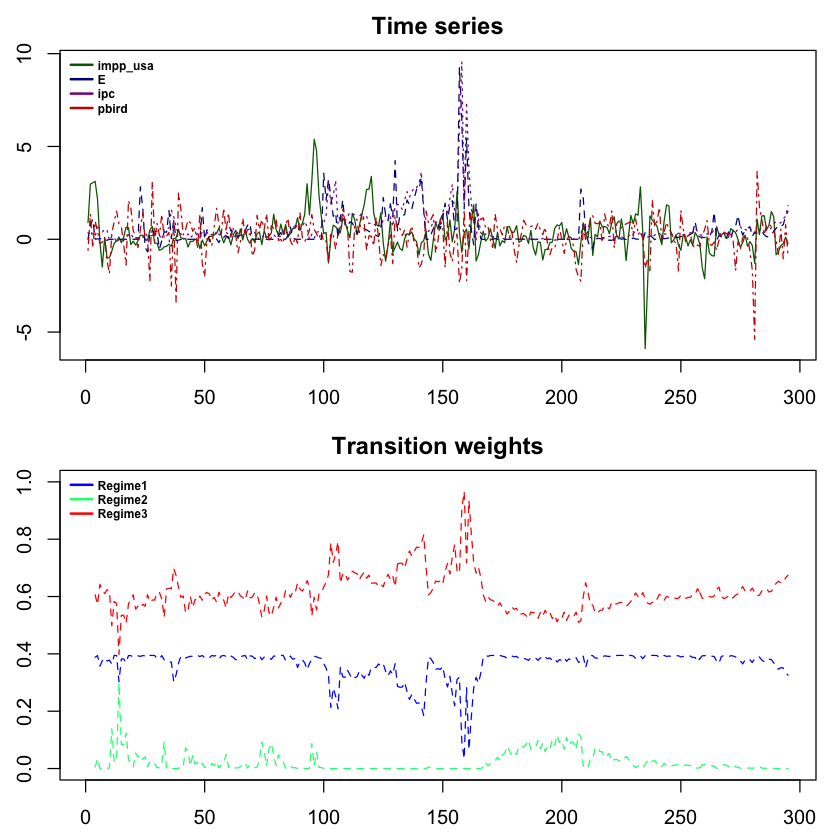

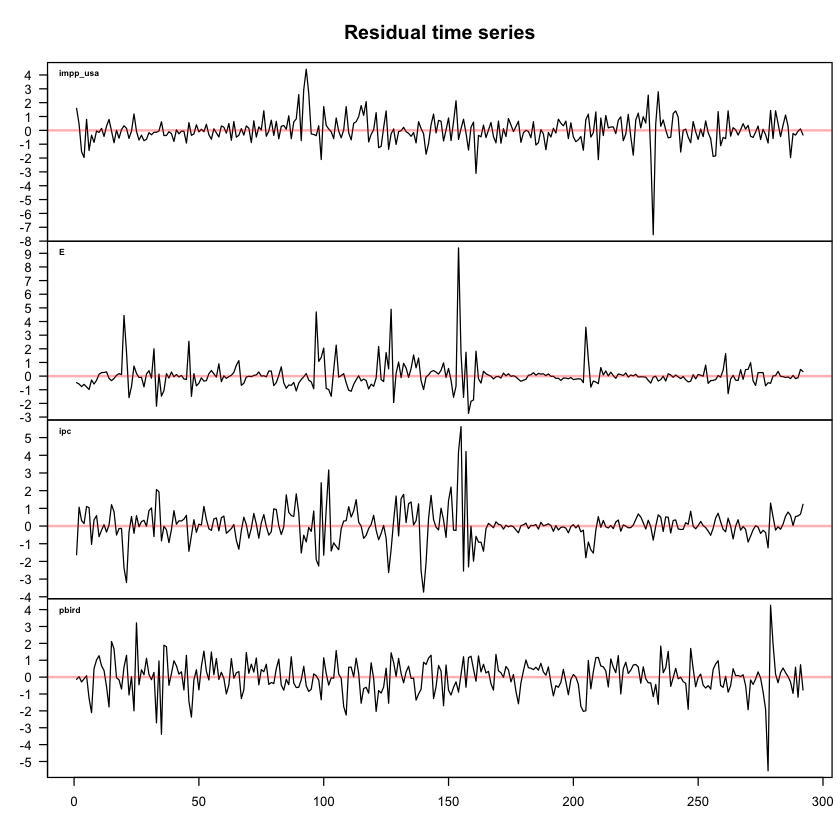

+++++++++ RÉGIMEN  1 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



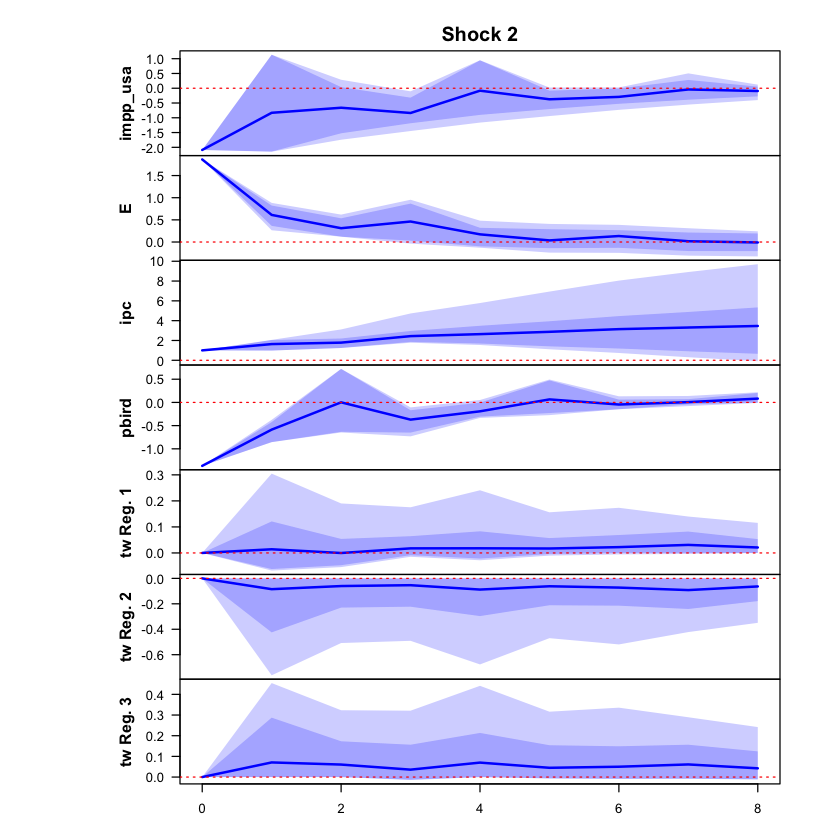

 >>> Linear IRF ( 1  shock units)


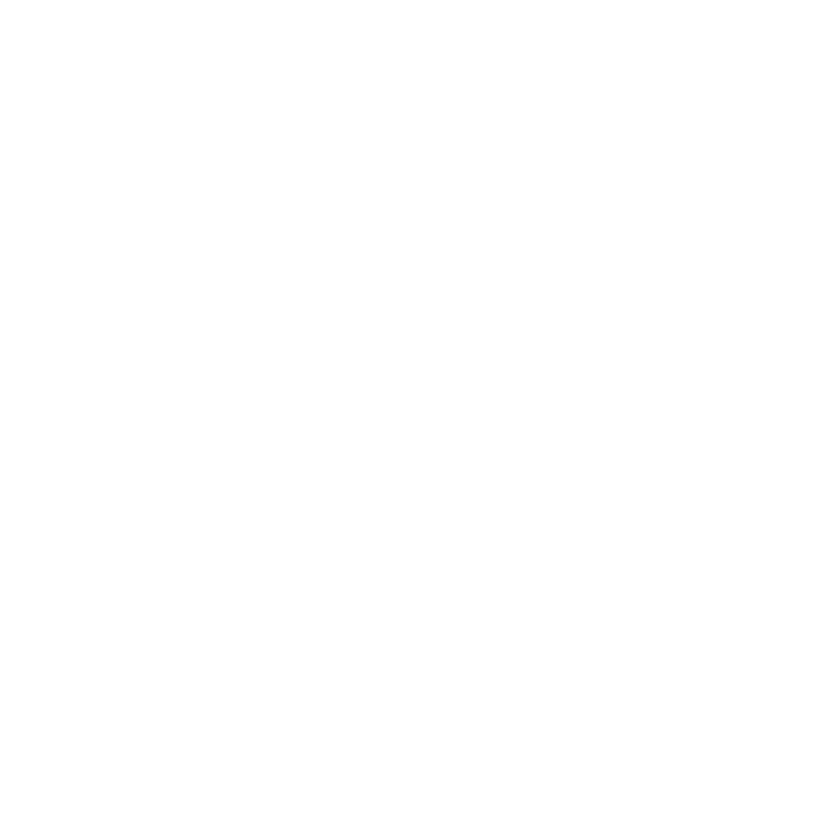

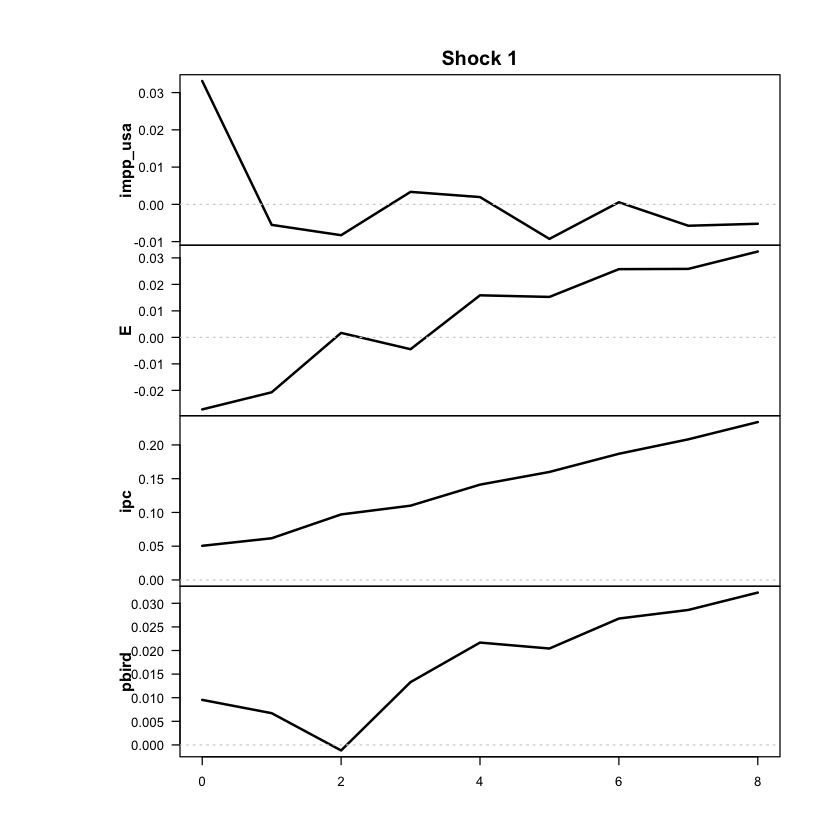

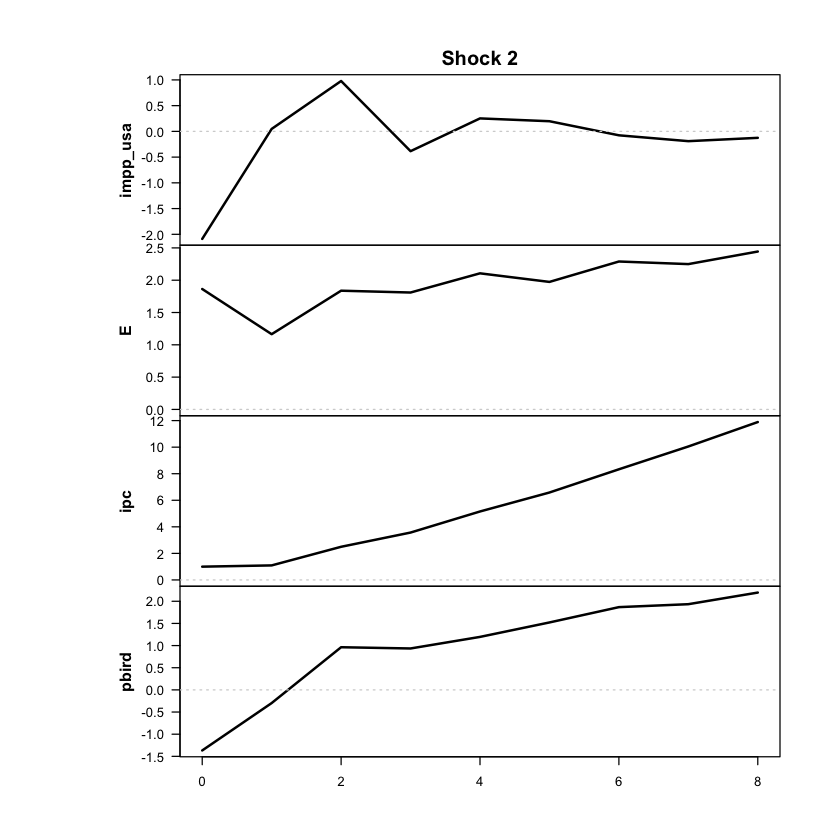

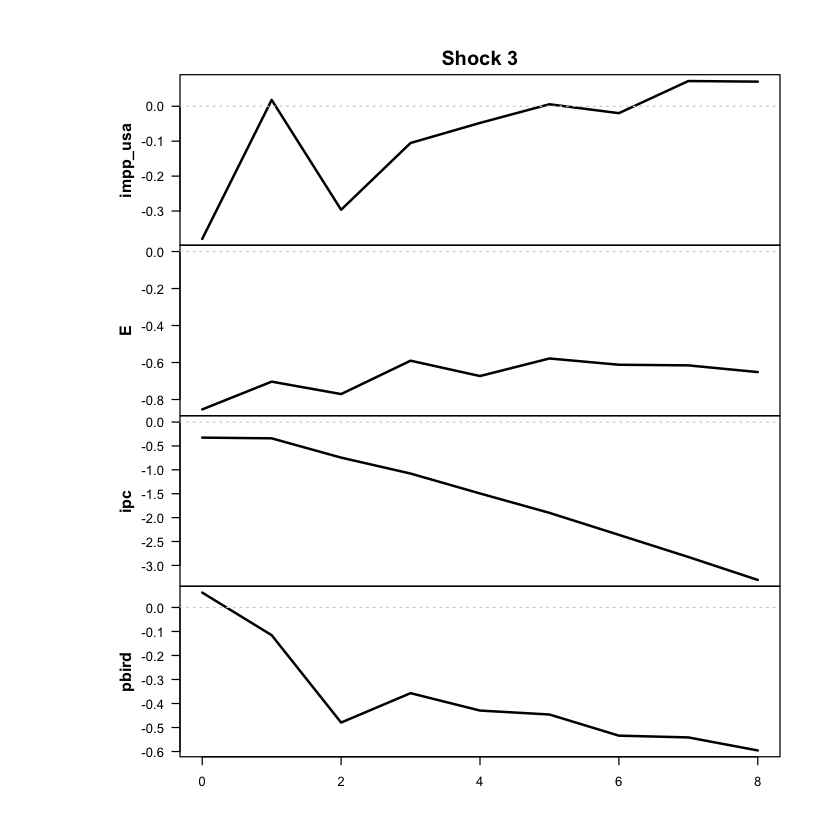

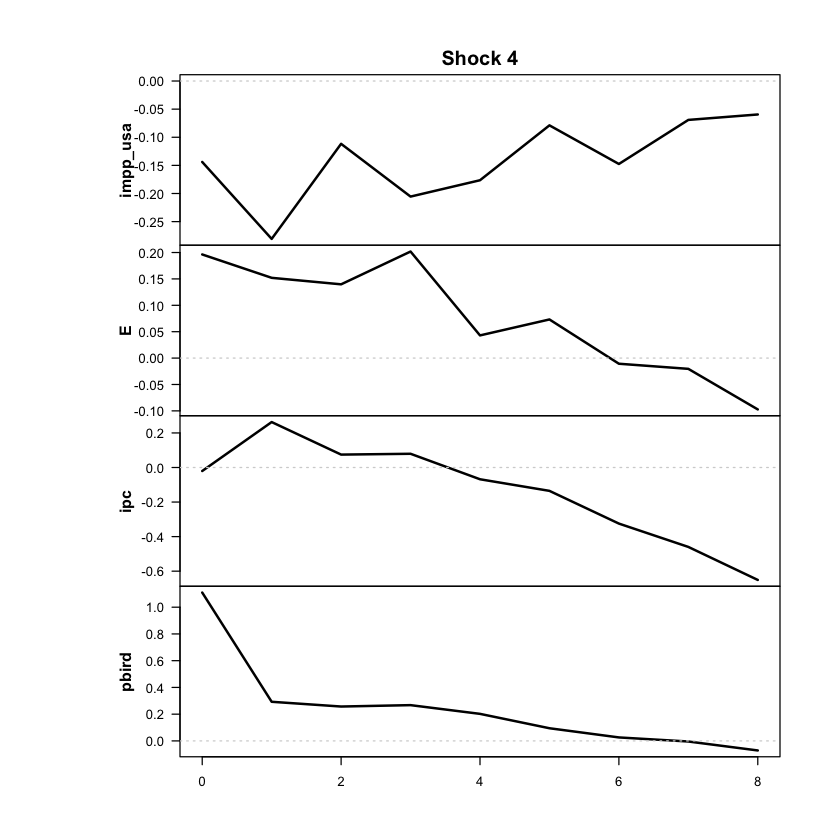

+++++++++ RÉGIMEN  2 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



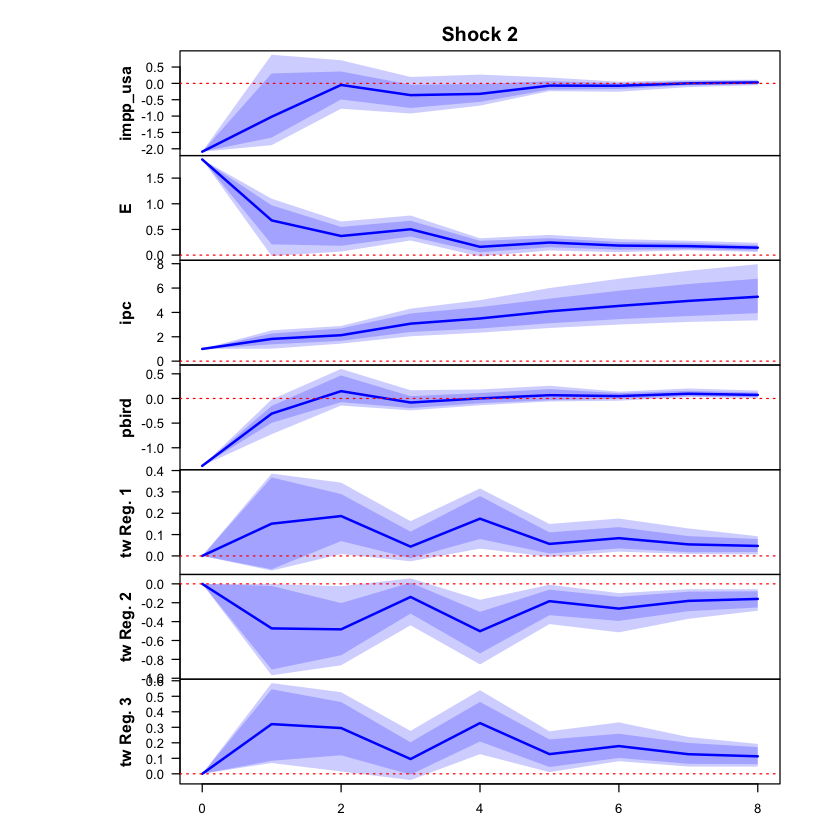

 >>> Linear IRF ( 1  shock units)


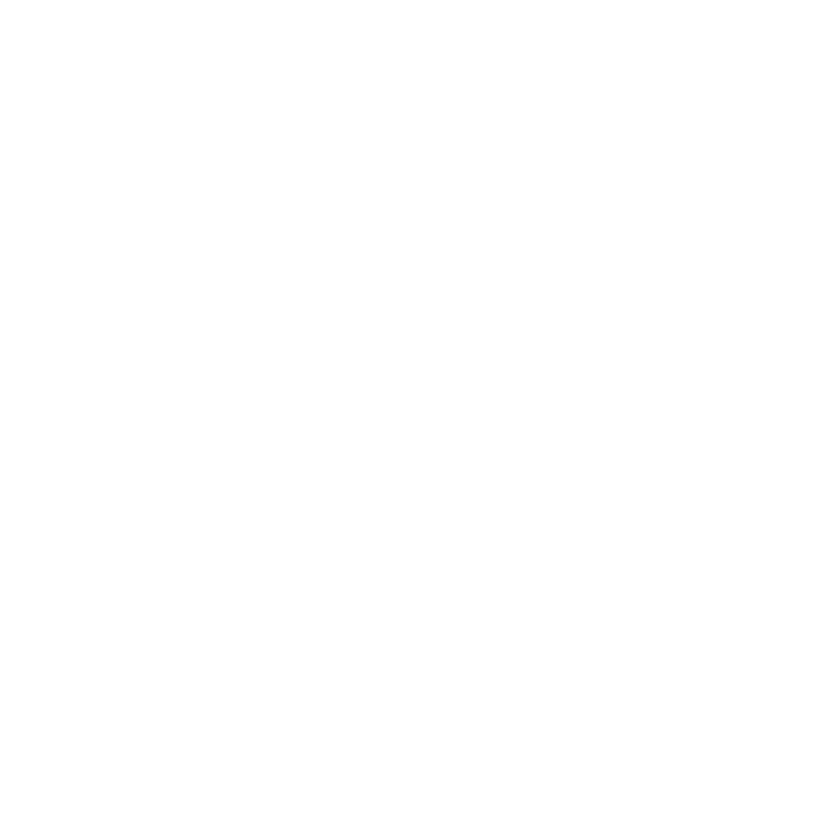

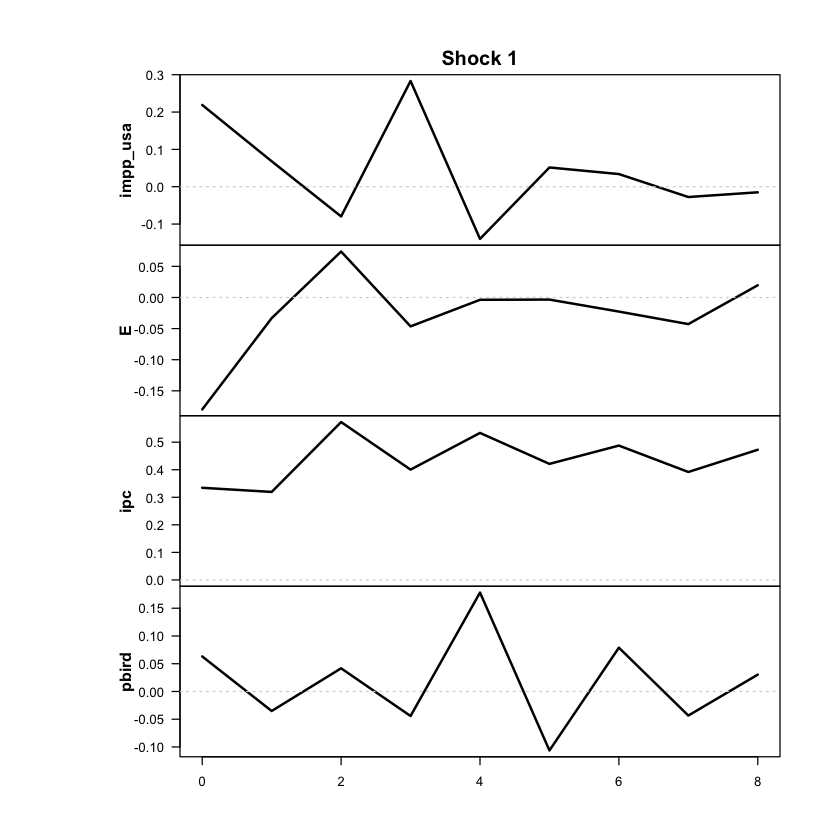

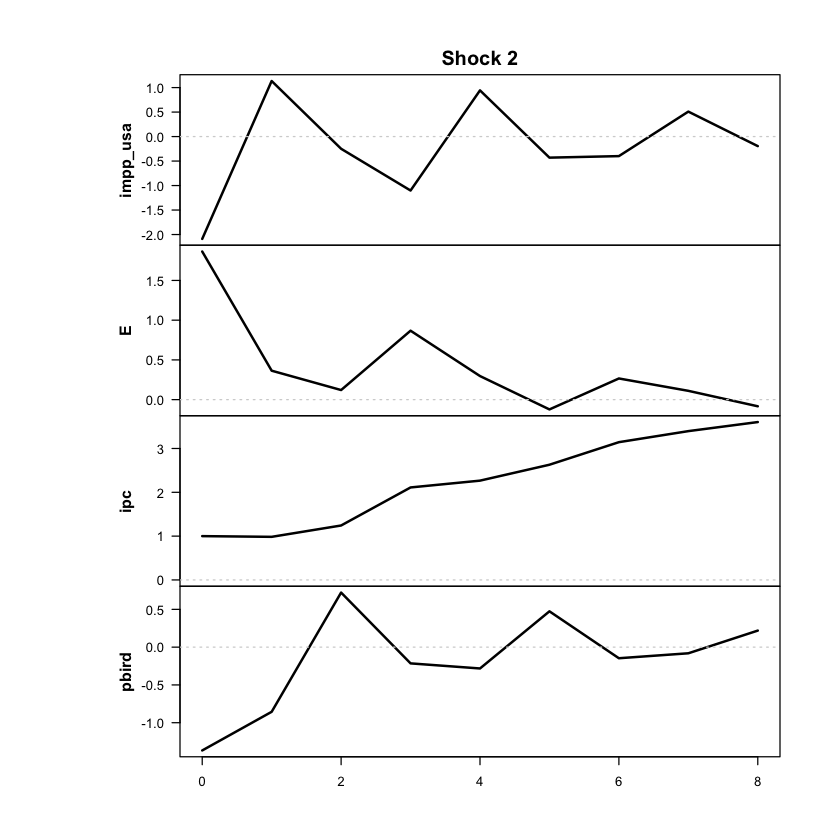

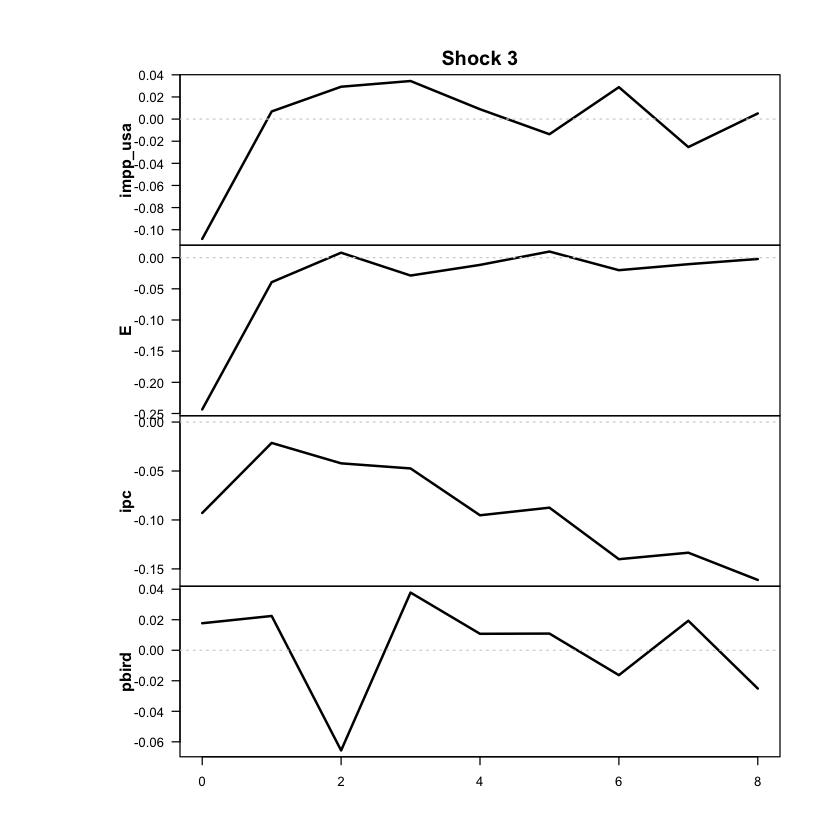

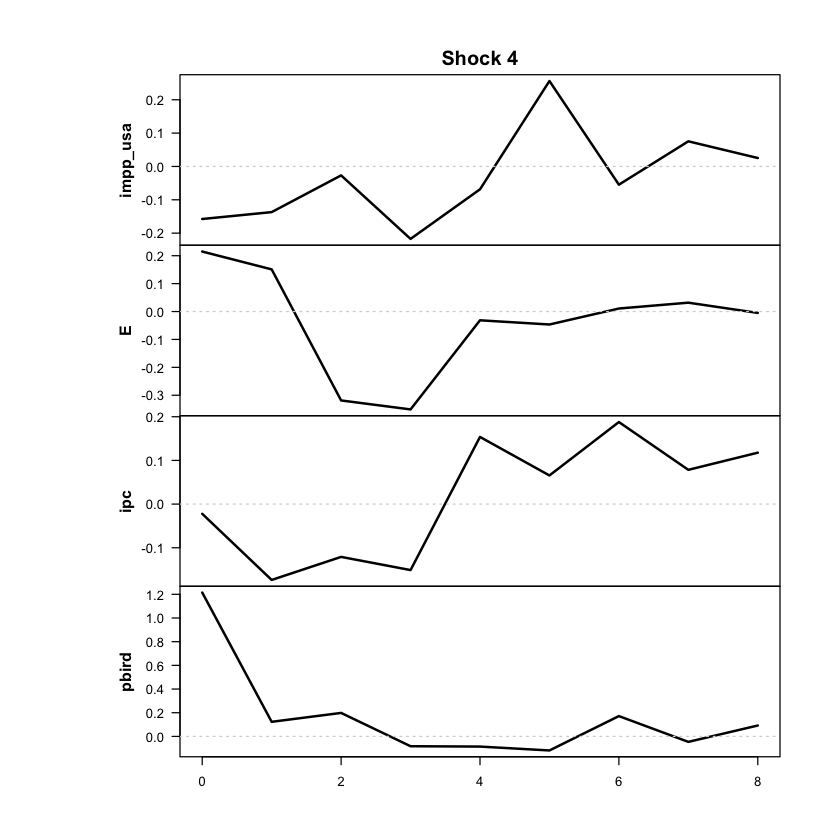

+++++++++ RÉGIMEN  3 +++++++++
 >>> GIRF ( 1  shock units)


Using 6 cores to estimate 250 GIRFs for 1 structural shocks, each based on 500 Monte Carlo repetitions.

Estimating GIRFs for structural shock 2...

Finished!



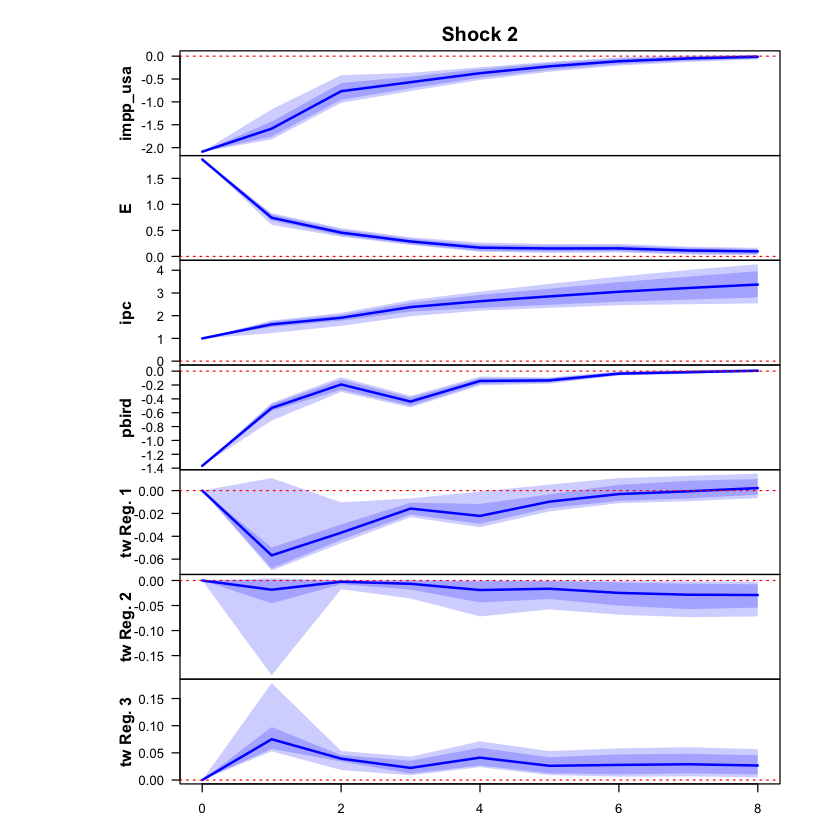

 >>> Linear IRF ( 1  shock units)


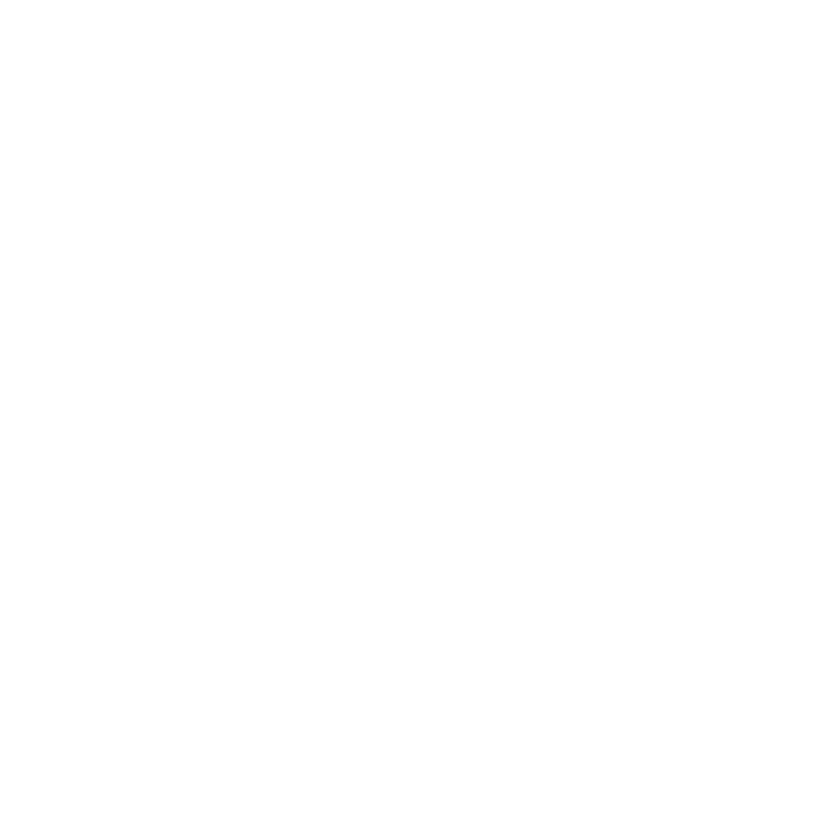

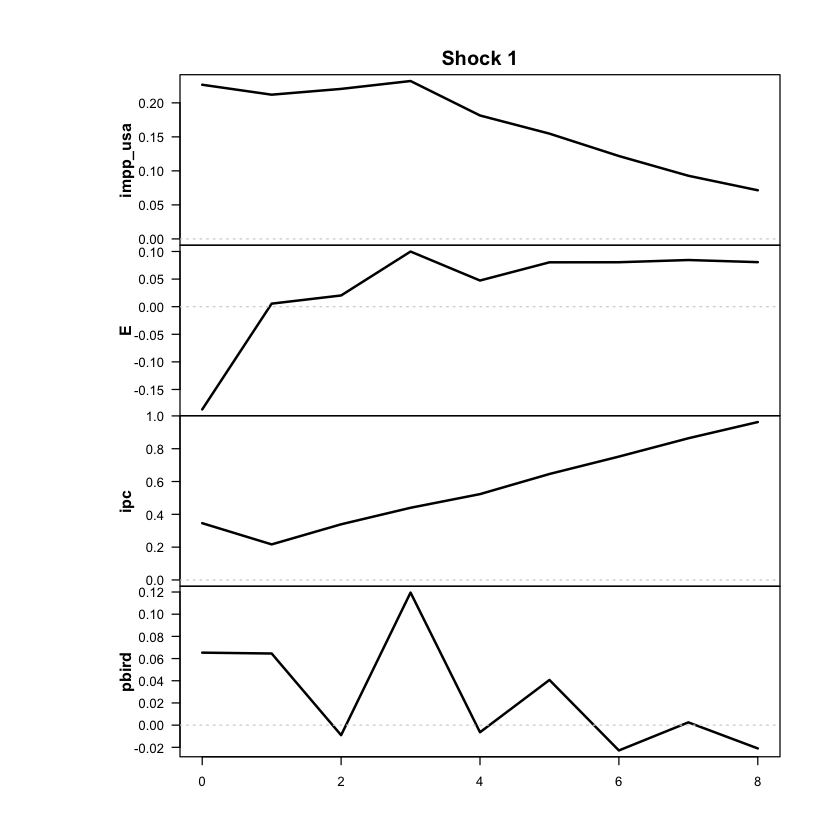

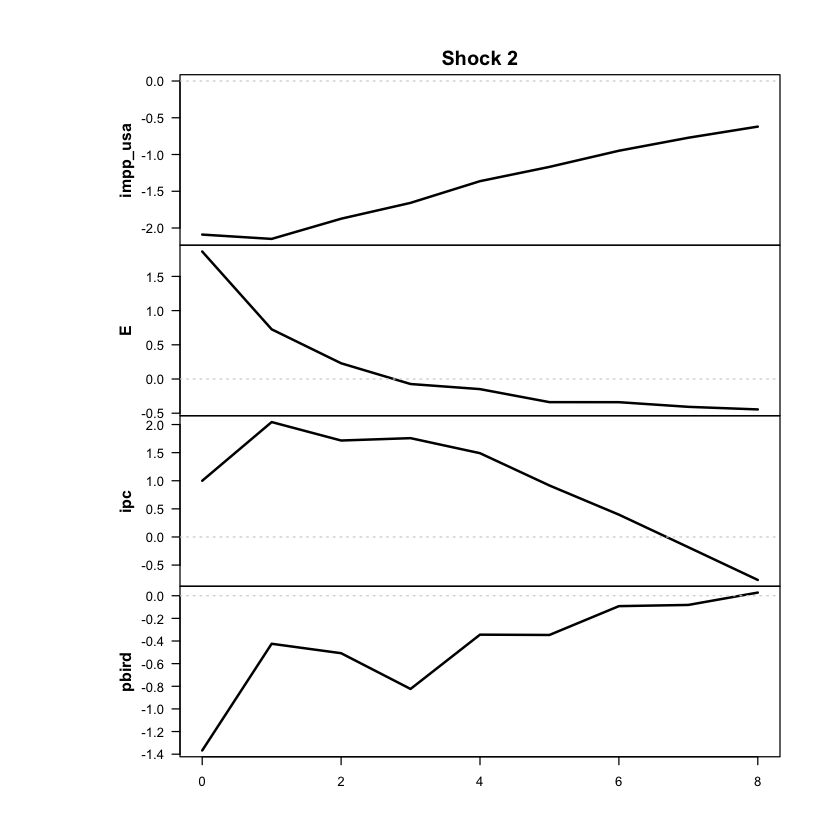

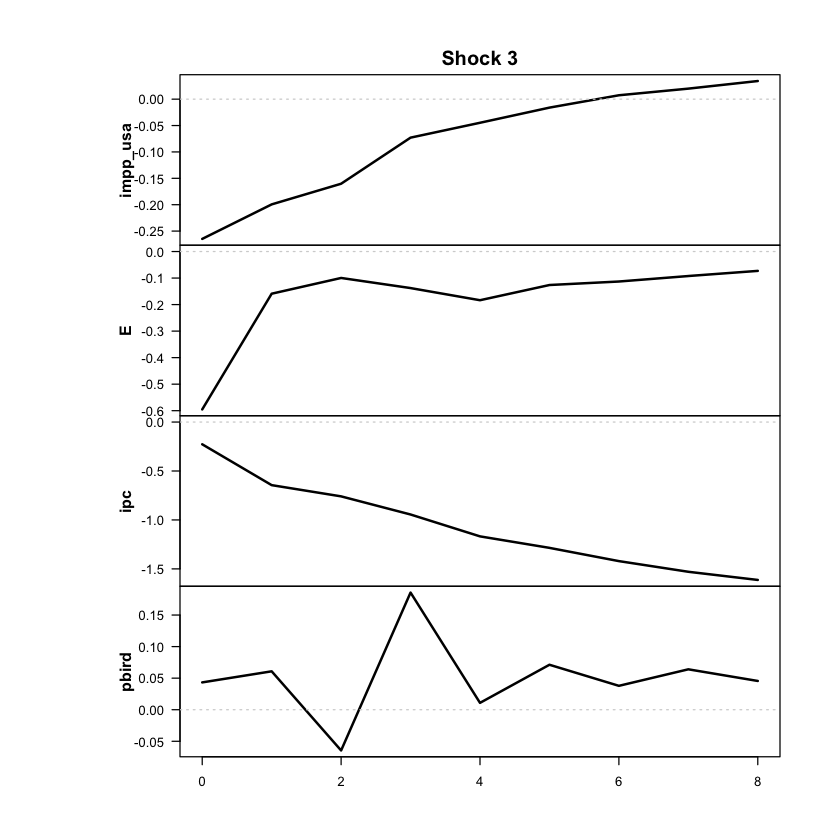

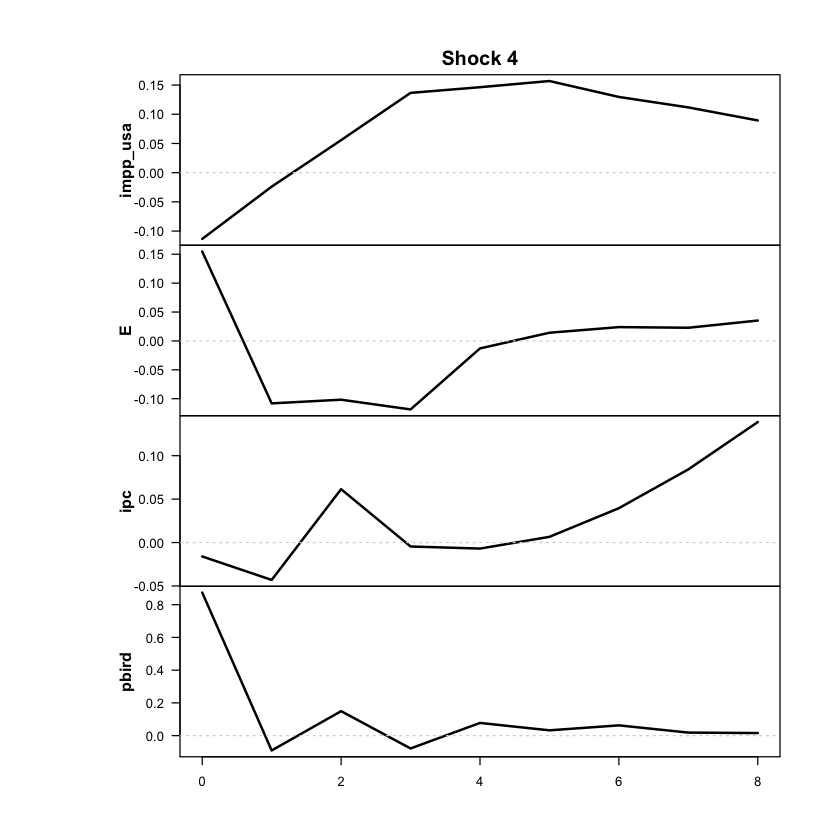

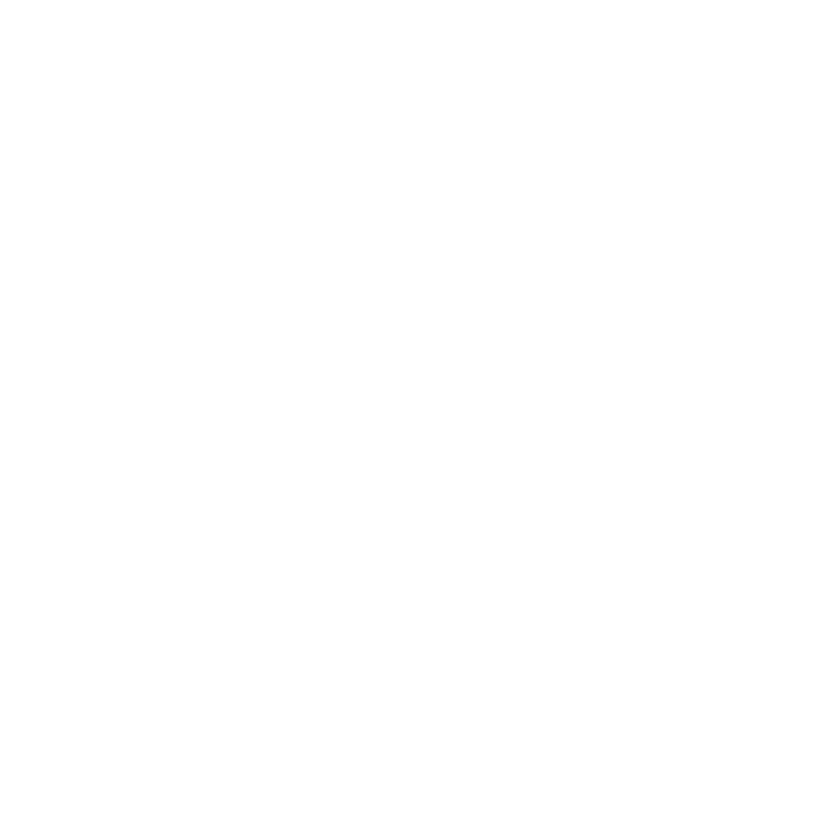

In [65]:
res <- run_mlogit(
  data = df_ERPT_Arg,
  endog = c("impp_usa","E","ipc","pbird"),
  periodicity = 'trimestral', # 'trimestral' o 'anual'
  feature_lag = 3,
  n_regimes = 3,
  cumulative = TRUE,
  thr_var = 'ipc', # 'ipc'
  thr_lag = 1,
  shock_var = 'E', # 'E'
  response_vars = c('ipc'), # c("impp_usa","ipc","pbird")
  run_tests = FALSE, # ejecuta e imprime tests: portmonteau, descomposición histórica y GEFVD
  irf_horizons = NULL, # Max períodos hacia los que mirar adelante en IRF (NULL = 2 años, default = 2 años)
  irf_shocks = 1, # Shocks unitarios irf (default 1)
  diagnostic_plots = TRUE, # Imprimir plots de diagnostico? TRUE o FALSE (default FALSE)
  nrounds = 500, # Cantidad de iteraciones - para ver resultados poco confiables rápido poner bajito, si no dejar en 500 o incluso 1000 (default 500)
  load_presaved = FALSE
)
#Correr los siguientes en celdas aparte
#print_girf(res) #Si querés ver los resultados de GIRF, descomentame
#print_irf(res) #Si querés ver los resultados de IRF lineal, descomentame
# OJO: A ESTA HAY QUE PASARLE LOS MISMOS PARÁMETROS QUE A RUN_VLSTAR!!
#run_tests_sstvar(res, response_vars = c('ipc'), cumulative = TRUE, irf_horizons = NULL, irf_shocks = 1, nrounds = 1)

In [66]:
ic_mlogit3_p3 <- criterios_info(res, "MLOGIT 3 reg p=3")
print(ic_mlogit3_p3)

            modelo regimenes parametros   loglik    AIC     HQ  BIC
1 MLOGIT 3 reg p=3         3        190 -1172.71 2725.4 3005.2 3424


In [67]:
resumen_modelo(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"))

Modelo: mlogit | regímenes: 3 | rezagos: 3 | errores: Gaussian 
Transición mlogit (parámetros gamma, escalados): -0.336, -0.316, -1.88, -8.128 
Cambios de régimen dominante según la inflación de t-1:
Trimestres por régimen (régimen de mayor peso): régimen 1 = 0 | régimen 2 = 0 | régimen 3 = 292 

Promedio observado de cada variable en los trimestres de cada régimen
(variación trimestral en %, a partir de las diferencias logarítmicas):
         Régimen 1 Régimen 2 Régimen 3
impp_usa       NaN       NaN      0.73
E              NaN       NaN     12.12
ipc            NaN       NaN     13.39
pbird          NaN       NaN      0.55


In [68]:
explorar_optimos(res, n = 20)
# Descartar los óptimos con cov_casi_singular o raiz_casi_unit = TRUE.

umbral_trim_pct: umbral(es) en % trimestral (logístico y TVAR; vacío en mlogit) | gamma: solo logístico | gl_student: grados de libertad (solo errores t)
 trim_por_regimen: trimestres en que domina cada régimen (1/2/...)
 raiz_casi_unit / cov_casi_singular / descartar: TRUE = sstvars avisó un problema; no usar ese óptimo

 which_largest  loglik umbral_trim_pct gamma gl_student trim_por_regimen
             1 -815.34              NA    NA         NA        28/220/44
             2 -873.09              NA    NA         NA        31/234/27
             3 -906.40              NA    NA         NA         260/30/2
             4 -908.97              NA    NA         NA         264/28/0
             5 -910.25              NA    NA         NA        241/20/31
             6 -910.98              NA    NA         NA         41/251/0
             7 -912.40              NA    NA         NA         28/264/0
             8 -913.66              NA    NA         NA        50/198/44
             9 -917

In [69]:
print(res$tvar_model)   # fijarse si aparece algún aviso (Warning)

mlogit Gaussian STVAR model, reduced form model, no AR_constraints, no mean_constraints, 
  p = 3, M = 3, d = 4, #parameters = 190, #observations = 292 x 4
  Switching variables: ipc with 1 lag.

Regime 1 
Weight params: -0.34, -0.32 
Regime means: -0.60,  4.98,  2.56,  4.40

   Y      phi0          A1                                 A2                  
1 y1 = [  0.30 ] + [  0.06 -0.02 -0.12 -0.24 ] y1.1 + [ -0.03  0.37  0.12 -0.06
2 y2   [  0.12 ]   [  0.12  0.80 -0.06  0.01 ] y2.1   [ -0.12  0.11  0.51  0.03
3 y3   [ -0.01 ]   [ -0.10 -0.01  0.24  0.25 ] y3.1   [ -0.01  0.14  0.74 -0.33
4 y4   [ -0.02 ]   [  0.09  0.09  0.07  0.26 ] y4.1   [ -0.04  0.40  0.20  0.08
                A3                              Omega                     1/2
1 ] y1.2 + [  0.24 -0.13  0.08 -0.16 ] y1.3 + [  0.28  0.25  0.07 -0.16 ]    
2 ] y2.2   [ -0.11 -0.08 -0.09 -0.11 ] y2.3   [  0.25  1.13  0.37  0.13 ]    
3 ] y3.2   [  0.03  0.06  0.05 -0.15 ] y3.3   [  0.07  0.37  0.13 -0.05 ]    
4 ] y4.2   

In [70]:
shock_mlogit3_p3 <- identificar_shock_cambiario(res, endog = c("impp_usa", "E", "ipc", "pbird"))
# Confirmar que mueve mucho a E y poco a ipc; si no, poner el número a mano:
# shock_mlogit3_p3 <- 2
shock_mlogit3_p3

Efecto de impacto de cada shock (unidades originales):
          shock
respuesta  shock_1 shock_2 shock_3 shock_4
  impp_usa  0.0009  0.0092 -0.0105 -0.0040
  E        -0.0065 -0.0716 -0.2043  0.0470
  ipc       0.0100 -0.0319 -0.0647 -0.0040
  pbird     0.0003  0.0061  0.0017  0.0308

Participación de E en el efecto de cada shock:
shock_1 shock_2 shock_3 shock_4 
   0.41    0.57    0.86    0.17 

ERPT de impacto de cada shock (ipc/E):
shock_1 shock_2 shock_3 shock_4 
 -1.543   0.445   0.317  -0.086 

>>> Shock sugerido como cambiario: 3 (confirmalo: debe mover mucho a E y poco a ipc )


Shock 3 
      3

### ERPT — mlogit3 p3

Correr solo si el modelo pasó el diagnóstico.

In [71]:
out_impp_usa_mlogit3_p3 <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_mlogit3_p3)

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 3...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 0 | régimen 2 = 0 | régimen 3 = 3 
Shock usado:3| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

  horizonte reg_1_original reg_2_original reg_3_original
1         0            NaN            NaN         0.3166
2         1            NaN            NaN         0.7639
3         2            NaN            NaN         0.9155
4         3            NaN            NaN         1.1694
5         4            NaN            NaN         1.3714
6         5            NaN            NaN         1.5153
7         6            NaN            NaN         1.6708
8         7            NaN            NaN         1.7985
9         8            NaN            NaN         1.9105


In [72]:
out_impp_usa_mlogit3_p3_acum <- erpt_historia(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"), shock_num = shock_mlogit3_p3,
                      definicion = "acumulado")

Estimando 292 GIRFs (una por trimestre), 1000 simulaciones cada una...

Using 9 cores to estimate one GIRF for 1 structural shocks, each based on 1000 Monte Carlo repetitions.

Estimating GIRFs for structural shock 3...

Finished!




Trimestres dominados por cada régimen (peso > 0.9): régimen 1 = 0 | régimen 2 = 0 | régimen 3 = 3 
Shock usado:3| Factor de conversión a unidades originales (sd_ipc / sd_E): 0.8299

  horizonte reg_1_original reg_2_original reg_3_original
1         0            NaN            NaN         0.3166
2         1            NaN            NaN         0.5966
3         2            NaN            NaN         0.6348
4         3            NaN            NaN         0.7049
5         4            NaN            NaN         0.7315
6         5            NaN            NaN         0.7417
7         6            NaN            NaN         0.7575
8         7            NaN            NaN         0.7732
9         8            NaN            NaN         0.7855


Transición mlogit: cambios de régimen dominante (inflación trimestral de t-1):
Trimestres por régimen (mayor peso): régimen 1 = 0 | régimen 2 = 0 | régimen 3 = 292 


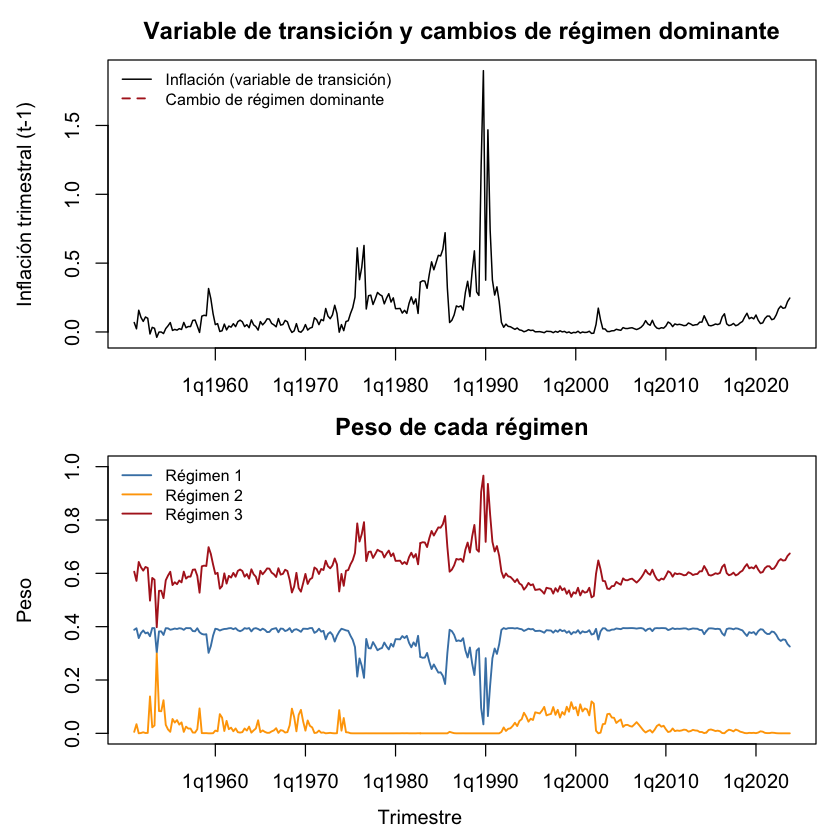

In [73]:
graficar_transicion(res, data = df_ERPT_Arg, endog = c("impp_usa", "E", "ipc", "pbird"),
                    archivo = "transicion_impp_usa_mlogit3_p3_sincap")

## Comparación de criterios (3 regímenes)

Para comparar con 2 regímenes, agregar a mano las filas de la otra notebook (TVAR p=2: loglik −896,09, AIC 1978,2, HQ 2115,3, BIC 2320,4; TVAR p=3: −861,69, 1973,4, 2157,5, 2433,0).

In [74]:
rbind(ic_tvar3_p2, ic_tvar3_p3, ic_mlogit3_p2, ic_mlogit3_p3)

modelo,regimenes,parametros,loglik,AIC,HQ,BIC
<chr>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
TVAR 3 reg p=2,3,140,-827.16,1934.3,2140.7,2449.5
TVAR 3 reg p=3,3,188,-777.18,1930.4,2207.2,2621.6
MLOGIT 3 reg p=2,3,142,-883.02,2050.0,2259.3,2572.6
MLOGIT 3 reg p=3,3,190,-1172.71,2725.4,3005.2,3424.0


# TEST de autocorrelación y de heterocedasticidad

Fuente: https://rdrr.io/cran/sstvars/man/Portmanteau_test.html

In [75]:
portmanteau_guardados <- function(data, rezagos_test = c(8, 12), carpeta = "models") {
  archivos <- list.files(carpeta, pattern = "\\.rds$", full.names = TRUE)
  archivos <- archivos[!grepl("^structured_", basename(archivos))]
  pval <- function(t) {
    nm <- grep("p_val|pval|p.val", names(t), value = TRUE)
    if (length(nm)) as.numeric(t[[nm[1]]]) else NA
  }
  etiqueta <- function(m) {
    wf <- m$model$weight_function
    tipo <- switch(if (is.null(wf)) "" else wf,
                   threshold = "TVAR", logistic = "VLSTAR", mlogit = "MLOGIT", "?")
    cd <- m$model$cond_dist
    if (!is.null(cd) && cd != "Gaussian") tipo <- paste0(tipo, "-t")
    tipo
  }
  filas <- list()
  for (f in archivos) {
    m <- tryCatch(readRDS(f), error = function(e) NULL)
    if (is.null(m) || is.null(m$data) || is.null(m$model)) next
    Y <- as.matrix(m$data); vars <- colnames(Y)
    if (!all(vars %in% names(data)) || nrow(data) != nrow(Y)) next
    X <- as.matrix(data[, vars]); X <- sweep(X, 2, apply(X, 2, sd, na.rm = TRUE), "/")
    if (!isTRUE(all.equal(unname(X), unname(Y), tolerance = 1e-6))) next
    for (L in rezagos_test) {
      ac <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "autocorr"), error = function(e) NULL)
      hs <- tryCatch(Portmanteau_test(m, nlags = L, which_test = "het.sked"), error = function(e) NULL)
      filas[[length(filas) + 1]] <- data.frame(
        commodity = vars[1],
        modelo    = etiqueta(m),
        regimenes = m$model$M, rezagos = m$model$p, rezagos_test = L,
        p_autocorr = round(if (is.null(ac)) NA else pval(ac), 3),
        p_heterosc = round(if (is.null(hs)) NA else pval(hs), 3))
    }
  }
  tab <- do.call(rbind, filas)
  tab <- tab[order(tab$commodity, tab$modelo, tab$regimenes, tab$rezagos, tab$rezagos_test), ]
  print(tab, row.names = FALSE)
  invisible(tab)
}

# Solo los modelos con impp_usa (los viejos de commodities quedan afuera)
port_sincap <- portmanteau_guardados(df_ERPT_Arg)
port_impp <- port_sincap[port_sincap$commodity == "impp_usa", ]
print(port_impp, row.names = FALSE)

  commodity   modelo regimenes rezagos rezagos_test p_autocorr p_heterosc
   impp_usa   MLOGIT         3       2            8      0.000      0.000
   impp_usa   MLOGIT         3       2           12      0.005      0.007
   impp_usa   MLOGIT         3       3            8      0.000      0.000
   impp_usa   MLOGIT         3       3           12      0.008      0.000
   impp_usa     TVAR         2       2            8      0.008      0.000
   impp_usa     TVAR         2       2           12      0.123      0.000
   impp_usa     TVAR         2       3            8      0.023      0.000
   impp_usa     TVAR         2       3           12      0.304      0.000
   impp_usa     TVAR         3       2            8      0.017      0.000
   impp_usa     TVAR         3       2           12      0.011      0.001
   impp_usa     TVAR         3       3            8      0.028      0.000
   impp_usa     TVAR         3       3           12      0.083      0.008
   impp_usa   TVAR-t         2       2